# AgroTech - Crop Price Forecasting
**Workflow (we stop after Part 2 until you verify):**
1. Setup and data importation
2. Data wrangling (cleaning, with the tests that chose each rule)  **<- this notebook ends here**
3. Exploration (EDA): season, stationarity, memory
4. Train / validation split (by time)
5. Baseline model
6. Fit the model (ACF / PACF read on training data only)
7. Check how it trains (residuals, PACF of residuals, metrics)
8. Validate: test on the validation months, direction table (up / down), and predict

Rules: no guessing, the data decides. Each step is a small function followed by a short cell that runs it.

# PART 1 - Setup and data importation

In [1]:
# ===== 1.1  Libraries and settings =====
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = r"C:\Users\LENOVO\Desktop\AGRITECH PROJECT\price data.xlsx"    # <- your file
SHEET     = "National Avg"
MONTHS    = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
START, END = "2012-01-01", "2023-12-01"
CALENDAR  = pd.date_range(START, END, freq="MS")                            # every month we expect

In [2]:
# ===== 1.2  Functions: load and inspect =====
def load_raw(file, sheet=SHEET):
    """Read the KNBS sheet. One row per commodity per year, months across."""
    raw = pd.read_excel(file, sheet_name=sheet)
    return raw.rename(columns={"Commodity Name Harmonised": "crop"})

def inspect_raw(raw):
    """Quick look: size, years, commodities, units, blanks."""
    print("rows, columns:", raw.shape)
    print("years:", raw["year"].min(), "to", raw["year"].max())
    print("commodities:", raw["crop"].nunique())
    print("\nunits:\n", raw["unit"].value_counts().to_string())
    print("\nblank cells per month column:\n", raw[MONTHS].isna().sum().to_string())

In [3]:
# ===== 1.3  Run =====
raw = load_raw(DATA_FILE)
inspect_raw(raw)
raw.head()

rows, columns: (1221, 16)
years: 2012 to 2023
commodities: 415

units:
 unit
kg         1101
head         65
lt           20
tray         14
ext bag      10
tonne         3
bag           1
piece         1

blank cells per month column:
 jan    423
feb    390
mar    442
apr    404
may    358
jun    398
jul    412
aug    617
sep    630
oct    681
nov    525
dec    482


,year,crop,unit,kg,jan,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec
0,2012,avocado,kg,90,2232.083333,2438.819444,2252.013889,1990.608974,1956.549020,1971.000000,1740.892857,1634.264706,1881.416667,1860.347222,2059.737654,2247.129630
1,2012,banana (cooking/plantain),kg,22,511.318673,531.127451,570.416667,542.938725,565.707843,589.050926,541.392157,571.871142,504.549020,625.821637,568.214912,545.453704
2,2012,banana (ripe),kg,14,616.460784,569.609259,635.132937,642.053571,628.441667,658.989583,583.316667,541.996528,568.619792,635.671569,596.411765,581.018275
3,2012,beans (canadian wonder),kg,90,5564.768519,5661.180556,5811.666667,6323.888889,6299.772727,6574.431818,5968.472222,5728.113426,5841.923077,5807.179487,5660.000000,5594.871795
4,2012,beans (dolichos-njahi),kg,90,6886.964286,7029.620370,7267.933333,7337.222222,7514.384615,8269.285714,7719.027778,7425.694444,6902.777778,7402.222222,7511.025641,7970.916667


# PART 2 - Data wrangling
Steps: (2.1) one row per crop per month -> (2.2) keep crops with enough data -> (2.3) fix wrong prices ->
(2.4) test the best way to fill gaps -> (2.5) fill gaps -> (2.6) use variety prices for the 2021 holes -> (2.7) check and save.

In [4]:
# ===== 2.1  Functions: months across -> one row per crop per month =====
def reshape_long(raw):
    """Months across -> one row per crop per month, with a real date. Blank prices are dropped."""
    long = raw.melt(id_vars=["year", "crop", "unit", "kg"], value_vars=MONTHS,
                    var_name="month", value_name="price")
    long["date"] = pd.to_datetime(long["year"].astype(str) + "-" + long["month"], format="%Y-%b")
    return long.dropna(subset=["price"])

In [5]:
# ===== 2.2  Functions: keep commodities with enough data =====
def select_crops(long, min_months=60, max_missing=0.20, max_trailing=6):
    """Rules: >= min_months priced months, <= max_missing of its months empty,
       last price within max_trailing survey months of the end.
       Returns (clean rows, report with one line per commodity)."""
    survey_months = pd.DatetimeIndex(sorted(long["date"].unique()))
    rows = []
    for crop, g in long.groupby("crop"):
        dates = pd.DatetimeIndex(g["date"].unique())
        span = (survey_months >= dates.min()).sum()
        missing = 1 - len(dates) / span
        trailing = int((survey_months > dates.max()).sum())
        keep = len(dates) >= min_months and missing <= max_missing and trailing <= max_trailing
        rows.append({"crop": crop, "priced": len(dates), "first": dates.min().strftime("%Y-%m"),
                     "last": dates.max().strftime("%Y-%m"), "missing_%": round(missing * 100, 1),
                     "trailing_missing": trailing, "keep": keep})
    report = pd.DataFrame(rows).sort_values(["keep", "priced"], ascending=False)
    clean = long[long["crop"].isin(report.loc[report["keep"], "crop"])]
    return clean.sort_values(["crop", "date"]).reset_index(drop=True), report

In [6]:
# ===== 2.2  Run =====
long = reshape_long(raw)
clean, report = select_crops(long)
print("commodities kept:", clean["crop"].nunique(), "of", report.shape[0], "| rows:", len(clean))
print("survey months with any price:", clean["date"].nunique())
report[report["keep"]].head(10)

commodities kept: 38 of 415 | rows: 4719
survey months with any price: 124


,crop,priced,first,last,missing_%,trailing_missing,keep
16,banana (cooking/plantain),124,2012-01,2023-12,0.0,0,True
17,banana (ripe),124,2012-01,2023-12,0.0,0,True
23,beans (canadian wonder),124,2012-01,2023-12,0.0,0,True
26,beans (mwezi moja),124,2012-01,2023-12,0.0,0,True
27,beans (mwitemania),124,2012-01,2023-12,0.0,0,True
29,beans (rosecoco),124,2012-01,2023-12,0.0,0,True
38,cabbages,124,2012-01,2023-12,0.0,0,True
43,capsicums,124,2012-01,2023-12,0.0,0,True
44,carrots,124,2012-01,2023-12,0.0,0,True
46,cassava fresh,124,2012-01,2023-12,0.0,0,True


In [7]:
# ===== 2.3  Functions: fix wrong prices (rules we agreed) =====
# crop: (old pack, new pack, first month of the new pack)
SWITCHES = {
    "irish potato (white)": ("kg 110", "kg 50", "2017-07-01"),
    "irish potato (red)":   ("kg 110", "kg 50", "2017-07-01"),
    "lettuce":              ("kg 51",  "kg 50", "2021-05-01"),
    "peas, fresh":          ("kg 51",  "kg 50", "2021-01-01"),
    "sweet potato":         ("kg 98",  "kg 99", "2021-05-01"),
    "green maize":          ("ext bag 115", "kg 1", "2021-05-01"),
}
SPIKE_Z, SPIKE_SIZE, STALE_RUN = 8, 0.5, 3      # spike: very unusual AND >= 50% jump | copied: same price 3+ months

def to_price_per_kg(clean):
    d = clean.copy()
    d["pack"] = d["unit"].fillna("?").astype(str) + " " + d["kg"].astype(str)
    d["price_per_kg"] = d["price"] / d["kg"]            # eggs: kg = 1, so this is per tray
    return d

def drop_wrong_rows(d, audit):
    """A: per-piece rows. B: extra per-kg rows. C: wrong pack around a pack switch. Every removal is logged."""
    def log(rows, why):
        for _, r in rows.iterrows():
            audit.append({"crop": r["crop"], "date": r["date"].strftime("%Y-%m"), "pack": r["pack"],
                          "price_per_kg": round(r["price_per_kg"], 2), "reason": why})
    x = d[d["unit"] == "piece"]; log(x, "quoted per piece"); d = d.drop(x.index)
    other = d[d["kg"] != 1].groupby("crop").size()
    x = d[(d["kg"] == 1) & d["crop"].map(other).notna() & (d["crop"] != "green maize")]
    log(x, "extra per-kg row"); d = d.drop(x.index)
    for crop, (old, new, sw) in SWITCHES.items():
        sw = pd.Timestamp(sw)
        bad = d[(d["crop"] == crop) & (((d["pack"] == old) & (d["date"] >= sw)) | ((d["pack"] == new) & (d["date"] < sw)))]
        log(bad, "wrong pack for this period"); d = d.drop(bad.index)
    return d

def remove_spikes_and_copies(s, crop, audit):
    """s = one crop's monthly line. Remove a spike that reverses next month, then prices copied 3+ months."""
    chg = np.log(s / s.shift(1)); c = chg.dropna()
    z = (chg - c.median()) / (np.median(np.abs(c - c.median())) * 1.4826)
    size = (s / s.shift(1) - 1).abs()
    cand = z.index[(z.abs() >= SPIKE_Z) & (z.shift(-1).abs() >= SPIKE_Z)
                   & (np.sign(z) != np.sign(z.shift(-1))) & (size >= SPIKE_SIZE)]
    last = None
    for dt in cand:
        if last is not None and dt == last + pd.DateOffset(months=1):
            continue
        audit.append({"crop": crop, "date": dt.strftime("%Y-%m"), "pack": "", "price_per_kg": round(s[dt], 2),
                      "reason": "spike that reverses next month"})
        s[dt] = np.nan; last = dt
    r = s.round(6)
    for _, run in r.groupby((r != r.shift()).cumsum()):
        if len(run) >= STALE_RUN and run.notna().all():
            for dt in run.index[1:]:
                audit.append({"crop": crop, "date": dt.strftime("%Y-%m"), "pack": "", "price_per_kg": round(s[dt], 2),
                              "reason": "same price repeated (copied)"})
                s[dt] = np.nan
    return s

def fix_prices(clean):
    """Returns (fixed: crop, date, price_per_kg) and the audit list of everything we removed."""
    audit = []
    d = drop_wrong_rows(to_price_per_kg(clean), audit)
    monthly = d.groupby(["crop", "date"])["price_per_kg"].mean().reset_index()
    out = []
    for crop, g in monthly.groupby("crop"):
        s = g.set_index("date")["price_per_kg"].asfreq("MS")
        s = remove_spikes_and_copies(s, crop, audit)
        out.append(s.dropna().rename("price_per_kg").reset_index().assign(crop=crop))
    return pd.concat(out)[["crop", "date", "price_per_kg"]].reset_index(drop=True), pd.DataFrame(audit)

def get_series(df, crop):
    """One crop as a full monthly line (empty months = NaN)."""
    return df[df["crop"] == crop].set_index("date")["price_per_kg"].reindex(CALENDAR)

In [8]:
# ===== 2.3  Run =====
fixed, audit = fix_prices(clean)
print("prices kept:", len(fixed), "| rows removed:", len(audit))
print(audit["reason"].value_counts().to_string())

prices kept: 4565 | rows removed: 154
reason
same price repeated (copied)      79
extra per-kg row                  59
spike that reverses next month     6
quoted per piece                   5
wrong pack for this period         5


In [9]:
# ===== 2.4  Test: which way of filling a gap is best? (hide known months, fill them, measure the error) =====
from statsmodels.tsa.seasonal import STL
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

GAP_LENGTHS, REPEATS, SEED = [1, 3, 5, 12], 20, 42

def fill_linear(s):       return np.exp(np.log(s).interpolate(limit_area="inside"))          # straight line
def fill_same_month(s):   return s.fillna(s.groupby(s.index.month).transform("mean"))        # same month, other years
def fill_trend_season(s):
    ls = np.log(s); trend = ls.rolling(12, center=True, min_periods=6).mean().interpolate(limit_area="inside")
    return np.exp(ls.fillna(trend + (ls - trend).groupby(ls.index.month).transform("mean")))
def fill_stl(s, rounds=5):
    ls = np.log(s); miss = ls.isna(); cur = ls.interpolate(limit_area="inside").ffill().bfill()
    for _ in range(rounds):
        r = STL(cur, period=12, robust=True).fit(); cur = cur.where(~miss, r.trend + r.seasonal)
    return np.exp(cur)
METHODS = {"linear": fill_linear, "same_month_avg": fill_same_month, "trend+season": fill_trend_season, "STL": fill_stl}

def mask_test(fixed, crops, lengths=GAP_LENGTHS, repeats=REPEATS, seed=SEED):
    """Hide blocks of real prices, fill them with each method, record the % error."""
    rng, out = np.random.default_rng(seed), []
    for crop in crops:
        s = get_series(fixed, crop); ok = s.notna().values; n = len(s)
        for L in lengths:
            starts = [i for i in range(1, n - L) if ok[i:i + L].all() and ok[:i].any() and ok[i + L:].any()]
            for i in rng.choice(starts, size=min(repeats, len(starts)), replace=False):
                hidden = s.copy(); hidden.iloc[i:i + L] = np.nan
                for name, fn in METHODS.items():
                    guess = fn(hidden).iloc[i:i + L]
                    out.append({"crop": crop, "gap": L, "method": name,
                                "mape": float((abs(guess - s.iloc[i:i + L]) / s.iloc[i:i + L]).mean() * 100)})
    return pd.DataFrame(out)

def compare_fill_methods(fixed):
    """Test on crops with no gaps of their own. Returns typical error table + paired test of linear vs rivals."""
    all_blank = CALENDAR[~CALENDAR.isin(fixed["date"])]
    gaps_own = [c for c in sorted(fixed["crop"].unique())
                if not (get_series(fixed, c).isna() & ~CALENDAR.isin(all_blank)).any()]   # no empty months of its own
    res = mask_test(fixed, gaps_own)
    table = res.pivot_table(index="gap", columns="method", values="mape", aggfunc="median").round(1)
    per_crop = res.groupby(["gap", "crop", "method"])["mape"].mean().unstack("method")
    rows = []
    for L in GAP_LENGTHS:
        for rival in ["trend+season", "STL", "same_month_avg"]:
            diff = per_crop.loc[L]["linear"] - per_crop.loc[L][rival]
            rows.append({"gap": L, "rival": rival, "crops_linear_wins": f"{int((diff < 0).sum())} of {len(diff)}",
                         "median_diff": round(diff.median(), 2), "p": wilcoxon(diff).pvalue})
    paired = pd.DataFrame(rows); paired["p_holm"] = multipletests(paired["p"], method="holm")[1].round(4)
    return len(gaps_own), table, paired.drop(columns="p")

In [10]:
# ===== 2.4  Run (about 2-4 minutes) =====
print("months where every crop is blank:", int((~CALENDAR.isin(fixed["date"])).sum()))
n_crops, table, paired = compare_fill_methods(fixed)
print("crops used in the test:", n_crops)
print("\nTYPICAL error % (lower is better), by gap length:")
print(table.to_string())
print("\nnegative median_diff = the straight line has the smaller error:")
print(paired.to_string(index=False))

months where every crop is blank: 22
crops used in the test: 23

TYPICAL error % (lower is better), by gap length:
method   STL  linear  same_month_avg  trend+season
gap                                               
1        7.1     4.2            18.9           6.3
3        8.9     6.1            17.6           7.7
5        9.5     7.7            18.0           8.2
12      10.5     9.7            17.9           9.8

negative median_diff = the straight line has the smaller error:
 gap          rival crops_linear_wins  median_diff  p_holm
   1   trend+season          19 of 23        -1.44  0.0038
   1            STL          20 of 23        -2.55  0.0015
   1 same_month_avg          23 of 23       -13.77  0.0000
   3   trend+season          17 of 23        -0.86  0.0123
   3            STL          20 of 23        -2.11  0.0015
   3 same_month_avg          23 of 23       -12.36  0.0000
   5   trend+season          14 of 23        -0.44  1.0000
   5            STL          17 of 23     

**Decision from 2.4 (the data decided):** the straight line on log price is best or tied for gaps of 1 to 5 months, so we fill gaps of **5 months or fewer** with it.
Longer gaps are left empty. Every filled month is flagged.

In [11]:
# ===== 2.5  Functions: fill short gaps =====
MAX_GAP = 5

def fill_gaps(df, max_gap=MAX_GAP):
    """Straight line on log price inside gaps <= max_gap months. Returns crop, date, price_per_kg, imputed."""
    out = []
    for crop in sorted(df["crop"].unique()):
        s = get_series(df, crop); miss = s.isna()
        run_len = miss.groupby((~miss).cumsum()).transform("sum")
        line = np.exp(np.log(s).interpolate(limit_area="inside"))
        fill_me = miss & (run_len <= max_gap) & line.notna()
        filled = s.copy(); filled[fill_me] = line[fill_me]
        out.append(pd.DataFrame({"crop": crop, "date": s.index, "price_per_kg": filled.values, "imputed": fill_me.values}))
    return pd.concat(out, ignore_index=True)

def find_holes(filled):
    """Gaps that are still empty after filling: where, how long."""
    rows = []
    for crop in sorted(filled.loc[filled["price_per_kg"].isna(), "crop"].unique()):
        g = filled[filled["crop"] == crop].reset_index(drop=True)
        empty = g["price_per_kg"].isna()
        for _, idx in g[empty].groupby((~empty).cumsum()[empty]).groups.items():
            rows.append({"crop": crop, "hole_from": g.loc[idx.min(), "date"].strftime("%Y-%m"),
                         "hole_to": g.loc[idx.max(), "date"].strftime("%Y-%m"), "hole_months": len(idx)})
    return pd.DataFrame(rows)

In [12]:
# ===== 2.5  Run =====
filled = fill_gaps(fixed)
holes = find_holes(filled)
print("months filled by straight line:", int(filled["imputed"].sum()))
print("\nholes longer than 5 months (still empty):")
print(holes.to_string(index=False))

months filled by straight line: 858

holes longer than 5 months (still empty):
       crop hole_from hole_to  hole_months
    avocado   2021-06 2021-12            7
       eggs   2021-02 2022-01           12
green grams   2021-02 2021-12           11
 groundnuts   2021-02 2021-12           11
      wheat   2020-03 2020-10            8


**2.6 - The 2021 holes.** In 2021 the survey replaced plain *green grams, groundnuts, eggs, avocado* with variety rows.
We tested each variety as a stand-in with a **join test**: the price must not jump at either end by more than the crop's normal 90th-percentile move.
Accepted (data decided): green grams = average of varieties, groundnuts = average of varieties, eggs = "eggs (exotic/grade)" only, avocado = "avocado (fuerte)" only.
Wheat has no stand-in, so it keeps its 8-month hole and is excluded from modelling for now.

In [13]:
# ===== 2.6  Functions: join test and substitutes =====
CANDIDATES = {"green grams": {"average": None}, "groundnuts": {"average": None},
              "eggs": {"average": None, "exotic only": "eggs (exotic/grade)"},
              "avocado": {"average": None, "fuerte only": "avocado (fuerte)"}}
SUBSTITUTES = {"green grams": None, "groundnuts": None, "eggs": "eggs (exotic/grade)", "avocado": "avocado (fuerte)"}
PCT = 0.90

def variety_wide(raw, crop):
    """Variety prices per kg: one column per variety, one row per month."""
    v = raw[raw["crop"].str.startswith(crop + " (", na=False)]
    lg = reshape_long(v); lg["per_kg"] = lg["price"] / lg["kg"]
    return lg.pivot_table(index="date", columns="crop", values="per_kg", aggfunc="mean")

def _months_between(a, b): return (b.year - a.year) * 12 + (b.month - a.month)
def _normal_move(plain, h): return np.log(plain / plain.shift(h)).dropna().abs().quantile(PCT)

def join_test(fixed, raw, holes, candidates=CANDIDATES):
    """Does each variety option join the plain price without an unusual jump at both ends?"""
    rows = []
    for crop, options in candidates.items():
        h = holes[holes["crop"] == crop].iloc[0]
        plain = get_series(fixed, crop); wide = variety_wide(raw, crop).reindex(plain.index)
        hole = plain.index[(plain.index >= pd.Timestamp(h["hole_from"] + "-01")) & (plain.index <= pd.Timestamp(h["hole_to"] + "-01"))]
        for name, col in options.items():
            cand = wide.mean(axis=1) if col is None else wide[col]
            used = [d for d in hole if pd.notna(cand[d])]
            b = plain[: used[0] - pd.DateOffset(months=1)].dropna()
            a = plain[used[-1] + pd.DateOffset(months=1):].dropna()
            j1 = np.log(cand[used[0]]) - np.log(b.iloc[-1]); n1 = _normal_move(plain, _months_between(b.index[-1], used[0]))
            j2 = np.log(a.iloc[0]) - np.log(cand[used[-1]]);  n2 = _normal_move(plain, _months_between(used[-1], a.index[0]))
            rows.append({"crop": crop, "option": name, "months_filled": len(used),
                         "join1_jump_%": round((np.exp(j1) - 1) * 100, 1), "join1_normal_%": round((np.exp(n1) - 1) * 100, 1),
                         "join2_jump_%": round((np.exp(j2) - 1) * 100, 1), "join2_normal_%": round((np.exp(n2) - 1) * 100, 1),
                         "ACCEPT": abs(j1) <= n1 and abs(j2) <= n2})
    return pd.DataFrame(rows)

def apply_substitutes(fixed, raw, holes, substitutes=SUBSTITUTES):
    """Put the accepted variety prices into the hole months. Returns (new table, the substituted months)."""
    new = []
    for crop, col in substitutes.items():
        plain = get_series(fixed, crop); wide = variety_wide(raw, crop).reindex(plain.index)
        cand = wide.mean(axis=1) if col is None else wide[col]
        h = holes[holes["crop"] == crop].iloc[0]
        in_hole = (plain.index >= pd.Timestamp(h["hole_from"] + "-01")) & (plain.index <= pd.Timestamp(h["hole_to"] + "-01"))
        use = in_hole & plain.isna().values & cand.notna().values
        new.append(pd.DataFrame({"crop": crop, "date": plain.index[use], "price_per_kg": cand[use].values}))
    subs = pd.concat(new, ignore_index=True)
    return pd.concat([fixed[["crop", "date", "price_per_kg"]], subs], ignore_index=True), subs

def label_source(filled2, subs):
    """Tag every month: real / straight_line / variety / empty."""
    is_sub = filled2.set_index(["crop", "date"]).index.isin(subs.set_index(["crop", "date"]).index)
    filled2["source"] = np.where(filled2["price_per_kg"].isna(), "empty",
                        np.where(filled2["imputed"], "straight_line", np.where(is_sub, "variety", "real")))
    return filled2

In [14]:
# ===== 2.6  Run =====
print(join_test(fixed, raw, holes).to_string(index=False))          # the evidence for the choices above

fixed2, subs = apply_substitutes(fixed, raw, holes)
data = label_source(fill_gaps(fixed2), subs)
print("\nwhere every price comes from:")
print(data["source"].value_counts().to_string())

       crop      option  months_filled  join1_jump_%  join1_normal_%  join2_jump_%  join2_normal_%  ACCEPT
green grams     average             11          -1.1             9.9          -0.8             9.9    True
 groundnuts     average             11           2.4             8.8           1.0             8.8    True
       eggs     average             11           9.8             4.4          -8.8             5.9   False
       eggs exotic only             11          -3.1             4.4          -0.8             5.9    True
    avocado     average              7          15.2            20.2          17.0            20.2    True
    avocado fuerte only              7          -1.4            20.2          -8.8            20.2    True

where every price comes from:
source
real             4565
straight_line     859
variety            40
empty               8


# 2.7 - Final checks, picture, and save

In [15]:
# ===== 2.7  Functions: checks and picture =====
def check_clean_data(data, fixed):
    """Stops with an error if anything is not as we agreed."""
    assert data["crop"].nunique() == 38 and len(data) == 38 * len(CALENDAR)
    assert not data.duplicated(["crop", "date"]).any(), "duplicate crop-month"
    real = fixed.merge(data, on=["crop", "date"], suffixes=("_old", "_new"))
    assert np.allclose(real["price_per_kg_old"], real["price_per_kg_new"]), "a real price changed"
    assert (real["source"] == "real").all(), "a real price has the wrong label"
    assert data.loc[data["source"] == "empty", "crop"].unique().tolist() == ["wheat"], "only wheat may stay empty"
    assert (data["price_per_kg"].dropna() > 0).all(), "a price is zero or negative"
    print("ALL CHECKS PASSED")

def plot_data_quality(data):
    """One row per crop, one column per month: where is the price real, filled, variety, or empty?"""
    code_ = {"real": 0, "straight_line": 1, "variety": 2, "empty": 3}
    grid = data.assign(v=data["source"].map(code_)).pivot(index="crop", columns="date", values="v")
    order = (grid > 0).sum(axis=1).sort_values(ascending=False).index
    from matplotlib.colors import ListedColormap
    fig, ax = plt.subplots(figsize=(12, 9))
    ax.imshow(grid.loc[order].values, aspect="auto", interpolation="nearest",
              cmap=ListedColormap(["#e3e2de", "#2a78d6", "#1baf7a", "#e34948"]), vmin=0, vmax=3)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8)
    yrs = [i for i, d in enumerate(grid.columns) if d.month == 1]
    ax.set_xticks(yrs); ax.set_xticklabels([grid.columns[i].year for i in yrs])
    ax.set_title("Data quality: grey = real | blue = straight line | green = variety | red = empty", loc="left", fontweight="bold")
    plt.tight_layout(); plt.show()

ALL CHECKS PASSED


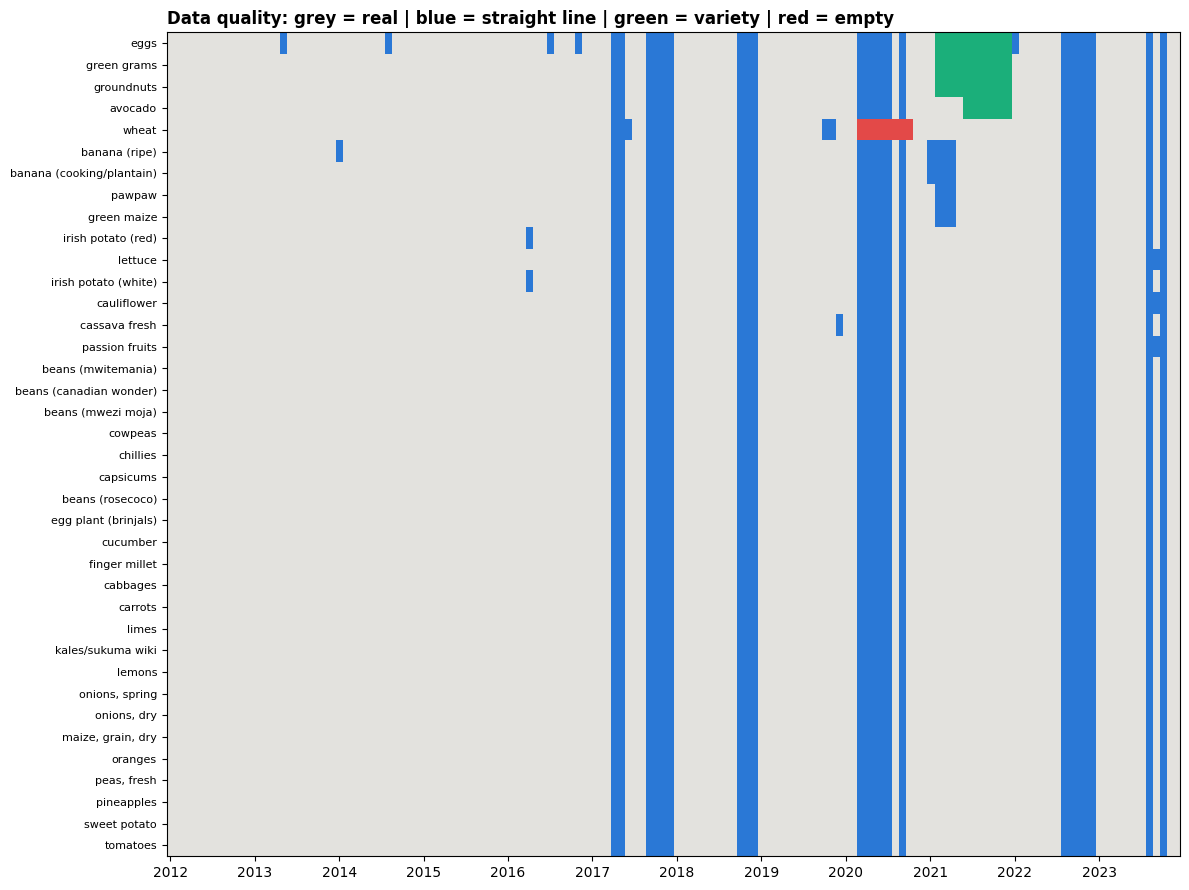

saved clean_prices.csv: (5472, 5)


,crop,date,price_per_kg,imputed,source
0,avocado,2012-01-01,24.800926,False,real
1,avocado,2012-02-01,27.097994,False,real
2,avocado,2012-03-01,25.022377,False,real
3,avocado,2012-04-01,22.117877,False,real
4,avocado,2012-05-01,21.739434,False,real


In [16]:
# ===== 2.7  Run =====
check_clean_data(data, fixed)
plot_data_quality(data)
data.to_csv("clean_prices.csv", index=False)          # later parts start by reading this file
print("saved clean_prices.csv:", data.shape)
data.head()

In [17]:
#part 3*Exploration (EDA): season, stationarity, memory*


In [18]:
# ===== 3.0  Setup and load =====
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests

SURFACE, INK, INK2, GRID, BLUE, GREY = "#fcfcfb", "#0b0b0b", "#52514e", "#e3e2de", "#2a78d6", "#cfcdc6"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False})

def load_clean(path="clean_prices.csv"):
    """Read the Part 2 file. Returns the full table and the crops with a complete line (wheat is left out)."""
    data = pd.read_csv(path, parse_dates=["date"])
    crops = sorted(c for c in data["crop"].unique() if data.loc[data["crop"] == c, "price_per_kg"].notna().all())
    return data, crops

def log_price(data, crop):
    """One crop's log price as a monthly line."""
    s = data[data["crop"] == crop].set_index("date")["price_per_kg"].astype(float)
    return np.log(s).asfreq("MS")

data, crops = load_clean()
print("crops for modelling:", len(crops), "| left out:", sorted(set(data["crop"]) - set(crops)))

crops for modelling: 37 | left out: ['wheat']


In [19]:
# ===== 3.1  Functions: summary table and the picture =====
def summary_table(data, crops):
    rows = []
    for c in crops:
        g = data[data["crop"] == c].set_index("date")
        p = g["price_per_kg"]; chg = np.log(p).diff().dropna().abs()
        rows.append({"crop": c, "real_%": round((g["source"] == "real").mean() * 100),
                     "first_price": round(p.iloc[0], 1), "last_price": round(p.iloc[-1], 1),
                     "times_higher": round(p.iloc[-1] / p.iloc[0], 1),
                     "typical_monthly_move_%": round((np.exp(chg.median()) - 1) * 100, 1)})
    return pd.DataFrame(rows)

def plot_all_prices(data, crops):
    n = len(crops); cols = 6; rows_ = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(16, 2.1 * rows_), sharex=True)
    for ax, c in zip(axes.flat, crops):
        g = data[data["crop"] == c].set_index("date")
        ax.plot(g.index, g["price_per_kg"], color=INK, lw=1)
        f = g[g["source"] != "real"]
        ax.scatter(f.index, f["price_per_kg"], s=5, color=BLUE, zorder=3)
        ax.set_title(c, loc="left", fontsize=8, fontweight="bold"); ax.tick_params(labelsize=7)
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    fig.suptitle("Price per kg, 2012-2023 (blue dots = filled months)", x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

                     crop  real_%  first_price  last_price  times_higher  typical_monthly_move_%
                    limes      85         43.9        75.0           1.7                    12.5
                  lettuce      84         55.6       101.2           1.8                     9.3
       irish potato (red)      84         32.9        53.0           1.6                     9.1
     irish potato (white)      84         34.0        46.0           1.4                     9.0
              cauliflower      84         70.2       117.4           1.7                     8.0
              peas, fresh      85         51.9        94.4           1.8                     7.7
                 tomatoes      85         53.3        67.7           1.3                     7.6
                 cucumber      85         47.5        78.7           1.7                     7.6
              green maize      83         21.2        62.2           2.9                     7.2
           onions, spring     

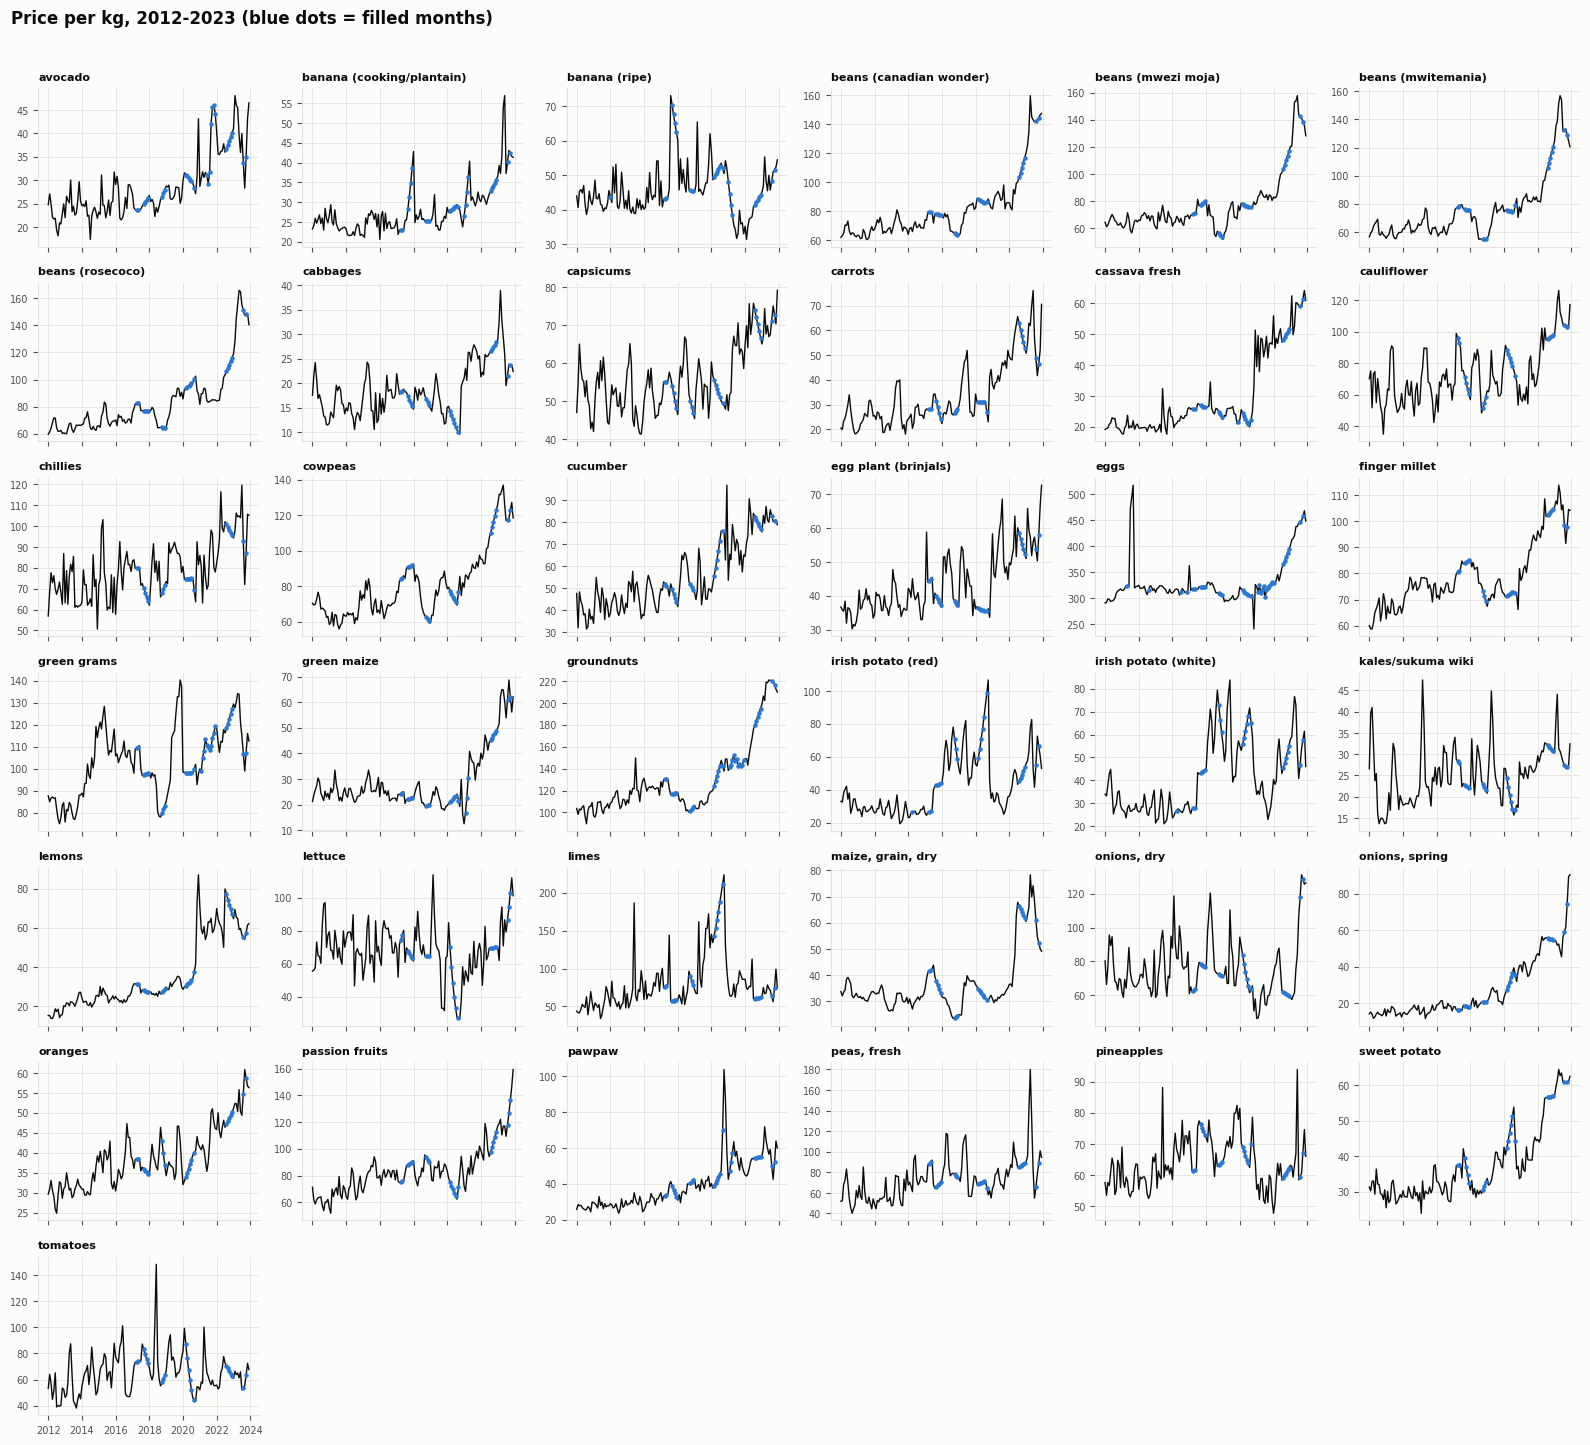

In [20]:
summary = summary_table(data, crops)
print(summary.sort_values("typical_monthly_move_%", ascending=False).to_string(index=False))
plot_all_prices(data, crops)

In [21]:
# ===== 3.2  Functions: season test =====
def season_table(data, crops):
    rows = []
    for c in crops:
        ls = log_price(data, c); r = STL(ls, period=12, robust=True).fit()
        strength = max(0, 1 - np.var(r.resid) / np.var(r.seasonal + r.resid))
        chg = ls.diff().dropna()
        p = kruskal(*[chg[chg.index.month == m].values for m in range(1, 13)]).pvalue
        by_m = chg.groupby(chg.index.month).mean()
        rows.append({"crop": c, "season_strength": round(strength, 2), "p_value": p,
                     "rises_most_in_month": int(by_m.idxmax()), "falls_most_in_month": int(by_m.idxmin())})
    t = pd.DataFrame(rows)
    t["p_holm"] = multipletests(t["p_value"], method="holm")[1]
    t["yearly_season"] = t["p_holm"] < 0.05
    return t.round({"p_value": 4, "p_holm": 4})

def plot_season_heatmap(data, crops, season):
    M = pd.DataFrame({c: log_price(data, c).diff().dropna().groupby(lambda d: d.month).mean() * 100 for c in crops}).T
    M = M.loc[season.sort_values("p_value")["crop"]]
    fig, ax = plt.subplots(figsize=(9, 11))
    im = ax.imshow(M.values, cmap="RdBu_r", vmin=-8, vmax=8, aspect="auto")
    ax.set_xticks(range(12)); ax.set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"])
    seas = season.set_index("crop")["yearly_season"]
    ax.set_yticks(range(len(M))); ax.set_yticklabels([("* " if seas[c] else "") + c for c in M.index], fontsize=9)
    ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.5, label="average change in that month (%)  red = rises, blue = falls")
    ax.set_title("Yearly pattern.  * = a real season (after the multiple-test correction)", loc="left", fontsize=11, fontweight="bold")
    fig.tight_layout(); plt.show()

                     crop  season_strength  p_value  rises_most_in_month  falls_most_in_month  p_holm  yearly_season
         beans (rosecoco)             0.52   0.0000                    3                    7  0.0007           True
              green maize             0.38   0.0000                    2                    7  0.0011           True
                  oranges             0.24   0.0000                    9                   10  0.0000           True
                 cucumber             0.38   0.0001                    3                    6  0.0041           True
       irish potato (red)             0.01   0.0002                    3                    6  0.0065           True
                capsicums             0.53   0.0006                    2                    9  0.0180           True
       beans (mwitemania)             0.08   0.0006                    5                    7  0.0188           True
              peas, fresh             0.46   0.0006             

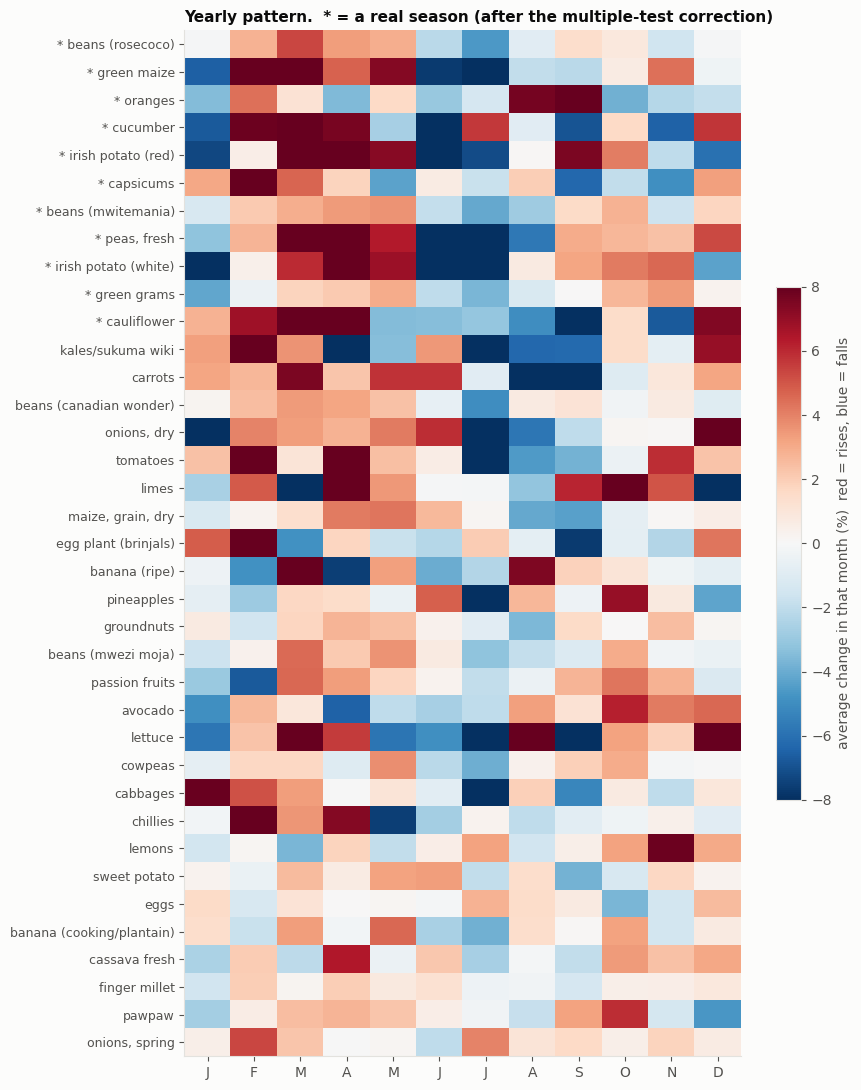

In [22]:
season = season_table(data, crops)
print(season.sort_values("p_value").to_string(index=False))
print("\ncrops with a real yearly season:", int(season["yearly_season"].sum()), "of", len(season))
plot_season_heatmap(data, crops, season)

In [23]:
# ===== 3.3  Functions: stationarity =====
PACK_CHANGE_CROPS = ["irish potato (white)", "irish potato (red)", "lettuce", "peas, fresh", "sweet potato", "green maize"]

def verdict(x):
    """ADF (H0: it wanders) and KPSS (H0: it stays around a level). Both must agree."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        adf_p = adfuller(x, autolag="AIC")[1]; kpss_p = kpss(x, regression="c", nlags="auto")[1]
    if adf_p < 0.05 and kpss_p >= 0.05: return "stationary"
    if adf_p >= 0.05 and kpss_p < 0.05: return "wanders"
    return "unclear"

def stationarity_table(data, crops):
    rows = []
    for c in crops:
        ls = log_price(data, c); v1 = verdict(ls); v2 = verdict(ls.diff().dropna())
        d = 0 if v1 == "stationary" else (1 if (v1 == "wanders" and v2 == "stationary") else "check")
        rows.append({"crop": c, "price_line": v1, "monthly_change": v2, "suggested_d": d, "pack_change": c in PACK_CHANGE_CROPS})
    return pd.DataFrame(rows)

def plot_wander_vs_change(data, crop_list):
    fig, axes = plt.subplots(len(crop_list), 2, figsize=(12, 2.6 * len(crop_list)))
    for (a1, a2), c in zip(axes, crop_list):
        ls = log_price(data, c)
        a1.plot(ls.index, ls.values, color=INK, lw=1.3); a1.set_title(c + " - log price", loc="left", fontsize=10, fontweight="bold")
        ch = ls.diff(); a2.plot(ch.index, ch.values * 100, color=BLUE, lw=1); a2.axhline(0, color=INK2, lw=0.8)
        a2.set_title(c + " - monthly change (%)", loc="left", fontsize=10, fontweight="bold")
    fig.tight_layout(); plt.show()

In [24]:
# ===== 3.4  Functions: memory =====
def memory_table(data, crops):
    rows = []
    for c in crops:
        chg = log_price(data, c).diff().dropna(); r = acf(chg, nlags=12, fft=False)
        rows.append({"crop": c, "acf_lag1": round(r[1], 2), "acf_lag2": round(r[2], 2), "acf_lag12": round(r[12], 2),
                     "band": round(1.96 / np.sqrt(len(chg)), 2),
                     "lb12_p": acorr_ljungbox(chg, lags=[12])["lb_pvalue"].iloc[0],
                     "arch_p": het_arch(chg - chg.mean(), nlags=12)[1]})
    t = pd.DataFrame(rows)
    t["lb12_holm"] = multipletests(t["lb12_p"], method="holm")[1]
    t["arch_holm"] = multipletests(t["arch_p"], method="holm")[1]
    t["has_memory"] = t["lb12_holm"] < 0.05
    t["volatility_bunches"] = t["arch_holm"] < 0.05
    return t.round({"lb12_p": 4, "arch_p": 4, "lb12_holm": 4, "arch_holm": 4})

def plot_acf_pacf(data, crop_list, nlags=24):
    fig, axes = plt.subplots(len(crop_list), 2, figsize=(12, 2.4 * len(crop_list)), sharex=True)
    for (a1, a2), c in zip(axes, crop_list):
        chg = log_price(data, c).diff().dropna(); band = 1.96 / np.sqrt(len(chg))
        for ax, vals, name in [(a1, acf(chg, nlags=nlags, fft=False)[1:], "ACF"), (a2, pacf(chg, nlags=nlags)[1:], "PACF")]:
            ax.axhspan(-band, band, color=GREY, alpha=0.45, lw=0)
            ax.bar(range(1, nlags + 1), vals, color=[BLUE if abs(v) > band else GREY for v in vals], width=0.6)
            ax.axhline(0, color=INK2, lw=0.8); ax.set_ylim(-0.5, 0.6)
            ax.set_title(f"{c} - {name}", loc="left", fontsize=10, fontweight="bold")
    for ax in axes[-1]: ax.set_xlabel("months back")
    fig.tight_layout(); plt.show()

                     crop  acf_lag1  acf_lag2  acf_lag12  band  lb12_holm  has_memory  arch_holm  volatility_bunches
                 chillies     -0.36      0.14      -0.03  0.16     0.0000        True     1.0000               False
     irish potato (white)      0.21     -0.22       0.12  0.16     0.0000        True     1.0000               False
                  oranges      0.10     -0.26       0.24  0.16     0.0000        True     1.0000               False
            banana (ripe)     -0.33      0.02       0.14  0.16     0.0010        True     1.0000               False
       irish potato (red)      0.18     -0.27       0.04  0.16     0.0021        True     1.0000               False
             sweet potato     -0.32      0.11      -0.07  0.16     0.0071        True     0.1201               False
              peas, fresh      0.07     -0.12       0.16  0.16     0.0189        True     1.0000               False
         beans (rosecoco)      0.19      0.11       0.29  0.16  

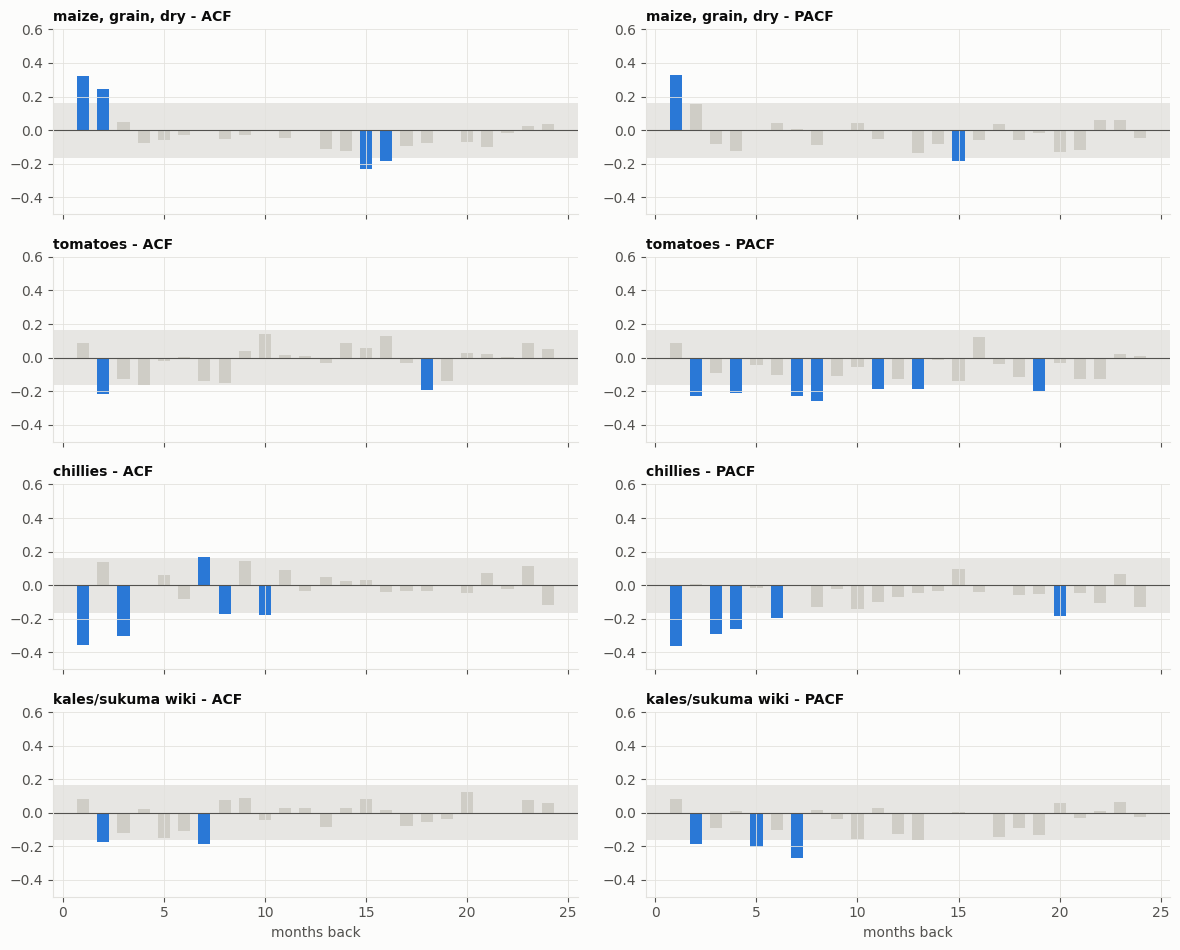

In [25]:
memory = memory_table(data, crops)
show = ["crop", "acf_lag1", "acf_lag2", "acf_lag12", "band", "lb12_holm", "has_memory", "arch_holm", "volatility_bunches"]
print(memory.sort_values("lb12_holm")[show].to_string(index=False))
print("\ncrops with memory:", int(memory["has_memory"].sum()), "of", len(memory))
print("crops where wild months bunch together:", int(memory["volatility_bunches"].sum()), "of", len(memory))
plot_acf_pacf(data, ["maize, grain, dry", "tomatoes", "chillies", "kales/sukuma wiki"])

In [26]:
#**Train / validation split (by time)**
# ===== 4.1  Functions: time split =====
MIN_VALID_REAL = 12                                          # rule: every crop needs >= 12 REAL months to be tested on
CANDIDATE_CUTS = ["2020-12-01", "2021-12-01", "2022-12-01"]  # last training month (we cut at year ends)

def compare_cuts(data, crops, cuts=CANDIDATE_CUTS):
    """For each possible cut: how many months to train on, how many to test on, and the crop with the least real test data."""
    d = data[data["crop"].isin(crops)]
    rows = []
    for cut in map(pd.Timestamp, cuts):
        v = d[d["date"] > cut]
        real = v[v["source"] == "real"].groupby("crop").size().reindex(crops).fillna(0)
        rows.append({"last_training_month": cut.strftime("%Y-%m"), "training_months": d.loc[d["date"] <= cut, "date"].nunique(),
                     "validation_months": v["date"].nunique(), "fewest_real_in_validation": int(real.min()),
                     "crop_with_fewest": real.idxmin(), "passes_rule": bool(real.min() >= MIN_VALID_REAL)})
    return pd.DataFrame(rows)

def choose_cut(table):
    """The latest cut that passes the rule (this keeps the most data for training)."""
    return pd.Timestamp(table.loc[table["passes_rule"], "last_training_month"].iloc[-1] + "-01")

def split_data(data, cut):
    """Training = months up to the cut. Validation = months after it. Time order is never mixed."""
    return data[data["date"] <= cut].copy(), data[data["date"] > cut].copy()

def split_report(train, valid, crops):
    """Per crop: months and REAL months in each part."""
    t = train[train["crop"].isin(crops)]; v = valid[valid["crop"].isin(crops)]
    return pd.DataFrame({"train_months": t.groupby("crop").size(), "train_real": t[t["source"] == "real"].groupby("crop").size(),
                         "valid_months": v.groupby("crop").size(), "valid_real": v[v["source"] == "real"].groupby("crop").size()}).fillna(0).astype(int)

def plot_split(report, cut):
    """Real months we can test on, per crop. The dashed line is the minimum we asked for."""
    r = report.sort_values("valid_real")
    fig, ax = plt.subplots(figsize=(8, 9))
    ax.barh(r.index, r["valid_real"], color=BLUE, height=0.65)
    ax.axvline(MIN_VALID_REAL, color=INK, lw=1.2, ls="--"); ax.text(MIN_VALID_REAL + 0.2, -0.9, f"minimum = {MIN_VALID_REAL}", fontsize=9)
    ax.set_xlabel("real months in the validation part"); ax.tick_params(axis="y", labelsize=8)
    ax.set_title(f"Validation = months after {cut:%Y-%m}.  How many real months can we test on?", loc="left", fontsize=11, fontweight="bold")
    fig.tight_layout(); plt.show()


last_training_month  training_months  validation_months  fewest_real_in_validation crop_with_fewest  passes_rule
            2020-12              108                 36                         17             eggs         True
            2021-12              120                 24                         16      cauliflower         True
            2022-12              132                 12                          9      cauliflower        False

chosen last training month: 2021-12

training: 2012-01 to 2021-12 | validation: 2022-01 to 2023-12
     train_months  train_real  valid_months  valid_real
min         120.0        90.0          24.0        16.0
50%         120.0       105.0          24.0        17.0
max         120.0       105.0          24.0        17.0


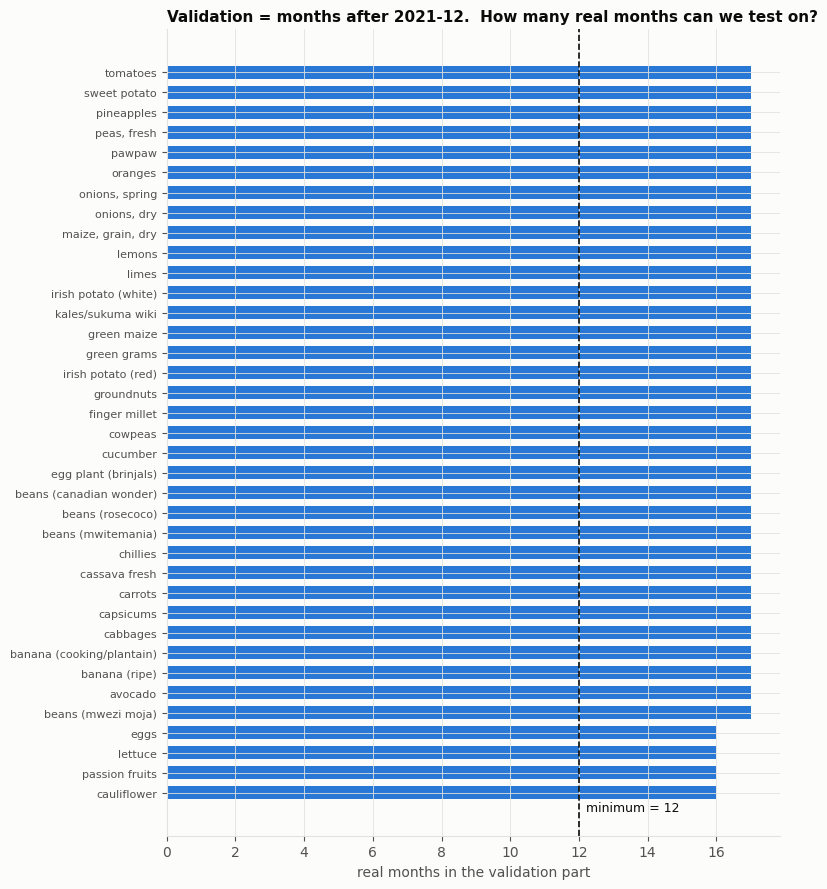

In [27]:
cuts = compare_cuts(data, crops)
print(cuts.to_string(index=False))
CUT = choose_cut(cuts)
print("\nchosen last training month:", CUT.strftime("%Y-%m"))

train, valid = split_data(data, CUT)
report = split_report(train, valid, crops)
print("\ntraining:", train["date"].min().strftime("%Y-%m"), "to", train["date"].max().strftime("%Y-%m"), "|",
      "validation:", valid["date"].min().strftime("%Y-%m"), "to", valid["date"].max().strftime("%Y-%m"))
print(report.describe().loc[["min", "50%", "max"]].round(0).to_string())
plot_split(report, CUT)
train.to_csv("train.csv", index=False); valid.to_csv("valid.csv", index=False)

In [28]:
#Baseline model 
# ===== 5.1  Functions: baseline models and the rolling test =====
HORIZONS = [1, 3, 6, 12]                                 # how many months ahead we forecast
BASELINES = ["naive", "seasonal_naive"]

def baseline_forecast(y, h, kind):
    """y = log price up to 'today'. naive = same as today. seasonal_naive = same as this month last year."""
    if kind == "naive":
        return y.iloc[-1]
    return y.iloc[-12 + ((h - 1) % 12)]

def rolling_backtest(data, crops, cut, horizons=HORIZONS, kinds=BASELINES):
    """Stand at each month from the cut to the end, forecast h months ahead using only what was known then,
       and compare with the real price. Only REAL target months are scored."""
    rows = []
    for crop in crops:
        g = data[data["crop"] == crop].set_index("date")
        y = np.log(g["price_per_kg"].astype(float)).asfreq("MS"); real = g["source"] == "real"
        for origin in y.index[y.index >= cut]:
            for h in horizons:
                target = origin + pd.DateOffset(months=h)
                if target not in y.index or not real[target]:
                    continue
                for kind in kinds:
                    f = baseline_forecast(y[:origin], h, kind)
                    rows.append({"crop": crop, "origin": origin, "h": h, "model": kind,
                                 "pct_error": abs(np.exp(f) - np.exp(y[target])) / np.exp(y[target]) * 100})
    return pd.DataFrame(rows)

def error_by_horizon(bt):
    """Typical % error (median across crops of each crop's average error)."""
    per_crop = bt.groupby(["h", "model", "crop"])["pct_error"].mean()
    return per_crop.groupby(["h", "model"]).median().unstack("model").round(1)

def plot_baselines(table):
    fig, ax = plt.subplots(figsize=(8, 4.5)); x = np.arange(len(table)); w = 0.36
    for k, (m, col) in enumerate([("naive", BLUE), ("seasonal_naive", GREY)]):
        ax.bar(x + (k - 0.5) * w, table[m], w, color=col, label=m)
        for xi, v in zip(x + (k - 0.5) * w, table[m]): ax.text(xi, v + 0.3, f"{v:.0f}%", ha="center", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels([f"{h} month{'s' if h > 1 else ''} ahead" for h in table.index])
    ax.set_ylabel("typical error (%)"); ax.legend(frameon=False)
    ax.set_title("Baseline score on the validation months: this is the number to beat", loc="left", fontsize=11, fontweight="bold")
    fig.tight_layout(); plt.show()

scored forecasts per horizon: {1: 625, 3: 552, 6: 441, 12: 367}

typical error % (median across crops) - lower is better
model  naive  seasonal_naive
h                           
1        7.6            18.7
3       12.4            18.0
6       14.7            19.5
12      18.0            18.0


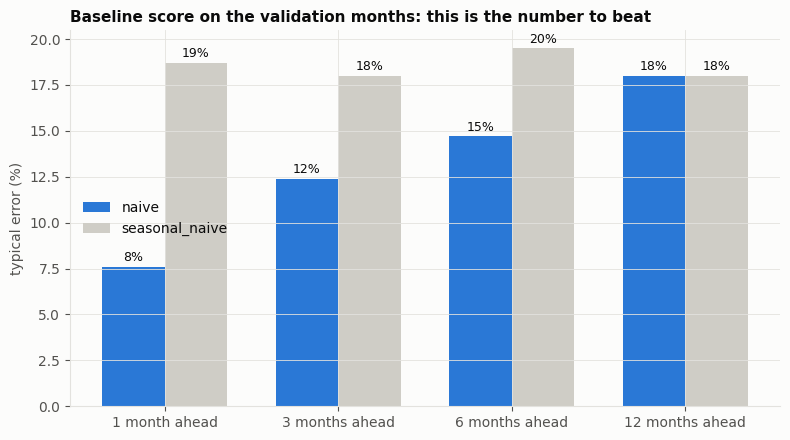


naive error at 1 month - easiest 5 crops:
 crop
eggs            2.2
groundnuts      2.7
sweet potato    2.9
cowpeas         3.4
green grams     3.8

naive error at 1 month - hardest 5 crops:
 crop
irish potato (red)      13.5
irish potato (white)    14.6
limes                   15.8
lettuce                 17.1
peas, fresh             18.2


In [29]:
bt = rolling_backtest(data, crops, CUT)
print("scored forecasts per horizon:", bt[bt["model"] == "naive"].groupby("h").size().to_dict())
table = error_by_horizon(bt)
print("\ntypical error % (median across crops) - lower is better")
print(table.to_string())
plot_baselines(table)

one = bt[(bt["model"] == "naive") & (bt["h"] == 1)].groupby("crop")["pct_error"].mean().sort_values().round(1)
print("\nnaive error at 1 month - easiest 5 crops:\n", one.head(5).to_string())
print("\nnaive error at 1 month - hardest 5 crops:\n", one.tail(5).to_string())

In [30]:
# ===== 6.1  Functions: the candidate loop (training months only) =====
from statsmodels.tsa.statespace.sarimax import SARIMAX

D = 1                                                    # we difference once for every crop (reason in the note below)
ORDERS = [(p, q) for p in range(5) for q in range(3)]    # p 0..4, q 0..2  (p=q=0 with d=1 IS the naive model)
LB_ALPHA = 0.05                                          # residuals must show no leftover pattern (Ljung-Box, lag 12)
AICC_TIE = 2                                             # models within 2 AICc points of the best count as tied -> keep the simplest

def train_log(train, crop):
    s = train[train["crop"] == crop].set_index("date")["price_per_kg"].astype(float)
    return np.log(s).asfreq("MS")

def month_dummies(index):
    """11 yes/no columns (one per calendar month, January left out) = the yearly season."""
    return pd.get_dummies(index.month, prefix="m", drop_first=True).astype(float).set_axis(index)

def fit_one(y, p, d, q, season):
    exog = month_dummies(y.index) if season else None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return SARIMAX(y, exog=exog, order=(p, d, q), trend="n").fit(disp=False, maxiter=200)

def residual_p(res, p, q, d):
    r = res.resid.iloc[d:]
    return float(acorr_ljungbox(r, lags=[12], model_df=min(p + q, 11))["lb_pvalue"].iloc[0])

def try_candidates(y, d, seasonal_ok):
    """Fit every (p, q) without a season, and with a season if this crop has one. One row per model."""
    rows = []
    for season in ([False, True] if seasonal_ok else [False]):
        for p, q in ORDERS:
            try:
                res = fit_one(y, p, d, q, season)
                rows.append({"p": p, "q": q, "season": season, "k": len(res.params), "aicc": res.aicc,
                             "resid_p": residual_p(res, p, q, d)})
            except Exception:
                pass
    return pd.DataFrame(rows)

def pick_model(c):
    """Rule: keep models whose residuals are clean -> best AICc -> among those within 2 points, the simplest."""
    ok = c[c["resid_p"] >= LB_ALPHA]
    if ok.empty:
        return None                                       # no adequate model: we fall back to naive
    near = ok[ok["aicc"] <= ok["aicc"].min() + AICC_TIE]
    return near.sort_values(["k", "aicc"]).iloc[0]

def fit_all(train, crops):
    """For every crop: check the season on training months, loop over candidates, pick one."""
    season_flags = season_table(train, crops).set_index("crop")["yearly_season"]
    out, tables = [], {}
    for crop in crops:
        y = train_log(train, crop); d = D
        c = try_candidates(y, d, bool(season_flags[crop])); tables[crop] = c
        best = pick_model(c)
        naive_aicc = c[(c.p == 0) & (c.q == 0) & (~c.season)]["aicc"]
        row = {"crop": crop, "d": d, "has_season": bool(season_flags[crop]), "models_tried": len(c)}
        if best is None:
            row.update({"chosen": "naive (no adequate model)", "p": 0, "q": 0, "season": False})
        else:
            row.update({"chosen": f"ARIMA({int(best.p)},{d},{int(best.q)})" + (" + season" if best.season else ""),
                        "p": int(best.p), "q": int(best.q), "season": bool(best.season), "aicc": round(best.aicc, 1),
                        "better_than_naive_by": round(float(naive_aicc.iloc[0] - best.aicc), 1) if len(naive_aicc) else np.nan,
                        "resid_p": round(best.resid_p, 3)})
        out.append(row)
    return pd.DataFrame(out), tables

def plot_resid_pacf(train, chosen, crop_list, nlags=24):
    """PACF of the leftover errors of the chosen model. All bars inside the grey band = nothing left to learn."""
    fig, axes = plt.subplots(len(crop_list), 1, figsize=(9, 2.3 * len(crop_list)), sharex=True)
    for ax, crop in zip(np.atleast_1d(axes), crop_list):
        r = chosen.set_index("crop").loc[crop]; y = train_log(train, crop)
        res = fit_one(y, int(r["p"]), int(r["d"]), int(r["q"]), bool(r["season"]))
        e = res.resid.iloc[int(r["d"]):]; vals = pacf(e, nlags=nlags)[1:]; band = 1.96 / np.sqrt(len(e))
        ax.axhspan(-band, band, color=GREY, alpha=0.45, lw=0)
        ax.bar(range(1, nlags + 1), vals, color=[BLUE if abs(v) > band else GREY for v in vals], width=0.6)
        ax.axhline(0, color=INK2, lw=0.8); ax.set_ylim(-0.5, 0.5)
        ax.set_title(f"{crop} - {r['chosen']} - PACF of the leftover errors", loc="left", fontsize=10, fontweight="bold")
    axes[-1].set_xlabel("months back"); fig.tight_layout(); plt.show()

done in 247s

                     crop  d  has_season                    chosen  better_than_naive_by  resid_p
                  avocado  1       False naive (no adequate model)                   NaN      NaN
banana (cooking/plantain)  1       False              ARIMA(1,1,1)                  16.0    0.531
            banana (ripe)  1       False              ARIMA(0,1,1)                  13.3    0.149
  beans (canadian wonder)  1        True     ARIMA(1,1,0) + season                  20.6    0.163
       beans (mwezi moja)  1       False              ARIMA(0,1,0)                   0.0    0.732
       beans (mwitemania)  1        True              ARIMA(0,1,0)                   0.0    0.102
         beans (rosecoco)  1        True     ARIMA(2,1,2) + season                  30.2    0.108
                 cabbages  1       False              ARIMA(4,1,2)                   3.4    0.516
                capsicums  1        True     ARIMA(1,1,1) + season                  25.5    0.135
      

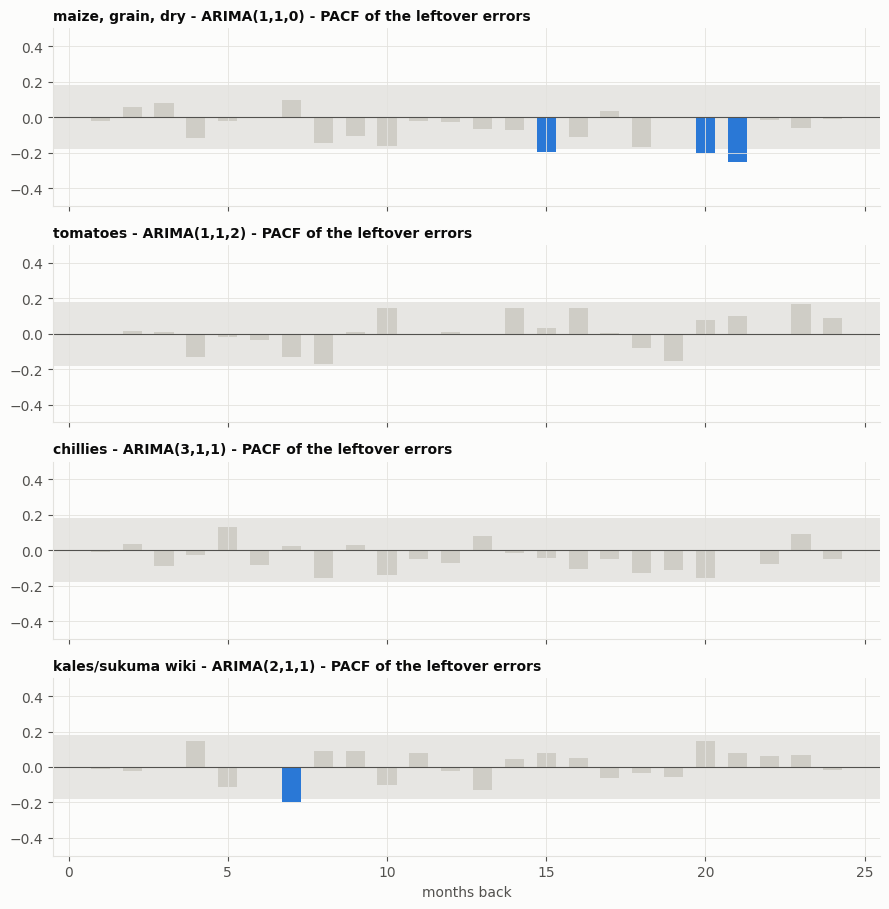

In [31]:
import time; t0 = time.time()
train = data[data["date"] <= CUT].copy()                 # training months only
chosen, cand_tables = fit_all(train, crops)
print(f"done in {time.time() - t0:.0f}s\n")
print(chosen[["crop", "d", "has_season", "chosen", "better_than_naive_by", "resid_p"]].to_string(index=False))
print("\nwhat was chosen:"); print(chosen["chosen"].value_counts().to_string())
plot_resid_pacf(train, chosen, ["maize, grain, dry", "tomatoes", "chillies", "kales/sukuma wiki"])

In [32]:
# ===== 7.1  Functions: the exam on the validation months =====
RULE_GAIN, N_BOOT, SEED = 5.0, 2000, 42                   # model must beat naive by 5%, and the gain must not be luck

def model_vs_naive(data, crops, chosen, cut, horizons=HORIZONS):
    """Parameters are learned on TRAINING months only. At each month from the cut onward we show the model the
       prices known then (parameters stay fixed), forecast 1-12 months ahead, and compare with the real price."""
    spec = chosen.set_index("crop"); rows = []
    for crop in crops:
        s = spec.loc[crop]
        if s["chosen"].startswith("naive"):
            continue                                       # naive crops have nothing to test
        g = data[data["crop"] == crop].set_index("date")
        y = np.log(g["price_per_kg"].astype(float)).asfreq("MS"); real = g["source"] == "real"
        X = month_dummies(pd.date_range(y.index[0], y.index[-1] + pd.DateOffset(months=12), freq="MS")) if s["season"] else None
        fit = fit_one(y[:cut], int(s["p"]), int(s["d"]), int(s["q"]), bool(s["season"]))
        for origin in y.index[y.index >= cut]:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                res = fit.apply(y[:origin], exog=None if X is None else X.loc[:origin], refit=False)
                ahead = X.loc[origin + pd.DateOffset(months=1): origin + pd.DateOffset(months=12)] if X is not None else None
                fc = np.asarray(res.forecast(steps=12, exog=ahead))
            for h in horizons:
                target = origin + pd.DateOffset(months=h)
                if target not in y.index or not real[target]:
                    continue
                actual = np.exp(y[target])
                rows.append({"crop": crop, "origin": origin, "h": h,
                             "model_err": abs(np.exp(fc[h - 1]) - actual) / actual * 100,
                             "naive_err": abs(np.exp(y[origin]) - actual) / actual * 100})
    return pd.DataFrame(rows)

def crop_gain(bt):
    """Per crop and horizon: how much smaller is the model's error than naive's? (+10 = 10% better)"""
    g = bt.groupby(["h", "crop"])[["model_err", "naive_err"]].mean()
    return ((1 - g["model_err"] / g["naive_err"]) * 100).rename("gain")

def pooled(v):
    """Typical gain across crops (geometric mean of the error ratios)."""
    return (1 - np.exp(np.log(1 - np.asarray(v) / 100).mean())) * 100

def judge(bt, n_boot=N_BOOT, seed=SEED):
    """The fixed rule: pooled gain >= 5%, the likely range stays above 0, and the gain is positive in both halves."""
    rng = np.random.default_rng(seed); gain = crop_gain(bt)
    mid = bt["origin"].sort_values().iloc[len(bt) // 2]
    halves = {"first": crop_gain(bt[bt["origin"] < mid]), "second": crop_gain(bt[bt["origin"] >= mid])}
    out = []
    for h in sorted(bt["h"].unique()):
        v = gain.loc[h].values
        boot = [pooled(rng.choice(v, size=len(v), replace=True)) for _ in range(n_boot)]
        lo, hi = np.percentile(boot, [2.5, 97.5])
        out.append({"h": h, "crops": len(v), "pooled_gain_%": round(pooled(v), 1), "range_low": round(lo, 1), "range_high": round(hi, 1),
                    "crops_better": f"{int((v > 0).sum())} of {len(v)}",
                    "gain_first_half": round(pooled(halves["first"].loc[h].values), 1),
                    "gain_second_half": round(pooled(halves["second"].loc[h].values), 1)})
    t = pd.DataFrame(out)
    t["USE_MODEL"] = (t["pooled_gain_%"] >= RULE_GAIN) & (t["range_low"] > 0) & (t["gain_first_half"] > 0) & (t["gain_second_half"] > 0)
    return t

def plot_exam(bt, verdict_table):
    gain = crop_gain(bt); hs = list(verdict_table["h"])
    fig, ax = plt.subplots(figsize=(9, 5))
    rng = np.random.default_rng(1)
    for i, h in enumerate(hs):
        v = gain.loc[h].values; ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=14, color=GREY, zorder=2)
        r = verdict_table.set_index("h").loc[h]
        ax.errorbar(i, r["pooled_gain_%"], yerr=[[r["pooled_gain_%"] - r["range_low"]], [r["range_high"] - r["pooled_gain_%"]]],
                    fmt="o", color=BLUE, ms=9, lw=2.5, capsize=5, zorder=3)
    ax.axhline(0, color=INK2, lw=1); ax.axhline(RULE_GAIN, color=INK2, lw=1, ls="--"); ax.text(len(hs) - 0.55, RULE_GAIN + 1, "5% rule", fontsize=9, ha="right")
    ax.set_xticks(range(len(hs))); ax.set_xticklabels([f"{h} month{'s' if h > 1 else ''} ahead" for h in hs])
    ax.set_ylim(max(-60, ax.get_ylim()[0]), min(60, ax.get_ylim()[1])); ax.set_ylabel("better than naive (%)")
    ax.set_title("The exam: grey dots = single crops, blue = typical gain with its likely range", loc="left", fontsize=11, fontweight="bold")
    fig.tight_layout(); plt.show()

done in 32s | crops tested: 35 | scored forecasts: {1: 591, 3: 522, 6: 417, 12: 347}

typical error % (median across crops) - lower is better
    model_err  naive_err
h                       
1         7.6        7.6
3        12.2       12.4
6        16.5       14.7
12       22.8       18.1

=== did the chosen models beat 'same as last month'? ===
 h  crops  pooled_gain_%  range_low  range_high crops_better  gain_first_half  gain_second_half  USE_MODEL
 1     35           -8.0      -20.1         0.4     14 of 35             -5.5             -11.5      False
 3     35           -9.9      -24.3         1.2     11 of 35             -6.6             -12.7      False
 6     35          -14.5      -27.6        -3.4     10 of 35            -16.8             -15.9      False
12     35          -15.1      -26.8        -4.3     10 of 35            -13.5             -23.0      False

RULE: gain >= 5%, likely range above 0, and positive in both halves of the exam.
USE the models at: no horizon - u

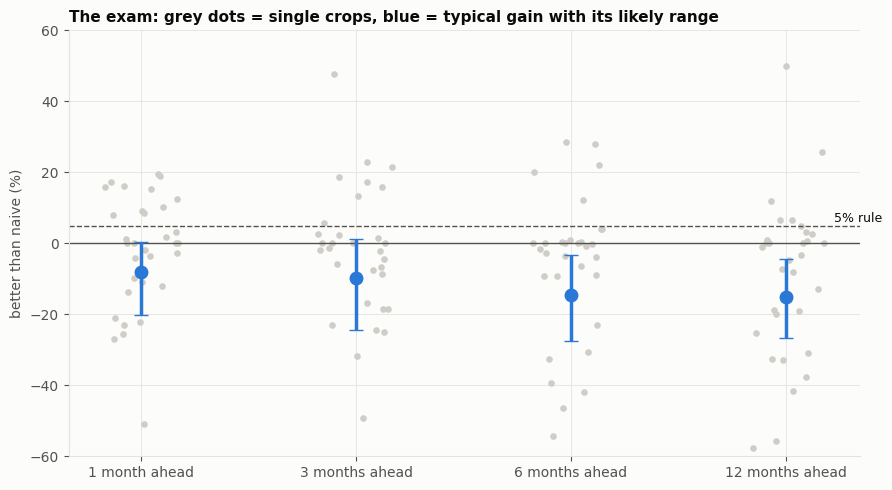

In [33]:
import time; t0 = time.time()
bt7 = model_vs_naive(data, crops, chosen, CUT)
print(f"done in {time.time() - t0:.0f}s | crops tested:", bt7["crop"].nunique(), "| scored forecasts:", bt7.groupby("h").size().to_dict())

typical_err = bt7.groupby(["h", "crop"])[["model_err", "naive_err"]].mean().groupby("h").median().round(1)
print("\ntypical error % (median across crops) - lower is better"); print(typical_err.to_string())

verdict_table = judge(bt7)
print("\n=== did the chosen models beat 'same as last month'? ===")
print(verdict_table.to_string(index=False))
print("\nRULE: gain >= 5%, likely range above 0, and positive in both halves of the exam.")
print("USE the models at:", verdict_table.loc[verdict_table["USE_MODEL"], "h"].tolist() or "no horizon - use naive everywhere")
plot_exam(bt7, verdict_table)

In [34]:
# ===== 7.2  Functions: the practice exam INSIDE the training months =====
from statsmodels.tsa.holtwinters import ExponentialSmoothing

PRACTICE_START, PRACTICE_STEP = "2016-01-01", "2MS"       # stand at every 2nd month from 2016 (at least 4 years of history)
CANDIDATES = ["naive", "arima", "ets_damped", "ets_season", "blend"]
RIVALS = [m for m in CANDIDATES if m != "naive"]
HIT = 10.0                                                # accurate = within 10% of the real price (your choice)
MIN_HIT_GAIN = 0.0                                        # a rival must not be worse than naive at "within 10%"

def ets_forecast(y, h, season):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal="add" if season else None,
                                 seasonal_periods=12 if season else None, initialization_method="estimated").fit()
    return np.asarray(m.forecast(h))

def arima_forecast(y, spec, h):
    """The ARIMA setting chosen in Part 6, refitted on the data up to 'today'."""
    p, d, q, season = int(spec["p"]), int(spec["d"]), int(spec["q"]), bool(spec["season"])
    res = fit_one(y, p, d, q, season)
    ahead = None
    if season:
        ahead = month_dummies(pd.date_range(y.index[0], y.index[-1] + pd.DateOffset(months=h), freq="MS")).loc[y.index[-1] + pd.DateOffset(months=1):]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return np.asarray(res.forecast(steps=h, exog=ahead))

def candidate_forecasts(y, spec, h=12):
    """All five forecasts (log price) for 1..h months ahead, using only the data up to 'today'."""
    naive = np.repeat(y.iloc[-1], h); out = {"naive": naive}
    for name, fn in [("arima", lambda: arima_forecast(y, spec, h)), ("ets_damped", lambda: ets_forecast(y, h, False)),
                     ("ets_season", lambda: ets_forecast(y, h, True))]:
        try: out[name] = fn()
        except Exception: out[name] = np.full(h, np.nan)
    out["blend"] = (naive + out["ets_season"]) / 2         # half naive, half ETS+season
    return out

def practice_exam(train, crops, chosen):
    """Rolling practice inside the training months. Only REAL target months are scored."""
    spec = chosen.set_index("crop"); origins = pd.date_range(PRACTICE_START, train["date"].max(), freq=PRACTICE_STEP)
    rows = []
    for i, crop in enumerate(crops, 1):
        g = train[train["crop"] == crop].set_index("date")
        y = np.log(g["price_per_kg"].astype(float)).asfreq("MS"); real = g["source"] == "real"
        s = spec.loc[crop].copy()
        if s["chosen"].startswith("naive"):
            s["p"], s["q"], s["season"], s["d"] = 0, 0, False, 1          # (0,1,0) = naive
        for origin in origins:
            fc = candidate_forecasts(y[:origin], s)
            for h in HORIZONS:
                target = origin + pd.DateOffset(months=h)
                if target not in y.index or not real[target] or any(np.isnan(fc[m][h - 1]) for m in CANDIDATES):
                    continue
                actual = np.exp(y[target])
                for m in CANDIDATES:
                    rows.append({"crop": crop, "origin": origin, "h": h, "model": m,
                                 "pct_error": abs(np.exp(fc[m][h - 1]) - actual) / actual * 100})
        if i % 5 == 0 or i == len(crops): print(f"  {i}/{len(crops)} crops done")
    return pd.DataFrame(rows)

def practice_scores(bt):
    """Per crop and horizon: error gain over naive (%) and 'within 10%' gain (percentage points)."""
    e = bt.pivot_table(index=["h", "crop"], columns="model", values="pct_error", aggfunc="mean")[CANDIDATES]
    gain = (1 - e[RIVALS].div(e["naive"], axis=0)) * 100
    hit = bt.assign(hit=bt["pct_error"] <= HIT * 1.0).pivot_table(index=["h", "crop"], columns="model", values="hit", aggfunc="mean")[CANDIDATES] * 100
    return gain, hit[RIVALS].sub(hit["naive"], axis=0), hit["naive"]

def judge_practice(bt, n_boot=N_BOOT, seed=SEED):
    """Fixed rule, 4 rivals compared -> 98.75% range. Pass = gain >= 5%, range above 0, positive in both halves,
       and not worse than naive at 'within 10%'."""
    rng = np.random.default_rng(seed); gain, hitgain, _ = practice_scores(bt)
    mid = bt["origin"].drop_duplicates().sort_values().iloc[len(bt["origin"].drop_duplicates()) // 2]
    g1, g2 = practice_scores(bt[bt["origin"] < mid])[0], practice_scores(bt[bt["origin"] >= mid])[0]
    out = []
    for h in HORIZONS:
        for m in RIVALS:
            v = gain.loc[h, m].dropna().values
            boot = [pooled(rng.choice(v, size=len(v), replace=True)) for _ in range(n_boot)]
            lo, hi = np.percentile(boot, [0.625, 99.375])
            out.append({"h": h, "model": m, "pooled_gain_%": round(pooled(v), 1), "range_low": round(lo, 1), "range_high": round(hi, 1),
                        "crops_better": f"{int((v > 0).sum())} of {len(v)}",
                        "gain_first_half": round(pooled(g1.loc[h, m].dropna().values), 1),
                        "gain_second_half": round(pooled(g2.loc[h, m].dropna().values), 1),
                        "within10_change_pts": round(hitgain.loc[h, m].mean(), 1)})
    t = pd.DataFrame(out)
    t["PASS"] = ((t["pooled_gain_%"] >= RULE_GAIN) & (t["range_low"] > 0) & (t["gain_first_half"] > 0)
                 & (t["gain_second_half"] > 0) & (t["within10_change_pts"] >= MIN_HIT_GAIN))
    return t

def plot_practice(t):
    COL = {"arima": BLUE, "ets_damped": "#eb6834", "ets_season": "#1baf7a", "blend": "#8a63d2"}
    fig, ax = plt.subplots(figsize=(10, 5))
    for k, m in enumerate(RIVALS):
        s = t[t["model"] == m].reset_index(drop=True); x = np.arange(len(s)) + (k - 1.5) * 0.17
        ax.errorbar(x, s["pooled_gain_%"], yerr=[s["pooled_gain_%"] - s["range_low"], s["range_high"] - s["pooled_gain_%"]],
                    fmt="o", color=COL[m], lw=2, capsize=3, ms=7, label=m)
    ax.axhline(0, color=INK2, lw=1); ax.axhline(RULE_GAIN, color=INK2, lw=1, ls="--")
    ax.text(len(HORIZONS) - 0.55, RULE_GAIN + 0.6, "5% rule", fontsize=9, ha="right")
    ax.set_xticks(range(len(HORIZONS))); ax.set_xticklabels([f"{h} month{'s' if h > 1 else ''} ahead" for h in HORIZONS])
    ax.set_ylabel("better than naive (%)"); ax.legend(frameon=False, ncol=4, loc="lower left")
    ax.set_title("Practice exam (training months only): who beats 'same as last month'?", loc="left", fontsize=11, fontweight="bold")
    fig.tight_layout(); plt.show()

  5/37 crops done
  10/37 crops done
  15/37 crops done
  20/37 crops done
  25/37 crops done
  30/37 crops done
  35/37 crops done
  37/37 crops done
done in 574s | scored forecasts per horizon: {1: 1040, 3: 1003, 6: 899, 12: 790}

=== practice exam: gain over naive (positive = better) ===
 h      model  pooled_gain_%  range_low  range_high crops_better  gain_first_half  gain_second_half  within10_change_pts  PASS
 1      arima           -3.3       -6.7         0.2     12 of 37              1.4              -8.3                 -3.2 False
 1 ets_damped           -3.9       -7.6        -0.6     11 of 37             -1.6              -7.1                 -3.0 False
 1 ets_season          -12.6      -20.3        -6.5      6 of 37             -9.7             -16.9                 -4.1 False
 1      blend           -1.0       -4.6         2.3     16 of 37              1.9              -4.6                 -1.7 False
 3      arima            3.7       -0.7         8.7     21 of 37         

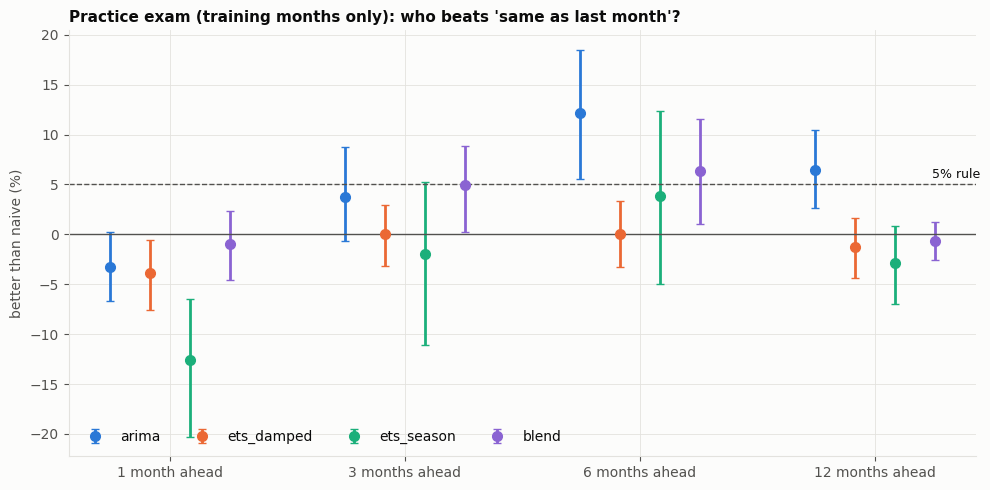

In [35]:
import time; t0 = time.time()
bt72 = practice_exam(train, crops, chosen)
print(f"done in {time.time() - t0:.0f}s | scored forecasts per horizon:", bt72[bt72["model"] == "naive"].groupby("h").size().to_dict())

t72 = judge_practice(bt72)
print("\n=== practice exam: gain over naive (positive = better) ===")
print(t72.to_string(index=False))
print("\nRULE: gain >= 5%, range above 0, positive in both halves, and 'within 10%' not worse than naive.")
passed = t72[t72["PASS"]]
print("candidates that pass:\n", passed[["h", "model", "pooled_gain_%", "within10_change_pts"]].to_string(index=False) if len(passed) else "none - naive stays")
plot_practice(t72)

In [36]:
# ===== 7.3  Functions: the final exam for the ONE candidate that passed the practice exam =====
FINAL_H = 6                                               # the horizon where the blend passed

def blend_exam(data, crops, cut, h=FINAL_H):
    """At each month from the cut onward: fit ETS+season on the prices known then, blend it half-and-half with naive,
       forecast h months ahead, compare with the real price. Only REAL months are scored."""
    rows = []
    for crop in crops:
        g = data[data["crop"] == crop].set_index("date")
        y = np.log(g["price_per_kg"].astype(float)).asfreq("MS"); real = g["source"] == "real"
        for origin in y.index[y.index >= cut]:
            target = origin + pd.DateOffset(months=h)
            if target not in y.index or not real[target]:
                continue
            ets = ets_forecast(y[:origin], h, True)[h - 1]
            blend = (ets + y[origin]) / 2
            actual = np.exp(y[target])
            rows.append({"crop": crop, "origin": origin, "h": h,
                         "model_err": abs(np.exp(blend) - actual) / actual * 100,
                         "naive_err": abs(np.exp(y[origin]) - actual) / actual * 100})
    return pd.DataFrame(rows)

def hit_change(bt):
    """Change in 'within 10%' (percentage points), averaged over crops. Positive = the blend is accurate more often."""
    hit = bt.assign(m=bt["model_err"] <= HIT, n=bt["naive_err"] <= HIT).groupby("crop")[["m", "n"]].mean() * 100
    return round((hit["m"] - hit["n"]).mean(), 1), round(hit["m"].mean(), 1), round(hit["n"].mean(), 1)

done in 59s | crops: 37 | scored forecasts: 441

=== FINAL EXAM: blend (half naive, half ETS+season) at 6 months ahead ===
 h  crops  pooled_gain_%  range_low  range_high crops_better  gain_first_half  gain_second_half  USE_MODEL
 6     37            4.8        0.6         9.0     23 of 37              7.1               3.5      False

within 10% of the real price:  blend 42.4%  |  naive 40.6%  |  change +1.8 points
typical error:  blend 13.4%  |  naive 14.7%

RULE: gain >= 5%, range above 0, positive in both halves, and 'within 10%' not worse than naive.
VERDICT: FAIL - naive stays at 6 months


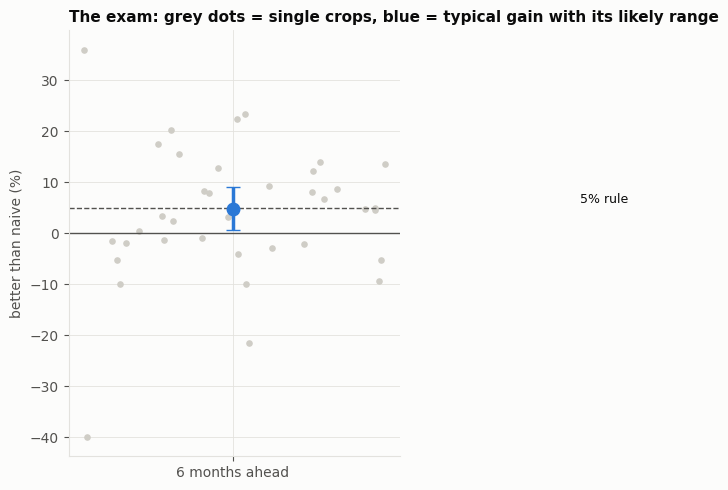

In [37]:
import time; t0 = time.time()
bt73 = blend_exam(data, crops, CUT)
print(f"done in {time.time() - t0:.0f}s | crops:", bt73["crop"].nunique(), "| scored forecasts:", len(bt73))

verdict73 = judge(bt73)
print("\n=== FINAL EXAM: blend (half naive, half ETS+season) at 6 months ahead ===")
print(verdict73.to_string(index=False))
chg, hit_blend, hit_naive = hit_change(bt73)
print(f"\nwithin 10% of the real price:  blend {hit_blend}%  |  naive {hit_naive}%  |  change {chg:+} points")
e = bt73.groupby("crop")[["model_err", "naive_err"]].mean().median().round(1)
print(f"typical error:  blend {e['model_err']}%  |  naive {e['naive_err']}%")

ok = bool(verdict73["USE_MODEL"].iloc[0]) and chg >= 0
print("\nRULE: gain >= 5%, range above 0, positive in both halves, and 'within 10%' not worse than naive.")
print("VERDICT:", "PASS - use the blend at 6 months" if ok else "FAIL - naive stays at 6 months")
plot_exam(bt73, verdict73)

In [38]:
# ===== 8.1  Functions: honest ranges and accuracy labels for the naive forecast =====
LEVEL = 80                                                # the range should hold the real price 80% of the time
LO_Q, HI_Q = (100 - LEVEL) / 200, 1 - (100 - LEVEL) / 200
VOL_MONTHS = 36                                           # "how wild is this crop?" = its last 36 months
LABEL_HIGH, LABEL_LOW = 60, 40                            # accuracy label: >= 60% high, 40-60% medium, below 40% low

def naive_errors(data, crops, first_origin="2015-01-01", horizons=HORIZONS):
    """Stand at every month, forecast 'same as today', and record the mistake (log scale) and the crop's wildness then."""
    rows = []
    for crop in crops:
        g = data[data["crop"] == crop].set_index("date")
        y = np.log(g["price_per_kg"].astype(float)).asfreq("MS"); real = g["source"] == "real"
        for origin in y.index[y.index >= first_origin]:
            sigma = y[:origin].diff().dropna().iloc[-VOL_MONTHS:].std()
            for h in horizons:
                target = origin + pd.DateOffset(months=h)
                if target not in y.index or not real[target] or not sigma > 0:
                    continue
                err = y[target] - y[origin]
                rows.append({"crop": crop, "origin": origin, "target": target, "h": h, "err": err, "z": err / sigma,
                             "pct_error": abs(np.exp(-err) - 1) * 100})          # |forecast - actual| / actual, same as Parts 5-7
    return pd.DataFrame(rows)

def learn_widths(errs):
    """How far below / above the last price does the real price land? In units of the crop's wildness."""
    w = errs.groupby("h")["z"].quantile([LO_Q, HI_Q]).unstack(); w.columns = ["low_z", "high_z"]
    return w

def check_ranges(test, widths):
    """Does the range keep its promise on months it never saw?"""
    t = test.join(widths, on="h")
    t["inside"] = (t["z"] >= t["low_z"]) & (t["z"] <= t["high_z"])
    t["below"], t["above"] = t["z"] < t["low_z"], t["z"] > t["high_z"]
    c = t.groupby("h")[["inside", "below", "above"]].mean().mul(100).round(1)
    c.columns = ["inside_range_%", "real_price_below_%", "real_price_above_%"]
    c.insert(0, "forecasts", t.groupby("h").size())
    return c

def accuracy_labels(learn):
    """Per crop and horizon: how often was 'same as today' within 10%?  -> high / medium / low."""
    hit = (learn.assign(hit=learn["pct_error"] <= HIT).groupby(["h", "crop"])["hit"].mean() * 100).rename("hit_%")
    lab = hit.to_frame(); lab["label"] = np.where(lab["hit_%"] >= LABEL_HIGH, "high", np.where(lab["hit_%"] >= LABEL_LOW, "medium", "low"))
    return lab

def check_labels(test, labels):
    """Did a crop labelled 'high' really reach about 60% on the months we hid?"""
    t = test.assign(hit=test["pct_error"] <= HIT).join(labels["label"], on=["h", "crop"])
    per = t.groupby(["h", "label", "crop"])["hit"].mean().mul(100).groupby(["h", "label"]).agg(["count", "mean"])
    per.columns = ["crops", "hit_on_hidden_months_%"]
    return per.round(0).astype({"crops": int})

def plot_range_check(c):
    fig, ax = plt.subplots(figsize=(8, 4.5)); x = np.arange(len(c))
    ax.bar(x, c["inside_range_%"], color="#1baf7a", width=0.55, label="real price inside the range")
    ax.bar(x, c["real_price_below_%"], bottom=c["inside_range_%"], color="#e34948", width=0.55, label="below the range")
    ax.bar(x, c["real_price_above_%"], bottom=c["inside_range_%"] + c["real_price_below_%"], color="#eb6834", width=0.55, label="above the range")
    ax.axhline(LEVEL, color=INK, lw=1.2, ls="--")
    for xi, v in zip(x, c["inside_range_%"]): ax.text(xi, v - 6, f"{v:.0f}%", ha="center", color="white", fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels([f"{h} month{'s' if h > 1 else ''} ahead" for h in c.index]); ax.set_ylim(0, 105)
    ax.set_title("Did the 80% range keep its promise on the hidden months?", loc="left", fontsize=11, fontweight="bold")
    ax.legend(frameon=False, fontsize=8, loc="lower right"); fig.tight_layout(); plt.show()

what the range learned from the training months (in units of crop wildness):
    low_z  high_z
h                
1   -1.26    1.38
3   -1.98    2.26
6   -2.42    2.68
12  -2.64    3.55

=== CHECK on the hidden months: the real price should be inside about 80% of the time ===
    forecasts  inside_range_%  real_price_below_%  real_price_above_%
h                                                                    
1         625            83.8                 7.0                 9.1
3         552            80.6                 5.8                13.6
6         441            76.6                 5.9                17.5
12        367            77.7                 1.6                20.7


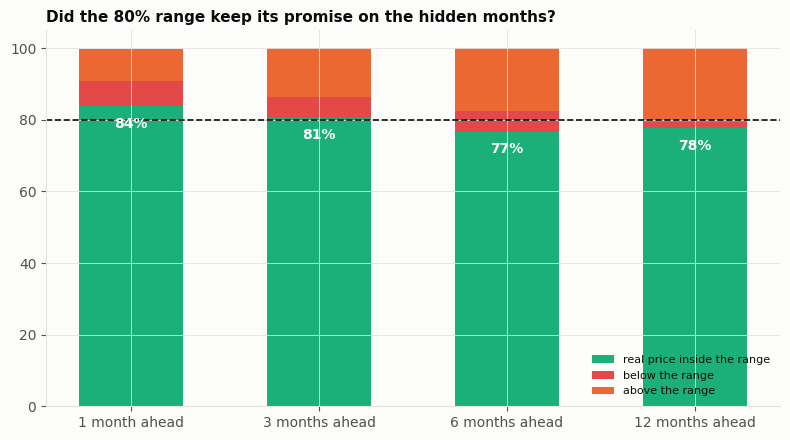


labels set on the training months (number of crops per label):
label  high  medium  low
h                       
1        25      11    1
3        14       9   14
6         8      12   17
12        4      14   19

=== CHECK: how accurate were those crops on the hidden months? ===
           crops  hit_on_hidden_months_%
h  label                                
1  high       25                    82.0
   low         1                    47.0
   medium     11                    62.0
3  high       14                    61.0
   low        14                    38.0
   medium      9                    60.0
6  high        8                    39.0
   low        17                    39.0
   medium     12                    44.0
12 high        4                    16.0
   low        19                    28.0
   medium     14                    28.0


In [39]:
errs = naive_errors(data, crops)
learn = errs[errs["target"] <= CUT]                       # mistakes we could have known by the end of training
test = errs[errs["origin"] >= CUT]                        # the hidden validation months

# ---------- 8.1  ranges ----------
widths = learn_widths(learn)
print("what the range learned from the training months (in units of crop wildness):"); print(widths.round(2).to_string())
chk = check_ranges(test, widths)
print("\n=== CHECK on the hidden months: the real price should be inside about 80% of the time ==="); print(chk.to_string())
plot_range_check(chk)

# ---------- 8.2  accuracy labels ----------
labels = accuracy_labels(learn)
print("\nlabels set on the training months (number of crops per label):")
print(labels.groupby(["h", "label"]).size().unstack(fill_value=0).reindex(columns=["high", "medium", "low"], fill_value=0).to_string())
print("\n=== CHECK: how accurate were those crops on the hidden months? ===")
print(check_labels(test, labels).to_string())

# ---------- final ranges: learn from ALL months now that the check is done ----------
widths_all = learn_widths(errs)

In [40]:
# ===== 8.3  Functions: will the price go UP or DOWN?  (direction rules and the confusion matrix) =====
RIVAL_RULES = ["momentum", "bounce", "ets_season"]        # always_up is the ruler: prices trended up over the decade
ALL_RULES = RIVAL_RULES + ["always_up"]
MIN_DIR_GAIN = 3.0                                        # a rule must beat 'always up' by 3 percentage points

def direction_rows(data, crops, origins, max_target=None, horizons=HORIZONS):
    """At each origin, what does each rule say (+1 up, -1 down) and what really happened over h months?"""
    rows = []
    for crop in crops:
        g = data[data["crop"] == crop].set_index("date")
        y = np.log(g["price_per_kg"].astype(float)).asfreq("MS"); real = g["source"] == "real"
        for origin in origins:
            if origin not in y.index or origin < y.index[2]:
                continue
            past = y[:origin]; move = past.iloc[-1] - past.iloc[-2]; mom = 1 if move >= 0 else -1
            try: ets = ets_forecast(past, max(horizons), True)
            except Exception: ets = np.full(max(horizons), np.nan)
            for h in horizons:
                target = origin + pd.DateOffset(months=h)
                if target not in y.index or not real[target] or (max_target is not None and target > max_target):
                    continue
                diff = y[target] - y[origin]
                if diff == 0 or np.isnan(ets[h - 1]):
                    continue
                rows.append({"crop": crop, "origin": origin, "h": h, "actual": 1 if diff > 0 else -1,
                             "momentum": mom, "bounce": -mom, "ets_season": 1 if ets[h - 1] >= y[origin] else -1, "always_up": 1})
    return pd.DataFrame(rows)

def direction_accuracy(rows):
    """Share of correct calls, per rule, averaged over crops (each crop counts once)."""
    hit = rows.assign(**{r: rows[r] == rows["actual"] for r in ALL_RULES}).groupby(["h", "crop"])[ALL_RULES].mean() * 100
    return hit

def judge_direction(rows, n_boot=N_BOOT, seed=SEED):
    """A rule passes if it beats 'always up' by >= 3 points, the 98.3% range stays above 0, and it wins in both halves."""
    rng = np.random.default_rng(seed); acc = direction_accuracy(rows)
    mid = rows["origin"].drop_duplicates().sort_values().iloc[len(rows["origin"].drop_duplicates()) // 2]
    a1, a2 = direction_accuracy(rows[rows["origin"] < mid]), direction_accuracy(rows[rows["origin"] >= mid])
    out = []
    for h in sorted(rows["h"].unique()):
        for r in RIVAL_RULES:
            d = (acc.loc[h, r] - acc.loc[h, "always_up"]).values
            boot = [rng.choice(d, size=len(d), replace=True).mean() for _ in range(n_boot)]
            lo, hi = np.percentile(boot, [0.85, 99.15])
            out.append({"h": h, "rule": r, "accuracy_%": round(acc.loc[h, r].mean(), 1), "always_up_%": round(acc.loc[h, "always_up"].mean(), 1),
                        "gain_pts": round(d.mean(), 1), "range_low": round(lo, 1), "range_high": round(hi, 1),
                        "gain_first_half": round((a1.loc[h, r] - a1.loc[h, "always_up"]).mean(), 1),
                        "gain_second_half": round((a2.loc[h, r] - a2.loc[h, "always_up"]).mean(), 1)})
    t = pd.DataFrame(out)
    t["PASS"] = (t["gain_pts"] >= MIN_DIR_GAIN) & (t["range_low"] > 0) & (t["gain_first_half"] > 0) & (t["gain_second_half"] > 0)
    return t

def confusion(rows, rule, h):
    """Predicted (rows) against what really happened (columns), real months only."""
    r = rows[rows["h"] == h]
    cm = pd.crosstab(r[rule].map({1: "predicted UP", -1: "predicted DOWN"}), r["actual"].map({1: "really UP", -1: "really DOWN"}))
    cm = cm.reindex(index=["predicted UP", "predicted DOWN"], columns=["really UP", "really DOWN"], fill_value=0)
    cm.index.name, cm.columns.name = None, None
    return cm

def plot_confusion(cms):
    """cms = {title: 2x2 table}. Each square shows how many forecasts landed there."""
    fig, axes = plt.subplots(1, len(cms), figsize=(4.2 * len(cms), 3.8))
    for ax, (title, cm) in zip(np.atleast_1d(axes), cms.items()):
        ax.imshow(cm.values / cm.values.sum(), cmap="Blues", vmin=0, vmax=0.7)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm.values[i, j]}", ha="center", va="center", fontsize=13, fontweight="bold")
        ax.set_xticks([0, 1]); ax.set_xticklabels(cm.columns, fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(cm.index, fontsize=8)
        ax.set_title(title, loc="left", fontsize=10, fontweight="bold"); ax.grid(False)
    fig.tight_layout(); plt.show()# ===== 8.3  Functions: will the price go UP or DOWN?  (direction rules and the confusion matrix) =====
RIVAL_RULES = ["momentum", "bounce", "ets_season"]        # always_up is the ruler: prices trended up over the decade
ALL_RULES = RIVAL_RULES + ["always_up"]
MIN_DIR_GAIN = 3.0                                        # a rule must beat 'always up' by 3 percentage points

def direction_rows(data, crops, origins, max_target=None, horizons=HORIZONS):
    """At each origin, what does each rule say (+1 up, -1 down) and what really happened over h months?"""
    rows = []
    for crop in crops:
        g = data[data["crop"] == crop].set_index("date")
        y = np.log(g["price_per_kg"].astype(float)).asfreq("MS"); real = g["source"] == "real"
        for origin in origins:
            if origin not in y.index or origin < y.index[2]:
                continue
            past = y[:origin]; move = past.iloc[-1] - past.iloc[-2]; mom = 1 if move >= 0 else -1
            try: ets = ets_forecast(past, max(horizons), True)
            except Exception: ets = np.full(max(horizons), np.nan)
            for h in horizons:
                target = origin + pd.DateOffset(months=h)
                if target not in y.index or not real[target] or (max_target is not None and target > max_target):
                    continue
                diff = y[target] - y[origin]
                if diff == 0 or np.isnan(ets[h - 1]):
                    continue
                rows.append({"crop": crop, "origin": origin, "h": h, "actual": 1 if diff > 0 else -1,
                             "momentum": mom, "bounce": -mom, "ets_season": 1 if ets[h - 1] >= y[origin] else -1, "always_up": 1})
    return pd.DataFrame(rows)

def direction_accuracy(rows):
    """Share of correct calls, per rule, averaged over crops (each crop counts once)."""
    hit = rows.assign(**{r: rows[r] == rows["actual"] for r in ALL_RULES}).groupby(["h", "crop"])[ALL_RULES].mean() * 100
    return hit

def judge_direction(rows, n_boot=N_BOOT, seed=SEED):
    """A rule passes if it beats 'always up' by >= 3 points, the 98.3% range stays above 0, and it wins in both halves."""
    rng = np.random.default_rng(seed); acc = direction_accuracy(rows)
    mid = rows["origin"].drop_duplicates().sort_values().iloc[len(rows["origin"].drop_duplicates()) // 2]
    a1, a2 = direction_accuracy(rows[rows["origin"] < mid]), direction_accuracy(rows[rows["origin"] >= mid])
    out = []
    for h in sorted(rows["h"].unique()):
        for r in RIVAL_RULES:
            d = (acc.loc[h, r] - acc.loc[h, "always_up"]).values
            boot = [rng.choice(d, size=len(d), replace=True).mean() for _ in range(n_boot)]
            lo, hi = np.percentile(boot, [0.85, 99.15])
            out.append({"h": h, "rule": r, "accuracy_%": round(acc.loc[h, r].mean(), 1), "always_up_%": round(acc.loc[h, "always_up"].mean(), 1),
                        "gain_pts": round(d.mean(), 1), "range_low": round(lo, 1), "range_high": round(hi, 1),
                        "gain_first_half": round((a1.loc[h, r] - a1.loc[h, "always_up"]).mean(), 1),
                        "gain_second_half": round((a2.loc[h, r] - a2.loc[h, "always_up"]).mean(), 1)})
    t = pd.DataFrame(out)
    t["PASS"] = (t["gain_pts"] >= MIN_DIR_GAIN) & (t["range_low"] > 0) & (t["gain_first_half"] > 0) & (t["gain_second_half"] > 0)
    return t

def confusion(rows, rule, h):
    """Predicted (rows) against what really happened (columns), real months only."""
    r = rows[rows["h"] == h]
    cm = pd.crosstab(r[rule].map({1: "predicted UP", -1: "predicted DOWN"}), r["actual"].map({1: "really UP", -1: "really DOWN"}))
    cm = cm.reindex(index=["predicted UP", "predicted DOWN"], columns=["really UP", "really DOWN"], fill_value=0)
    cm.index.name, cm.columns.name = None, None
    return cm

def plot_confusion(cms):
    """cms = {title: 2x2 table}. Each square shows how many forecasts landed there."""
    fig, axes = plt.subplots(1, len(cms), figsize=(4.2 * len(cms), 3.8))
    for ax, (title, cm) in zip(np.atleast_1d(axes), cms.items()):
        ax.imshow(cm.values / cm.values.sum(), cmap="Blues", vmin=0, vmax=0.7)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm.values[i, j]}", ha="center", va="center", fontsize=13, fontweight="bold")
        ax.set_xticks([0, 1]); ax.set_xticklabels(cm.columns, fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(cm.index, fontsize=8)
        ax.set_title(title, loc="left", fontsize=10, fontweight="bold"); ax.grid(False)
    fig.tight_layout(); plt.show()

practice done in 174s | calls per horizon: {1: 1002, 3: 1003, 6: 899, 12: 790}
share of months where the price really went UP: {1: 56, 3: 56, 6: 56, 12: 57}

=== direction practice (training months): does any rule beat 'always up'? ===
 h       rule  accuracy_%  always_up_%  gain_pts  range_low  range_high  gain_first_half  gain_second_half  PASS
 1   momentum        53.0         55.6      -2.6       -6.6         1.5             -4.5              -0.6 False
 1     bounce        47.0         55.6      -8.6      -14.8        -2.9             -6.7             -11.2 False
 1 ets_season        58.2         55.6       2.6       -2.6         7.5              4.2               0.6 False
 3   momentum        48.6         55.9      -7.3      -11.6        -2.9             -6.1              -8.8 False
 3     bounce        51.4         55.9      -4.6       -9.1         0.0             -3.0              -6.7 False
 3 ets_season        61.0         55.9       5.0        0.2        10.0              6

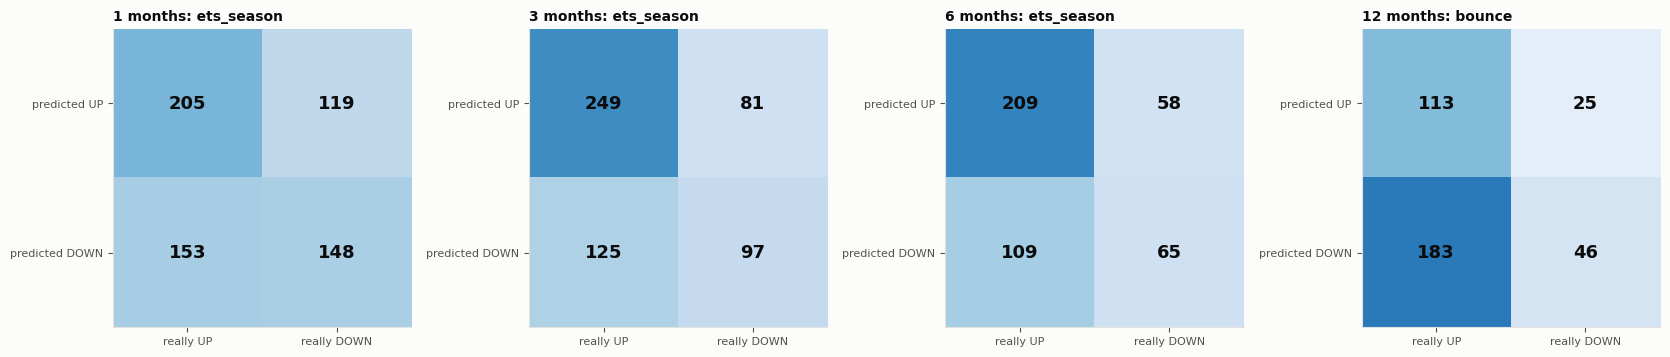

In [41]:
import time; t0 = time.time()
# ---------- practice on the TRAINING months only ----------
train_origins = pd.date_range(PRACTICE_START, CUT, freq=PRACTICE_STEP)
dir_train = direction_rows(data, crops, train_origins, max_target=CUT)
print(f"practice done in {time.time() - t0:.0f}s | calls per horizon:", dir_train.groupby("h").size().to_dict())
print("share of months where the price really went UP:", (dir_train.groupby("h")["actual"].apply(lambda s: round((s > 0).mean() * 100))).to_dict())

tdir = judge_direction(dir_train)
print("\n=== direction practice (training months): does any rule beat 'always up'? ===")
print(tdir.to_string(index=False))
print("\nRULE: beat 'always up' by >= 3 points, range above 0, wins in both halves.")

# ---------- the exam on the HIDDEN months (once) ----------
dir_valid = direction_rows(data, crops, pd.date_range(CUT, data["date"].max(), freq="MS"))
best = tdir.sort_values("accuracy_%", ascending=False).drop_duplicates("h").sort_values("h")        # best rule per horizon on TRAINING
cms = {}
print("\n=== EXAM on the hidden months: best training rule per horizon ===")
for _, b in best.iterrows():
    cm = confusion(dir_valid, b["rule"], b["h"]); n = cm.values.sum()
    acc_rule = np.trace(cm.values) / n * 100
    base = cm["really UP"].sum() / n * 100                                                         # 'always up' = share of really-up months
    status = ("passed practice AND the exam, so USE it" if b["PASS"] and acc_rule > base else
              "passed practice but FAILED the exam (not better than 'always up')" if b["PASS"] else
              "did NOT pass practice - shown for information only")
    print(f"\n{int(b['h'])} months ahead | rule: {b['rule']} ({status})")
    print(cm.to_string()); print(f"  correct: {acc_rule:.0f}%   |   'always up' would be correct: {base:.0f}%   |   forecasts: {n}")
    cms[f"{int(b['h'])} months: {b['rule']}"] = cm
plot_confusion(cms)

In [42]:
# ===== 8.4  Functions: the final forecaster  get_price_forecast(crop, months_ahead) =====
STALE_AFTER_MONTHS = 3                                    # warn when the newest real price is older than this

def make_forecaster(data, crops, widths, labels, hit_by_label, hit_by_h, coverage):
    """Naive forecast (the last real price) + 80% prediction interval + an honest accuracy message.
       widths, labels come from ALL months (8.1, 8.2). hit_by_label, hit_by_h, coverage come from the hidden-month checks."""
    allowed = list(HORIZONS)

    def get_price_forecast(crop, months_ahead=1):
        if crop not in crops:
            raise ValueError(f"'{crop}' is not available (no complete price history). Crops: {crops}")
        if not 1 <= months_ahead <= max(allowed):
            raise ValueError(f"months_ahead must be between 1 and {max(allowed)}")
        h = next(k for k in allowed if k >= months_ahead)           # tested horizons only; in between -> the next larger one (wider range)
        g = data[data["crop"] == crop].set_index("date")
        last = g.index[g["source"] == "real"].max()                 # newest REAL price
        y = np.log(g["price_per_kg"].astype(float)).asfreq("MS")[:last]
        sigma = y.diff().dropna().iloc[-VOL_MONTHS:].std()          # how wild this crop has been recently
        f = y.iloc[-1]
        low, high = (np.exp(f + widths.loc[h, "low_z"] * sigma), np.exp(f + widths.loc[h, "high_z"] * sigma))
        if h == 1:
            lab = labels.loc[(1, crop), "label"]
            msg = (f"{lab.capitalize()} confidence. For crops like this, the forecast landed within 10% of the real price "
                   f"{hit_by_label[lab]:.0f}% of the time on months we hid.")
        elif h == 3:
            lab = "medium"
            msg = f"Moderate confidence. Across crops, the 3-month forecast landed within 10% of the real price {hit_by_h[3]:.0f}% of the time."
        else:
            lab = "low"
            msg = (f"Very uncertain. Across crops, the {h}-month forecast landed within 10% of the real price only {hit_by_h[h]:.0f}% of the time. "
                   "Use the range as a guide, not a promise.")
        age = (pd.Timestamp.today().year - last.year) * 12 + pd.Timestamp.today().month - last.month
        return {"crop": crop, "model": "naive + 80% prediction interval", "months_ahead": months_ahead, "horizon_used": h,
                "data_through": last.strftime("%Y-%m"), "target_month": (last + pd.DateOffset(months=h)).strftime("%Y-%m"),
                "last_price_per_kg": round(float(np.exp(f)), 1), "forecast_per_kg": round(float(np.exp(f)), 1),
                "low_per_kg": round(float(low), 1), "high_per_kg": round(float(high), 1),
                "confidence": lab, "message": msg + f" In tests, the range held the real price {coverage[h]:.0f}% of the time (target 80%).",
                "warning": f"Newest real price is from {last:%b %Y} ({age} months old). Refresh the data before use." if age > STALE_AFTER_MONTHS else ""}
    return get_price_forecast

def forecast_table(get_price_forecast, crops, horizons=HORIZONS):
    """Every crop at every tested horizon, one row each (for the app, or to save as a file)."""
    return pd.DataFrame([get_price_forecast(c, h) for c in crops for h in horizons])

def plot_fan(data, get_price_forecast, crop_list):
    """Last 3 years of real + filled prices, then the forecast with its 80% range at 1, 3, 6 and 12 months."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for ax, crop in zip(axes.ravel(), crop_list):
        g = data[data["crop"] == crop].set_index("date")["price_per_kg"].astype(float).asfreq("MS")
        ax.plot(g.iloc[-36:].index, g.iloc[-36:].values, color=INK, lw=1.8)
        f = pd.DataFrame([get_price_forecast(crop, h) for h in HORIZONS]); t = pd.to_datetime(f["target_month"])
        ax.fill_between(t, f["low_per_kg"], f["high_per_kg"], color=BLUE, alpha=0.22, label="80% range")
        ax.plot(t, f["forecast_per_kg"], color=BLUE, lw=2, marker="o", label="naive forecast")
        ax.set_title(crop, loc="left", fontsize=11, fontweight="bold"); ax.set_ylabel("price per kg")
    axes[0, 0].legend(frameon=False, fontsize=8)
    fig.suptitle("Last 3 years + forecast 1, 3, 6 and 12 months ahead", x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout(); plt.show()


tomatoes | 1 month(s) ahead | from 2023-12 to 2024-01
  price per kg: 67.7  (80% range 57.6 to 81.2)  | confidence: high
   High confidence. For crops like this, the forecast landed within 10% of the real price 82% of the time on months we hid. In tests, the range held the real price 84% of the time (target 80%).

maize, grain, dry | 3 month(s) ahead | from 2023-12 to 2024-03
  price per kg: 49.1  (80% range 42.3 to 59.0)  | confidence: medium
   Moderate confidence. Across crops, the 3-month forecast landed within 10% of the real price 52% of the time. In tests, the range held the real price 81% of the time (target 80%).

kales/sukuma wiki | 12 month(s) ahead | from 2023-12 to 2024-12
  price per kg: 32.4  (80% range 26.3 to 46.6)  | confidence: low
   Very uncertain. Across crops, the 12-month forecast landed within 10% of the real price only 26% of the time. Use the range as a guide, not a promise. In tests, the range held the real price 78% of the time (target 80%).

ALL CHECKS PA

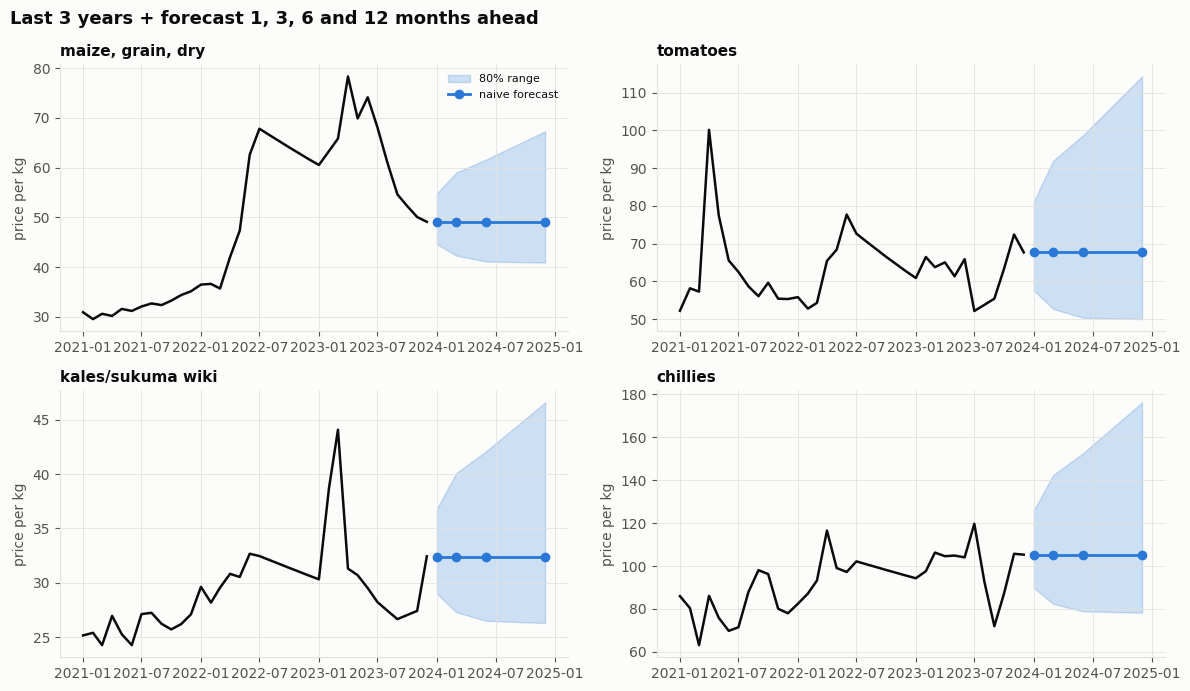

In [43]:
# the numbers the messages quote: measured on the HIDDEN months (from 8.1 and 8.2)
hit_by_label = check_labels(test, labels).xs(1, level="h")["hit_on_hidden_months_%"].to_dict()        # {'high': 82, 'medium': 62, ...}
hit_by_h = (test.assign(hit=test["pct_error"] <= HIT).groupby("h")["hit"].mean() * 100).to_dict()
coverage = chk["inside_range_%"].to_dict()

labels_all = accuracy_labels(errs)                        # final labels: learned from ALL months now that the check is done
get_price_forecast = make_forecaster(data, crops, widths_all, labels_all, hit_by_label, hit_by_h, coverage)

# ---------- try it ----------
for crop, h in [("tomatoes", 1), ("maize, grain, dry", 3), ("kales/sukuma wiki", 12)]:
    r = get_price_forecast(crop, h)
    print(f"\n{r['crop']} | {h} month(s) ahead | from {r['data_through']} to {r['target_month']}")
    print(f"  price per kg: {r['forecast_per_kg']}  (80% range {r['low_per_kg']} to {r['high_per_kg']})  | confidence: {r['confidence']}")
    print("  ", r["message"])
    if r["warning"]: print("   WARNING:", r["warning"])

# ---------- checks ----------
table = forecast_table(get_price_forecast, crops)
assert len(table) == len(crops) * len(HORIZONS)
assert (table["low_per_kg"] < table["forecast_per_kg"]).all() and (table["forecast_per_kg"] < table["high_per_kg"]).all()
assert (table["low_per_kg"] > 0).all()
w = table.assign(w=(table["high_per_kg"] - table["low_per_kg"]) / table["forecast_per_kg"]).groupby("horizon_used")["w"].median()
assert w.is_monotonic_increasing, "ranges must widen with the horizon"
assert get_price_forecast("tomatoes", 2)["horizon_used"] == 3                                       # untested horizon -> next larger, wider
try:
    get_price_forecast("wheat", 1); raise SystemExit("wheat should be refused")
except ValueError:
    pass
print("\nALL CHECKS PASSED | median range width (% of forecast):", (w * 100).round(0).to_dict())
table.to_csv("price_forecasts.csv", index=False); print("saved price_forecasts.csv:", table.shape)
plot_fan(data, get_price_forecast, ["maize, grain, dry", "tomatoes", "kales/sukuma wiki", "chillies"])

In [44]:
fixed_ok = np.allclose(errs["pct_error"], (np.exp(-errs["err"]) - 1).abs() * 100)
print("errs uses the corrected formula:", fixed_ok)
print("3-month hit rate on hidden months:", round((test[test["h"] == 3]["pct_error"] <= HIT).mean() * 100, 1), "(should be about 52)")

errs uses the corrected formula: True
3-month hit rate on hidden months: 52.4 (should be about 52)


In [45]:
# ===== A.0  Install the HTML table reader (one time) =====
%pip install lxml

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
# ===== A.1  Functions: read one KAMIS page =====
import pandas as pd
import requests
from io import StringIO

def read_kamis(url):
    # download the page, return the biggest table on it
    r = requests.get(url, headers={"User-Agent": "AgroTech-research"}, timeout=60)
    r.raise_for_status()
    tables = pd.read_html(StringIO(r.text))
    return max(tables, key=len)

def inspect_kamis(df):
    # what did we get? rows, columns, date range, crops
    print("rows, columns:", df.shape)
    print("columns:", df.columns.tolist())
    d = pd.to_datetime(df["Date"], errors="coerce")
    print("dates:", d.min().date(), "to", d.max().date())
    print("commodities:", df["Commodity"].nunique())
    print(df["Commodity"].value_counts().head(10).to_string())
    print(df.head().to_string())

In [47]:
# ===== A.2  Run =====
URL = "https://kamis.kilimo.go.ke/site/market/30?product=&per_page=3000"
kamis = read_kamis(URL)
inspect_kamis(kamis)

rows, columns: (3000, 10)
columns: ['Commodity', 'Classification', 'Grade', 'Sex', 'Market', 'Wholesale', 'Retail', 'Supply Volume', 'County', 'Date']
dates: 2025-05-31 to 2026-11-06
commodities: 1
Commodity
Dry Maize    3000
   Commodity Classification Grade Sex                   Market Wholesale    Retail  Supply Volume       County        Date
0  Dry Maize    White Maize     -   -                   Mumias         -  54.55/Kg            NaN     Kakamega  2026-11-06
1  Dry Maize   Yellow Maize     -   -                   Oyugis  66.67/Kg  75.00/Kg         1800.0     Homa-bay  2026-11-06
2  Dry Maize    White Maize     -   -                   Oyugis  57.78/Kg  65.00/Kg        18000.0     Homa-bay  2026-11-06
3  Dry Maize    White Maize     -   -  Cheptiret - Uasin Gishu  50.00/Kg  60.00/Kg         2500.0  Uasin-Gishu  2026-11-06
4  Dry Maize    White Maize     -   -               Gakoromone  44.44/Kg  46.67/Kg        22000.0         Meru  2026-11-06


In [48]:
# ===== B.1  Functions: follow the "next" button =====
import time
from urllib.parse import urljoin
import lxml.html

HEADERS = {"User-Agent": "AgroTech-research"}

def get_html(url):
    r = requests.get(url, headers=HEADERS, timeout=60)
    r.raise_for_status()
    return r.text

def next_link(url, html):
    # find the ">" button; return its full address, or None on the last page
    tree = lxml.html.fromstring(html)
    for a in tree.xpath("//a[@href]"):
        if a.text_content().strip() in (">", "›", "Next"):
            href = a.get("href")
            if href and not href.startswith("#"):
                return urljoin(url, href)
    return None

def table_of(html):
    return max(pd.read_html(StringIO(html)), key=len)

In [49]:
# ===== B.2  Test first: what is the address of page 2? =====
html1 = get_html(URL)
print(next_link(URL, html1))

https://kamis.kilimo.go.ke/site/market/3000?product=&per_page=3000


In [50]:
# ===== B.3  Function: read every page, politely =====
def read_all_pages(start_url, max_pages=20, pause=2):
    frames, seen, url = [], set(), start_url
    for i in range(max_pages):
        if url in seen:
            break
        seen.add(url)
        html = get_html(url)
        df = table_of(html)
        frames.append(df)
        d = pd.to_datetime(df["Date"], errors="coerce")
        print(f"page {i+1}: {len(df)} rows | {d.min().date()} to {d.max().date()} | crops: {df['Commodity'].nunique()}")
        url = next_link(url, html)
        if url is None:
            break
        time.sleep(pause)
    return pd.concat(frames, ignore_index=True)

In [51]:
# ===== B.4  Run and save the raw copy =====
raw_kamis = read_all_pages(URL)
print("total rows:", raw_kamis.shape)
raw_kamis.to_csv("kamis_raw.csv", index=False)

page 1: 3000 rows | 2025-05-31 to 2026-11-06 | crops: 1
page 2: 3000 rows | 2023-12-14 to 2025-06-04 | crops: 1
page 3: 3000 rows | 2023-05-22 to 2023-12-14 | crops: 1
page 4: 3000 rows | 2022-12-22 to 2023-05-22 | crops: 1
page 5: 3000 rows | 2022-08-17 to 2022-12-22 | crops: 1
page 6: 3000 rows | 2022-03-23 to 2022-08-17 | crops: 1
page 7: 3000 rows | 2021-10-16 to 2022-03-23 | crops: 1
page 8: 3000 rows | 2021-05-24 to 2021-10-16 | crops: 1
page 9: 3000 rows | 2013-03-06 to 2021-05-24 | crops: 1
page 10: 3000 rows | 2009-08-14 to 2013-03-06 | crops: 1
page 11: 3000 rows | 2005-02-08 to 2009-08-12 | crops: 1
page 12: 26 rows | 2005-02-01 to 2005-02-08 | crops: 1
total rows: (33026, 10)


In [52]:
# ===== C.1  Functions: text prices -> numbers =====
def tidy_kamis(raw):
    df = raw.copy()
    df["date"] = pd.to_datetime(df["Date"], errors="coerce")
    for col in ["Wholesale", "Retail"]:
        s = df[col].astype(str).str.replace(",", "", regex=False)
        df[col + "_unit"] = s.str.extract(r"/\s*(\w+)\s*$")[0]
        df[col.lower()] = pd.to_numeric(s.str.extract(r"([\d.]+)")[0], errors="coerce")
    df["month"] = df["date"].dt.to_period("M")
    return df

def units_report(df):
    print("wholesale units:", df["Wholesale_unit"].value_counts(dropna=False).to_dict())
    print("retail units:   ", df["Retail_unit"].value_counts(dropna=False).to_dict())
    print("classification: ", df["Classification"].value_counts().to_dict())
    print("wholesale missing %:", round(df["wholesale"].isna().mean() * 100, 1))
    print("duplicate (market, class, date) rows:", df.duplicated(["Market", "Classification", "date"]).sum())

In [53]:
# ===== C.2  Functions: how thick is each month? =====
def monthly_counts(df):
    ok = df.dropna(subset=["wholesale"])
    return ok.groupby("month").agg(rows=("wholesale", "size"),
                                   markets=("Market", "nunique"),
                                   median_price=("wholesale", "median"))

def yearly_summary(m):
    m = m.copy()
    m["year"] = m.index.year
    return m.groupby("year").agg(months_with_data=("rows", "size"),
                                 rows_per_month=("rows", "median"),
                                 markets_per_month=("markets", "median"),
                                 fewest_markets=("markets", "min"),
                                 median_price=("median_price", "median")).round(1)

In [54]:
# ===== C.3  Run =====
kamis_t = tidy_kamis(raw_kamis)
units_report(kamis_t)
mc = monthly_counts(kamis_t)
print("\nmonths with data:", len(mc), "| first:", mc.index.min(), "| last:", mc.index.max())
print(yearly_summary(mc).to_string())

wholesale units: {'Kg': 29018, nan: 2067, 'Kgs': 1940, 'kg': 1}
retail units:    {'Kg': 22536, nan: 8465, 'Kgs': 2025}
classification:  {'White Maize': 16968, '-': 8193, 'Mixed-Traditional': 5659, 'Yellow Maize': 2205, 'IRR': 1}
wholesale missing %: 6.3
duplicate (market, class, date) rows: 2947

months with data: 115 | first: 2005-02 | last: 2026-11
      months_with_data  rows_per_month  markets_per_month  fewest_markets  median_price
year                                                                                   
2005                 9            98.0               11.0               5          15.6
2008                 8           143.5               15.0              10          22.2
2009                11           135.0               14.0              13          27.8
2011                 9           190.0               19.0              11          33.3
2013                12           175.5               16.5              11          32.2
2021                 8         

In [55]:
# ===== D.1  Functions: thin months and duplicates =====
def thin_months(mc, min_markets=10, since="2021-01"):
    # months (since 2021) where fewer than 10 markets reported
    return mc[(mc["markets"] < min_markets) & (mc.index >= pd.Period(since))]

def duplicate_report(df):
    key = ["Market", "Classification", "date"]
    d = df[df.duplicated(key, keep=False)].sort_values(key)
    g = d.groupby(key)["wholesale"].agg(n="size", n_prices="nunique")
    print("duplicate groups:", len(g), "| rows inside them:", len(d))
    print("groups with the SAME price repeated:", (g["n_prices"] <= 1).sum(),
          "| groups with DIFFERENT prices:", (g["n_prices"] > 1).sum())
    print("rows by year:", d["date"].dt.year.value_counts().sort_index().to_dict())
    print("grades inside duplicates:", d["Grade"].value_counts().to_dict())
    print("\nexamples:")
    print(d[["Market", "Classification", "Grade", "wholesale", "retail",
             "Supply Volume", "date"]].head(10).to_string())

In [56]:
# ===== D.2  Run =====
print("months since 2021 with fewer than 10 markets:")
print(thin_months(mc).to_string())
print()
duplicate_report(kamis_t)

months since 2021 with fewer than 10 markets:
         rows  markets  median_price
month                               
2024-11     3        1         37.78
2025-01     6        3         40.78
2025-02     9        5         42.22
2025-03    10        4         43.61
2025-04     4        2         60.00

duplicate groups: 1153 | rows inside them: 4100
groups with the SAME price repeated: 761 | groups with DIFFERENT prices: 392
rows by year: {2005: 196, 2008: 11, 2009: 350, 2011: 22, 2013: 102, 2021: 2153, 2022: 438, 2023: 349, 2024: 223, 2025: 189, 2026: 67}
grades inside duplicates: {'-': 4100}

examples:
      Market     Classification Grade  wholesale  retail  Supply Volume       date
24043  Ahero  Mixed-Traditional     -      27.78    40.0         9000.0 2021-05-24
24163  Ahero  Mixed-Traditional     -      30.00    40.0        10800.0 2021-05-24
24258  Ahero  Mixed-Traditional     -      33.33    40.0        10800.0 2021-05-24
8897   Ahero  Mixed-Traditional     -      95.00   100

In [57]:
# ===== E.1  Functions: KAMIS maize as a monthly national price =====
CLASS_SETS = {"white": ["White Maize"],
              "white+mixed+yellow": ["White Maize", "Mixed-Traditional", "Yellow Maize"],
              "all rows": None}

def collapse(g, how):
    # one price for one market on one day
    p = g["wholesale"]
    if how == "median":
        return p.median()
    w = g["Supply Volume"].fillna(0)
    return np.average(p, weights=w) if w.sum() > 0 else p.mean()

def monthly_series(df, classes, how, min_markets=10):
    d = df.dropna(subset=["wholesale"])
    if classes:
        d = d[d["Classification"].isin(classes)]
    md = (d.groupby(["Market", "month", "date"])
            .apply(lambda g: collapse(g, how), include_groups=False)
            .rename("p").reset_index())                       # market-day price
    mm = md.groupby(["Market", "month"])["p"].mean().reset_index()   # market-month
    out = mm.groupby("month").agg(price=("p", "mean"), markets=("Market", "nunique"))
    return out[out["markets"] >= min_markets]                 # national month, thin months dropped

In [58]:
# ===== E.2  Functions: compare with KNBS on the shared months =====
def knbs_maize(data, crop="maize, grain, dry"):
    k = data[(data["crop"] == crop) & (data["source"] == "real")].copy()
    k["month"] = pd.to_datetime(k["date"]).dt.to_period("M")
    return k.set_index("month")["price_per_kg"]

def compare(kamis_m, knbs):
    j = pd.concat([kamis_m["price"].rename("kamis"), knbs.rename("knbs")], axis=1, join="inner")
    r = np.log(j["kamis"] / j["knbs"])
    return {"shared months": len(j),
            "median abs diff %": round(abs(np.exp(r) - 1).median() * 100, 1),
            "bias % (KAMIS vs KNBS)": round((np.exp(r.mean()) - 1) * 100, 1),
            "corr of log prices": round(np.corrcoef(np.log(j["kamis"]), np.log(j["knbs"]))[0, 1], 3)}

In [59]:
# ===== E.3  Run: six versions =====
knbs = knbs_maize(data)
print("KNBS maize real months:", len(knbs), "| first:", knbs.index.min(), "| last:", knbs.index.max())
rows = []
for cname, classes in CLASS_SETS.items():
    for how in ["median", "weighted"]:
        res = compare(monthly_series(kamis_t, classes, how), knbs)
        rows.append({"maize types": cname, "market-day price": how, **res})
overlap = pd.DataFrame(rows).sort_values("median abs diff %")
print(overlap.to_string(index=False))

KNBS maize real months: 122 | first: 2012-01 | last: 2023-12
       maize types market-day price  shared months  median abs diff %  bias % (KAMIS vs KNBS)  corr of log prices
          all rows           median             37                2.9                    18.1               0.849
          all rows         weighted             37                3.4                    18.1               0.856
white+mixed+yellow           median             25               16.7                    27.7               0.770
             white         weighted             25               16.9                    24.7               0.775
             white           median             25               17.0                    23.7               0.779
white+mixed+yellow         weighted             25               18.2                    27.6               0.782


In [60]:
# ===== F.1  Functions: month by month, and a fair six-way comparison =====
def month_by_month(kamis_m, knbs):
    j = pd.concat([kamis_m["price"].rename("kamis"), kamis_m["markets"],
                   knbs.rename("knbs")], axis=1, join="inner")
    j["diff_%"] = ((j["kamis"] / j["knbs"] - 1) * 100).round(1)
    j["flag"] = np.where(j["diff_%"].abs() > 10, "<<<", "")
    return j.round(1)

def same_months_table(variants, knbs):
    # score every version on the months ALL versions share
    common = None
    for m in variants.values():
        idx = m.index.intersection(knbs.index)
        common = idx if common is None else common.intersection(idx)
    rows = [{"version": name, "months": len(common),
             **{k: v for k, v in compare(m.loc[common], knbs.loc[common]).items() if k != "shared months"}}
            for name, m in variants.items()]
    return pd.DataFrame(rows).sort_values("median abs diff %")

In [61]:
# ===== F.2  Run =====
variants = {f"{c} | {h}": monthly_series(kamis_t, cl, h)
            for c, cl in CLASS_SETS.items() for h in ["median", "weighted"]}

# (a) the winner, month by month
mbm = month_by_month(variants["all rows | median"], knbs)
print(mbm.to_string())
print("\nflagged months by year:", mbm[mbm["flag"] != ""].index.year.value_counts().sort_index().to_dict())

# (b) all six on the same months
print("\n", same_months_table(variants, knbs).to_string(index=False))

         kamis  markets  knbs  diff_% flag
month                                     
2013-01   31.7       20  31.8    -0.4     
2013-02   31.3       21  31.5    -0.5     
2013-03   31.7       18  31.9    -0.5     
2013-04   31.8       15  31.0     2.7     
2013-05   31.3       16  31.5    -0.7     
2013-06   30.6       17  30.5     0.2     
2013-07   30.6       17  30.2     1.2     
2013-08   30.2       15  30.0     0.6     
2013-09   31.8       15  31.4     1.2     
2013-10   32.9       15  32.7     0.7     
2013-11   33.4       17  33.7    -1.0     
2013-12   32.6       11  33.7    -3.3     
2021-05   30.5      143  31.6    -3.5     
2021-06   31.3       79  31.2     0.3     
2021-07   31.5       80  32.1    -1.6     
2021-08   33.4      115  32.7     2.2     
2021-09   40.9      156  32.3    26.5  <<<
2021-10   68.3      149  33.2   105.4  <<<
2021-11   58.4      141  34.4    69.8  <<<
2021-12   66.1      107  35.1    88.2  <<<
2022-01   62.3      111  36.5    70.8  <<<
2022-02   3

In [62]:
# ===== G.1  Function: what do the prices look like in a month? =====
def price_profile(df, months):
    d = df.dropna(subset=["wholesale"])
    for m in months:
        x = d[d["month"] == pd.Period(m)]
        q = x["wholesale"].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(1).tolist()
        print(f"\n{m} | rows {len(x)} | quantiles 5/25/50/75/95%: {q} | max {x['wholesale'].max()}")
        print(x.nlargest(5, "wholesale")[["Market", "County", "Classification", "wholesale",
                                           "retail", "Supply Volume", "date"]].to_string())

In [63]:
# ===== G.2  Function: monthly series, mean OR median across markets =====
def monthly_series_v2(df, classes, how, across, min_markets=10):
    d = df.dropna(subset=["wholesale"])
    if classes:
        d = d[d["Classification"].isin(classes)]
    md = (d.groupby(["Market", "month", "date"])
            .apply(lambda g: collapse(g, how), include_groups=False)
            .rename("p").reset_index())
    mm = md.groupby(["Market", "month"])["p"].mean().reset_index()
    out = mm.groupby("month").agg(price=("p", across), markets=("Market", "nunique"))
    return out[out["markets"] >= min_markets]

In [64]:
# ===== G.3  Run =====
# test 1: good months vs bad months
price_profile(kamis_t, ["2021-08", "2021-10", "2023-11", "2023-12"])

# test 2: median across markets instead of the mean
v2 = {f"{c} | across markets: {a}": monthly_series_v2(kamis_t, cl, "median", a)
      for c, cl in CLASS_SETS.items() for a in ["mean", "median"]}
print("\n", same_months_table(v2, knbs).to_string(index=False))

best = month_by_month(v2["all rows | across markets: median"], knbs)
print("\nmonths still off by more than 10% (all rows, median across markets):")
print(best[best["flag"] != ""].to_string())
print("flagged by year:", best[best["flag"] != ""].index.year.value_counts().sort_index().to_dict())


2021-08 | rows 510 | quantiles 5/25/50/75/95%: [22.6, 28.0, 31.1, 35.0, 45.0] | max 300.0
                Market   County     Classification  wholesale  retail  Supply Volume       date
22590           Kibuye   Kisumu                  -      300.0   300.0            NaN 2021-08-03
22594           Keumbu    Kisii  Mixed-Traditional      280.0   300.0        12000.0 2021-08-03
22574     Ngong market  Kajiado                  -      150.0   160.0           20.0 2021-08-04
22101  Nakuru Wakulima   Nakuru                  -      136.0   150.0            0.0 2021-08-31
22116  Nakuru Wakulima   Nakuru                  -      136.0   150.0            0.0 2021-08-30

2021-10 | rows 631 | quantiles 5/25/50/75/95%: [24.4, 28.9, 31.1, 38.4, 67.5] | max 4300.0
                Market       County     Classification  wholesale  retail  Supply Volume       date
21124        Oldonyiro       Isiolo  Mixed-Traditional     4300.0    70.0          900.0 2021-10-12
21183          Sibanga  Trans-Nzoia  Mixe

In [65]:
# ===== H.1  Functions: KAMIS maize, gaps, join, and scoring =====
def kamis_maize_series(kamis_t, min_markets=10):
    thick = monthly_series_v2(kamis_t, None, "median", "median", min_markets)   # trusted months
    thin = monthly_series_v2(kamis_t, None, "median", "median", 1)              # every month with any data
    return thick, thin

def gap_report(thick, thin, start="2023-12", end="2026-10"):
    want = pd.period_range(start, end, freq="M")
    no_data = [str(m) for m in want if m not in thin.index]
    too_thin = [str(m) for m in want if m in thin.index and m not in thick.index]
    return no_data, too_thin

def seam_table(knbs, thick, start="2023-07", end="2024-06"):
    idx = pd.period_range(start, end, freq="M")
    return pd.DataFrame({"knbs": knbs.reindex(idx), "kamis": thick["price"].reindex(idx),
                         "kamis_markets": thick["markets"].reindex(idx)}).round(1)

def score_forecasts(get_price_forecast, crop, thick):
    rows = []
    for h in HORIZONS:
        r = get_price_forecast(crop, h)
        t = pd.Period(r["target_month"])
        actual = thick["price"].get(t, np.nan)
        err = abs(r["forecast_per_kg"] - actual) / actual * 100 if pd.notna(actual) else np.nan
        rows.append({"horizon": h, "target": str(t), "forecast": r["forecast_per_kg"],
                     "low": r["low_per_kg"], "high": r["high_per_kg"], "actual": round(actual, 1),
                     "error_%": round(err, 1), "within_10%": err <= HIT,
                     "inside_range": r["low_per_kg"] <= actual <= r["high_per_kg"]})
    return pd.DataFrame(rows)

In [66]:
# ===== H.2  Run =====
CROP = "maize, grain, dry"
thick, thin = kamis_maize_series(kamis_t)

no_data, too_thin = gap_report(thick, thin)
print("months with NO KAMIS data:", no_data)
print("months with data but fewer than 10 markets:", too_thin)

print("\n--- the join at December 2023 (KNBS then KAMIS) ---")
print(seam_table(knbs, thick).to_string())

print("\n--- December 2023 forecasts vs what KAMIS says happened ---")
print(score_forecasts(get_price_forecast, CROP, thick).to_string(index=False))

print("\n--- KAMIS maize, trusted months, Dec 2023 to Oct 2026 ---")
print(thick.loc["2023-12":].round(1).to_string())

months with NO KAMIS data: ['2024-12']
months with data but fewer than 10 markets: ['2024-11', '2025-01', '2025-02', '2025-03', '2025-04']

--- the join at December 2023 (KNBS then KAMIS) ---
         knbs  kamis  kamis_markets
2023-07  68.1   69.2            117
2023-08   NaN   56.4             99
2023-09  54.6   53.3             72
2023-10   NaN   51.7             64
2023-11  50.1   50.0             59
2023-12  49.1   49.4             50
2024-01   NaN   48.0             47
2024-02   NaN   43.5             48
2024-03   NaN   41.5             48
2024-04   NaN   38.9             53
2024-05   NaN   37.6             48
2024-06   NaN   36.2             49

--- December 2023 forecasts vs what KAMIS says happened ---
 horizon  target  forecast  low  high  actual  error_%  within_10%  inside_range
       1 2024-01      49.1 44.6  54.8    48.0      2.3        True          True
       3 2024-03      49.1 42.3  59.0    41.5     18.3       False         False
       6 2024-06      49.1 41.1  61.

In [67]:
# ===== I.1  Function: list the dropdown options on the page =====
def dropdown_options(url):
    tree = lxml.html.fromstring(get_html(url))
    rows = []
    for s in tree.xpath("//select"):
        for o in s.xpath(".//option"):
            rows.append({"select_name": s.get("name"), "select_id": s.get("id"),
                         "value": o.get("value"), "label": o.text_content().strip()})
    return pd.DataFrame(rows)

In [68]:
# ===== I.2  Run =====
opts = dropdown_options(URL)
print("dropdowns on the page:", opts.groupby(["select_name", "select_id"]).size().to_dict())
prod = opts[opts["select_name"] == "product"]
print("\nproduct options:", len(prod))
print(prod[["value", "label"]].to_string(index=False))

dropdowns on the page: {('per_page', 'selPerPage'): 6, ('product', 'selProduct'): 191}

product options: 191
value                             label
                      --Please select--
    1                         Dry Maize
    2                       Red Sorghum
    3                             Wheat
    4                              Rice
   10                       Green Grams
   12                       Ground Nuts
   29       Beans Red Haricot (Wairimu)
   30              Beans (Yellow-Green)
   50           Dolichos lablab (Njahi)
   51                 Pearl Rush Millet
   54                     Finger Millet
   56                     White Sorghum
   57                  Red Irish potato
   58                          Cabbages
   59                    Sweet potatoes
   60                           Carrots
   61                          Tomatoes
   64                    Beans Rosecoco
   65                Beans (Mwitemania)
   66                Beans (Mwezi Moja)
   67      

In [69]:
# ===== J.1  Our crop -> KAMIS product ID (matched by name; checked later against KNBS) =====
KAMIS_ID = {
    "maize, grain, dry": 1,   "green maize": 149,       "finger millet": 54,
    "green grams": 10,        "groundnuts": 12,         "cowpeas": 189,
    "beans (canadian wonder)": 67, "beans (mwezi moja)": 66,
    "beans (mwitemania)": 65, "beans (rosecoco)": 64,
    "irish potato (red)": 57, "irish potato (white)": 163,
    "sweet potato": 59,       "cassava fresh": 162,
    "tomatoes": 61,           "cabbages": 58,           "kales/sukuma wiki": 154,
    "carrots": 60,            "onions, dry": 158,       "onions, spring": 159,
    "capsicums": 172,         "cucumber": 173,          "egg plant (brinjals)": 174,
    "cauliflower": 175,       "chillies": 165,          "lettuce": 166,
    "peas, fresh": 160,       "avocado": 142,           "oranges": 127,
    "lemons": 145,            "limes": 148,             "passion fruits": 125,
    "pawpaw": 152,            "pineapples": 151,        "eggs": 72,
    "banana (ripe)": 226,     "banana (cooking/plantain)": 255,
}

In [70]:
# ===== J.2  Function: address for one product =====
BASE = "https://kamis.kilimo.go.ke/site/market/30"

def product_url(pid, per_page=3000):
    return f"{BASE}?product={pid}&per_page={per_page}"

In [71]:
# ===== J.3  Test with tomatoes only =====
tom = read_all_pages(product_url(KAMIS_ID["tomatoes"]))
print("\ntotal rows:", tom.shape)
print(tom["Commodity"].value_counts().to_dict())
print("wholesale units:", tom["Wholesale"].astype(str).str.extract(r"/\s*(\w+)\s*$")[0].value_counts(dropna=False).to_dict())
print(tom.head(3).to_string())

page 1: 3000 rows | 2025-06-10 to 2026-11-07 | crops: 1
page 2: 3000 rows | 2024-01-08 to 2025-06-13 | crops: 1
page 3: 3000 rows | 2023-06-07 to 2024-01-08 | crops: 1
page 4: 3000 rows | 2023-01-27 to 2023-06-07 | crops: 1
page 5: 3000 rows | 2022-09-18 to 2023-01-27 | crops: 1
page 6: 3000 rows | 2022-05-17 to 2022-09-18 | crops: 1
page 7: 3000 rows | 2021-12-17 to 2022-05-17 | crops: 1
page 8: 3000 rows | 2021-08-06 to 2021-12-17 | crops: 1
page 9: 3000 rows | 2013-12-11 to 2021-08-06 | crops: 1
page 10: 3000 rows | 2011-03-25 to 2013-12-11 | crops: 1
page 11: 3000 rows | 2008-07-18 to 2011-03-25 | crops: 1
page 12: 1460 rows | 2005-02-01 to 2008-07-17 | crops: 1

total rows: (34460, 10)
{'Tomatoes': 34460}
wholesale units: {'Kg': 31726, nan: 2733, 'kg': 1}
  Commodity Classification Grade Sex            Market Wholesale     Retail  Supply Volume     County        Date
0  Tomatoes              -     -   -  Ngurubani Market  37.50/Kg   55.00/Kg         2560.0  Kirinyaga  2026-11-07
1

In [72]:
# ===== K.1  Functions: download every crop, one file each =====
import os, io, contextlib

RAW_DIR = "kamis_raw"
os.makedirs(RAW_DIR, exist_ok=True)

EXTRA_ID = {"banana (plantain)": 256, "beans (rosecoco nyayo)": 183}   # read too, so the KNBS test can pick the right match
ALL_ID = {**KAMIS_ID, **EXTRA_ID}

def raw_path(pid):
    return os.path.join(RAW_DIR, f"{pid}.csv")

def read_crop(pid, tries=2):
    # read all pages of one product quietly; try again once if the site hiccups
    for _ in range(tries):
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                return read_all_pages(product_url(pid))
        except Exception as e:
            err = e
            time.sleep(5)
    raise err

def download_all(ids):
    failed = {}
    for name, pid in ids.items():
        if os.path.exists(raw_path(pid)):
            print(f"{name:28s} id {pid:>3} | already saved")
            continue
        try:
            t0 = time.time()
            df = read_crop(pid)
            df.to_csv(raw_path(pid), index=False)
            d = pd.to_datetime(df["Date"], errors="coerce")
            print(f"{name:28s} id {pid:>3} | rows {len(df):>6} | {d.min().date()} to {d.max().date()} | {time.time() - t0:.0f}s")
        except Exception as e:
            failed[name] = str(e)[:80]
            print(f"{name:28s} id {pid:>3} | FAILED: {failed[name]}")
        time.sleep(2)
    return failed

In [73]:
# ===== K.2  Run (about 20-30 minutes; safe to stop and run again) =====
raw_kamis.to_csv(raw_path(1), index=False)      # maize, already read
tom.to_csv(raw_path(61), index=False)           # tomatoes, already read
failed = download_all(ALL_ID)
print("\nfailed:", failed)
print("files saved:", len(os.listdir(RAW_DIR)), "of", len(ALL_ID))

maize, grain, dry            id   1 | already saved
green maize                  id 149 | already saved
finger millet                id  54 | already saved
green grams                  id  10 | already saved
groundnuts                   id  12 | already saved
cowpeas                      id 189 | already saved
beans (canadian wonder)      id  67 | already saved
beans (mwezi moja)           id  66 | already saved
beans (mwitemania)           id  65 | already saved
beans (rosecoco)             id  64 | already saved
irish potato (red)           id  57 | already saved
irish potato (white)         id 163 | already saved
sweet potato                 id  59 | already saved
cassava fresh                id 162 | already saved
tomatoes                     id  61 | already saved
cabbages                     id  58 | already saved
kales/sukuma wiki            id 154 | already saved
carrots                      id  60 | already saved
onions, dry                  id 158 | already saved
onions, spri

In [74]:
# ===== L.1  Functions: one row of the report per crop =====
KNBS_NAME = {"banana (plantain)": "banana (cooking/plantain)",     # the two extra products are compared with these KNBS series
             "beans (rosecoco nyayo)": "beans (rosecoco)"}

def load_kamis(pid):
    return tidy_kamis(pd.read_csv(raw_path(pid)))

def monthly_fast(df, min_markets=10):
    d = df.dropna(subset=["wholesale"])
    md = d.groupby(["Market", "month", "date"])["wholesale"].median().reset_index()     # one price per market per day
    mm = md.groupby(["Market", "month"])["wholesale"].mean().reset_index()              # one price per market per month
    out = mm.groupby("month").agg(price=("wholesale", "median"), markets=("Market", "nunique"))   # median across markets
    return out[out["markets"] >= min_markets]                                           # thin months dropped

def longest_hole(thick, start="2024-01", end="2026-10"):
    run = best = 0
    for m in pd.period_range(start, end, freq="M"):
        run = 0 if m in thick.index else run + 1
        best = max(best, run)
    return best

def non_kg_share(df):
    u = df["Wholesale_unit"].dropna().str.lower()
    return round((~u.isin(["kg", "kgs"])).mean() * 100, 1) if len(u) else np.nan

def crop_row(name, pid, data):
    df = load_kamis(pid)
    thick = monthly_fast(df)
    k = knbs_maize(data, KNBS_NAME.get(name, name))
    n = len(thick.index.intersection(k.index))
    res = compare(thick, k) if n >= 3 else {}
    want = pd.period_range("2024-01", "2026-10", freq="M")
    row = {"crop": name, "id": pid, "rows": len(df), "non_kg_%": non_kg_share(df),
           "shared": n,
           "diff_%": res.get("median abs diff %"), "bias_%": res.get("bias % (KAMIS vs KNBS)"),
           "corr": res.get("corr of log prices"),
           "trusted_24_26": int(sum(m in thick.index for m in want)),
           "longest_hole": longest_hole(thick),
           "last_trusted": str(thick.index.max())}
    return row, thick

In [75]:
# ===== L.2  Run (a few minutes) =====
rows, kamis_monthly = [], {}
for name, pid in ALL_ID.items():
    row, thick = crop_row(name, pid, data)
    rows.append(row)
    kamis_monthly[name] = thick

report = pd.DataFrame(rows).sort_values("diff_%", ascending=False, na_position="first")
print(report.to_string(index=False))

# save the monthly series for the next step
long = pd.concat([t.assign(crop=n).reset_index() for n, t in kamis_monthly.items()])
long.to_csv("kamis_monthly.csv", index=False)
print("\nsaved kamis_monthly.csv:", long.shape)

                     crop  id  rows  non_kg_%  shared  diff_%  bias_%  corr  trusted_24_26  longest_hole last_trusted
banana (cooking/plantain) 255 25325       0.0      37    23.6   -24.6 0.842             28             6      2026-10
                    limes 148  5689       0.0      22    16.3   -12.2 0.306              1            27      2024-07
                 cabbages  58 33802       0.0      37    15.7   -13.5 0.893             28             6      2026-11
                  lettuce 166  4245       0.0       9    15.3   -13.2 0.592              0            34      2023-10
            banana (ripe) 226 20498       0.0      37    14.3   -15.0 0.839             28             6      2026-10
     egg plant (brinjals) 174 11794       0.0      29    14.3   -12.3 0.572             23             6      2026-10
        banana (plantain) 256  5525       0.0      25    13.1    -3.8 0.803             25             6      2026-09
                  avocado 142 21487       0.0      30   

In [76]:
# ===== M.1  Function: why does this crop not match KNBS? =====
def crop_profile(name, pid, data, years=(2013, 2022, 2025)):
    df = load_kamis(pid)
    k = knbs_maize(data, KNBS_NAME.get(name, name))
    print(f"\n=== {name} (KAMIS id {pid}) ===")
    print("wholesale units:", df["Wholesale_unit"].value_counts(dropna=False).to_dict())
    print("raw wholesale text, first 3:", df["Wholesale"].head(3).tolist())
    print("classification:", df["Classification"].value_counts().head(6).to_dict())
    print("grade:", df["Grade"].value_counts().head(4).to_dict())
    recent = df[df["date"].dt.year >= 2021].dropna(subset=["wholesale"])
    top = recent["Classification"].value_counts().head(5).index
    print("median price by class, 2021+:", recent[recent["Classification"].isin(top)]
          .groupby("Classification")["wholesale"].median().round(1).to_dict())
    rows = []
    for y in years:
        d = df[df["date"].dt.year == y]
        x = d["wholesale"].dropna()
        kk = k[k.index.year == y]
        rows.append({"year": y, "kamis_rows": len(x), "kamis_markets": d["Market"].nunique(),
                     "kamis_p10": round(x.quantile(.1), 1) if len(x) else None,
                     "kamis_p50": round(x.median(), 1) if len(x) else None,
                     "kamis_p90": round(x.quantile(.9), 1) if len(x) else None,
                     "knbs_median": round(kk.median(), 1) if len(kk) else None})
    print(pd.DataFrame(rows).to_string(index=False))

In [77]:
# ===== M.2  Run: eggs and the six poor matches =====
for name in ["eggs", "banana (cooking/plantain)", "banana (ripe)", "limes",
             "egg plant (brinjals)", "avocado", "cauliflower"]:
    crop_profile(name, ALL_ID[name], data)


=== eggs (KAMIS id 72) ===
wholesale units: {nan: 13711, 'Tray': 7199}
raw wholesale text, first 3: ['400.00/Tray(30)', '500.00/Tray(30)', '-']
classification: {'Exotic/Grade': 10181, '-': 7298, 'Indigenous /Kenyeji': 3431}
grade: {'-': 20910}
median price by class, 2021+: {'-': 300.0, 'Exotic/Grade': 375.0, 'Indigenous /Kenyeji': 450.0}
 year  kamis_rows  kamis_markets  kamis_p10  kamis_p50  kamis_p90  knbs_median
 2013        1849             21      280.0      310.0      360.0        322.7
 2022        3796            132      300.0      360.0      450.0        339.5
 2025         426             29      355.0      400.0      540.0          NaN

=== banana (cooking/plantain) (KAMIS id 255) ===
wholesale units: {'Kg': 22565, nan: 2759, 'kg': 1}
raw wholesale text, first 3: ['80.00/Kg', '18.00/Kg', '-']
classification: {'-': 25325}
grade: {'-': 25325}
median price by class, 2021+: {'-': 29.2}
 year  kamis_rows  kamis_markets  kamis_p10  kamis_p50  kamis_p90  knbs_median
 2013        

In [78]:
# ===== N.1  Function: which class (or mix) matches KNBS best? =====
def class_test(name, pid, data, drop_text=None, min_rows=300, min_markets=10):
    df = load_kamis(pid)
    k = knbs_maize(data, KNBS_NAME.get(name, name))
    counts = df["Classification"].value_counts()
    variants = {"all rows": df, "classified only": df[df["Classification"] != "-"]}
    for c in counts[counts >= min_rows].index:
        variants[c] = df[df["Classification"] == c]
    if drop_text:
        variants[f"without '{drop_text}'"] = df[~df["Classification"].str.contains(drop_text, case=False, na=False)]
    want = pd.period_range("2024-01", "2026-10", freq="M")
    rows = []
    for label, d in variants.items():
        t = monthly_fast(d, min_markets)
        n = len(t.index.intersection(k.index))
        res = compare(t, k) if n >= 3 else {}
        rows.append({"crop": name, "version": label, "rows": len(d), "shared": n,
                     "diff_%": res.get("median abs diff %"),
                     "bias_%": res.get("bias % (KAMIS vs KNBS)"),
                     "corr": res.get("corr of log prices"),
                     "trusted_24_26": int(sum(m in t.index for m in want))})
    return pd.DataFrame(rows)

In [79]:
# ===== N.2  Run: eggs, avocado, banana (ripe) =====
out = pd.concat([class_test("eggs", ALL_ID["eggs"], data),
                 class_test("avocado", ALL_ID["avocado"], data),
                 class_test("banana (ripe)", ALL_ID["banana (ripe)"], data, drop_text="cooking")])
print(out.to_string(index=False))

         crop             version  rows  shared  diff_%  bias_%   corr  trusted_24_26
         eggs            all rows 20910      27     2.7    -5.7  0.552             28
         eggs     classified only 13612      16     1.0     1.1  0.987             28
         eggs        Exotic/Grade 10181      16     1.2     0.2  0.986             26
         eggs                   -  7298      11     4.2   -14.8 -0.411              0
         eggs Indigenous /Kenyeji  3431      15     7.1     9.5  0.832              1
      avocado            all rows 21487      30    12.0   -10.5  0.873             28
      avocado     classified only 14317      18    13.1   -10.6  0.593             28
      avocado               Local  8516      18    18.7   -16.4  0.434             24
      avocado                   -  7170      13     8.1   -11.0  0.522              0
      avocado              Fuerte  4065      16    12.4     2.6  0.617              8
      avocado                Hass  1736      10     8.

In [80]:
# ===== O.1  Functions: the fresh exam on KAMIS-only months =====
def approved_crops(report, extras):
    ok = ((report["diff_%"] <= 10) & (report["corr"] >= 0.9)
          & (report["shared"] >= 20) & (report["trusted_24_26"] >= 20))
    return report[ok & ~report["crop"].isin(list(extras))]["crop"].tolist()

def kamis_sigma(s, origin, window=36, min_diffs=12):
    # how wild the crop has been: std of month-to-month log changes (consecutive trusted months only)
    w = s[(s.index > origin - window) & (s.index <= origin)]
    if len(w) < 2:
        return np.nan
    full = w.reindex(pd.period_range(w.index.min(), origin, freq="M"))
    d = full.diff().dropna()
    return d.std() if len(d) >= min_diffs else np.nan

def fresh_exam(kamis_monthly, crops, widths, first="2024-01", last="2026-10"):
    first, last, rows = pd.Period(first), pd.Period(last), []
    for crop in crops:
        s = np.log(kamis_monthly[crop]["price"])
        s = s[s.index <= last]
        for origin in s.index[s.index >= pd.Period("2023-01")]:
            sig = kamis_sigma(s, origin)
            if np.isnan(sig):
                continue
            for h in HORIZONS:
                tgt = origin + h
                if tgt < first or tgt > last or tgt not in s.index:      # the target must be a NEW, trusted month
                    continue
                f, a = np.exp(s[origin]), np.exp(s[tgt])
                low = f * np.exp(widths.loc[h, "low_z"] * sig)
                high = f * np.exp(widths.loc[h, "high_z"] * sig)
                rows.append({"crop": crop, "origin": str(origin), "h": h,
                             "err": abs(f - a) / a * 100, "inside": low <= a <= high})
    return pd.DataFrame(rows)

def exam_report(ex, promised_hit, labels_all, hit_by_label):
    g = ex.groupby("h").agg(forecasts=("err", "size"), crops=("crop", "nunique"),
                            median_err=("err", "median"),
                            hit=("err", lambda e: (e <= HIT).mean() * 100),
                            inside=("inside", lambda x: x.mean() * 100)).round(1)
    g["promised_hit"] = pd.Series(promised_hit).round(1)
    g["hit_ok"] = g["hit"] >= g["promised_hit"] - 10
    g["range_ok"] = g["inside"] >= 70
    print(g.to_string())
    lab = labels_all.xs(1, level="h")["label"]
    x = ex[ex["h"] == 1].assign(label=lambda d: d["crop"].map(lab))
    by = x.groupby("label").agg(forecasts=("err", "size"),
                                hit=("err", lambda e: (e <= HIT).mean() * 100)).round(1)
    by["promised_hit"] = pd.Series(hit_by_label).round(1)
    print("\n1-month forecasts by the crop's accuracy label:")
    print(by.to_string())

In [81]:
# ===== O.2  Run =====
crops20 = approved_crops(report, EXTRA_ID)
print("approved crops:", len(crops20)); print(crops20)

ex = fresh_exam(kamis_monthly, crops20, widths_all)
print("\nfresh forecasts scored:", len(ex), "| crops:", ex["crop"].nunique(), "\n")
exam_report(ex, hit_by_h, labels_all, hit_by_label)

approved crops: 20
['pawpaw', 'kales/sukuma wiki', 'sweet potato', 'carrots', 'onions, spring', 'peas, fresh', 'oranges', 'irish potato (white)', 'cassava fresh', 'onions, dry', 'tomatoes', 'lemons', 'cowpeas', 'green grams', 'beans (mwitemania)', 'groundnuts', 'maize, grain, dry', 'beans (mwezi moja)', 'finger millet', 'beans (rosecoco)']

fresh forecasts scored: 1879 | crops: 20 

    forecasts  crops  median_err   hit  inside  promised_hit  hit_ok  range_ok
h                                                                             
1         527     20         6.3  68.3    75.7          75.2    True      True
3         486     20         9.2  53.7    79.0          52.4    True      True
6         429     20        11.1  44.5    80.4          40.6    True      True
12        437     20        13.0  38.7    74.1          26.4    True      True

1-month forecasts by the crop's accuracy label:
        forecasts   hit  promised_hit
label                                
high          4

In [82]:
# ===== P.1  Functions: the forecaster, version 2 =====
UNIT_NOTE = {"eggs": "KES per tray of 30"}                     # default is KES per kg

def fresh_numbers(ex, labels_all, hit_by_label_old):
    ex = ex.assign(hit=ex["err"] <= HIT)
    hit = (ex.groupby("h")["hit"].mean() * 100).to_dict()
    cov = (ex.groupby("h")["inside"].mean() * 100).to_dict()
    lab = labels_all.xs(1, level="h")["label"]
    x = ex[ex["h"] == 1].assign(label=lambda d: d["crop"].map(lab))
    by_label = {**hit_by_label_old, **(x.groupby("label")["hit"].mean() * 100).to_dict()}
    return hit, cov, by_label

def make_forecaster_v2(old_forecaster, kamis_monthly, kamis_crops, widths, labels, hit_h, hit_label, cov):
    def get_price_forecast(crop, months_ahead=1):
        unit = UNIT_NOTE.get(crop, "KES per kg")
        if crop not in kamis_crops:                            # the 17 crops: KNBS only, as before
            r = old_forecaster(crop, months_ahead)
            r["source"], r["unit"] = "KNBS only (data ends Dec 2023)", unit
            return r
        if not 1 <= months_ahead <= max(HORIZONS):
            raise ValueError(f"months_ahead must be between 1 and {max(HORIZONS)}")
        h = next(k for k in HORIZONS if k >= months_ahead)
        today = pd.Timestamp.today()
        last_ok = pd.Period(today, freq="M") - 1               # the current month is not finished yet
        s = np.log(kamis_monthly[crop]["price"])
        s = s[s.index <= last_ok]
        origin = s.index.max()
        sig = kamis_sigma(s, origin)
        if np.isnan(sig):
            raise ValueError(f"not enough recent KAMIS months for '{crop}'")
        f = s[origin]
        low, high = np.exp(f + widths.loc[h, "low_z"] * sig), np.exp(f + widths.loc[h, "high_z"] * sig)
        if h == 1:
            lab = labels.loc[(1, crop), "label"]
            msg = (f"{lab.capitalize()} confidence. For crops like this, the forecast landed within 10% of the real "
                   f"price {hit_label[lab]:.0f}% of the time on new months (2024 to 2026) not used to build it.")
        elif h == 3:
            lab = "medium"
            msg = f"Moderate confidence. Across crops, the 3-month forecast landed within 10% of the real price {hit_h[3]:.0f}% of the time."
        else:
            lab = "low"
            msg = (f"Very uncertain. Across crops, the {h}-month forecast landed within 10% of the real price only "
                   f"{hit_h[h]:.0f}% of the time. Use the range as a guide, not a promise.")
        age = (today.year - origin.year) * 12 + today.month - origin.month
        return {"crop": crop, "model": "naive + 80% prediction interval", "source": "KAMIS (latest) + KNBS history",
                "unit": unit, "months_ahead": months_ahead, "horizon_used": h,
                "data_through": str(origin), "target_month": str(origin + h),
                "last_price_per_kg": round(float(np.exp(f)), 1), "forecast_per_kg": round(float(np.exp(f)), 1),
                "low_per_kg": round(float(low), 1), "high_per_kg": round(float(high), 1),
                "confidence": lab, "message": msg + f" In tests, the range held the real price {cov[h]:.0f}% of the time (target 80%).",
                "warning": f"Newest real price is from {origin} ({age} months old). Refresh the data before use." if age > STALE_AFTER_MONTHS else ""}
    return get_price_forecast

In [83]:
# ===== P.2  Run and check =====
if "old_forecaster" not in globals():
    old_forecaster = get_price_forecast                        # keep the KNBS-only version; do not wrap it twice

hit_f, cov_f, lab_f = fresh_numbers(ex, labels_all, hit_by_label)
get_price_forecast = make_forecaster_v2(old_forecaster, kamis_monthly, crops20, widths_all, labels_all, hit_f, lab_f, cov_f)

for crop, h in [("maize, grain, dry", 1), ("tomatoes", 3), ("eggs", 1), ("lettuce", 1)]:
    r = get_price_forecast(crop, h)
    print(f"\n{r['crop']} | {h} month(s) ahead | from {r['data_through']} to {r['target_month']} | source: {r['source']}")
    print(f"  {r['forecast_per_kg']} {r['unit']}  (80% range {r['low_per_kg']} to {r['high_per_kg']})  | confidence: {r['confidence']}")
    print("  ", r["message"])
    if r["warning"]: print("   WARNING:", r["warning"])

table = pd.DataFrame([get_price_forecast(c, h) for c in crops for h in HORIZONS])
assert len(table) == len(crops) * len(HORIZONS)
assert (table["low_per_kg"] < table["forecast_per_kg"]).all() and (table["forecast_per_kg"] < table["high_per_kg"]).all()
assert set(table.loc[table["crop"].isin(crops20), "source"]) == {"KAMIS (latest) + KNBS history"}
assert table.loc[table["crop"] == "eggs", "unit"].eq("KES per tray of 30").all()
print("\nALL CHECKS PASSED | crops on KAMIS:", len(crops20), "| KNBS only:", len(crops) - len(crops20))
print(table.groupby("source")["warning"].apply(lambda w: (w != "").mean()).round(2).to_dict(), "<- share of forecasts with a stale-data warning")
table.to_csv("price_forecasts_v2.csv", index=False); print("saved price_forecasts_v2.csv:", table.shape)


maize, grain, dry | 1 month(s) ahead | from 2026-10 to 2026-11 | source: KAMIS (latest) + KNBS history
  45.6 KES per kg  (80% range 42.9 to 48.8)  | confidence: high
   High confidence. For crops like this, the forecast landed within 10% of the real price 71% of the time on new months (2024 to 2026) not used to build it. In tests, the range held the real price 76% of the time (target 80%).

tomatoes | 3 month(s) ahead | from 2026-10 to 2027-01 | source: KAMIS (latest) + KNBS history
  49.6 KES per kg  (80% range 37.2 to 70.7)  | confidence: medium
   Moderate confidence. Across crops, the 3-month forecast landed within 10% of the real price 54% of the time. In tests, the range held the real price 79% of the time (target 80%).

eggs | 1 month(s) ahead | from 2023-12 to 2024-01 | source: KNBS only (data ends Dec 2023)
  448.6 KES per tray of 30  (80% range 434.7 to 464.8)  | confidence: high
   High confidence. For crops like this, the forecast landed within 10% of the real price 82% o

In [84]:
# ===== Q.1  Functions: one honest set of numbers for every crop =====
def conservative(old, fresh):
    # for each number, keep the lower of the two measurements
    return {k: min(old[k], fresh[k]) if k in fresh else old[k] for k in old}

def message_for(h, lab, hit_h, hit_label, cov):
    if h == 1:
        msg = (f"{lab.capitalize()} confidence. For crops like this, the forecast landed within 10% of the real "
               f"price {hit_label[lab]:.0f}% of the time in tests on months not used to build it.")
    elif h == 3:
        msg = f"Moderate confidence. Across crops, the 3-month forecast landed within 10% of the real price {hit_h[3]:.0f}% of the time."
    else:
        msg = (f"Very uncertain. Across crops, the {h}-month forecast landed within 10% of the real price only "
               f"{hit_h[h]:.0f}% of the time. Use the range as a guide, not a promise.")
    return msg + f" The range held the real price {cov[h]:.0f}% of the time (target 80%)."

def restate(forecaster, hit_h, hit_label, cov):
    # same forecaster, same numbers, but the message uses the combined test results
    def get_price_forecast(crop, months_ahead=1):
        r = forecaster(crop, months_ahead)
        r["message"] = message_for(r["horizon_used"], r["confidence"], hit_h, hit_label, cov)
        return r
    return get_price_forecast

In [85]:
# ===== Q.2  Run and check =====
if "forecaster_v2" not in globals():
    forecaster_v2 = get_price_forecast                          # the P.2 version; do not wrap it twice

hit_h_c   = conservative(hit_by_h, hit_f)
hit_lab_c = conservative(hit_by_label, lab_f)
cov_c     = conservative(coverage, cov_f)
print("within-10% by horizon (old, fresh -> quoted):", {h: (round(hit_by_h[h]), round(hit_f[h]), round(hit_h_c[h])) for h in HORIZONS})
print("by label at 1 month (old, fresh -> quoted):  ", {l: (round(hit_by_label[l]), round(lab_f[l]), round(hit_lab_c[l])) for l in hit_by_label if l in lab_f})
print("range coverage (old, fresh -> quoted):       ", {h: (round(coverage[h]), round(cov_f[h]), round(cov_c[h])) for h in HORIZONS})

get_price_forecast = restate(forecaster_v2, hit_h_c, hit_lab_c, cov_c)

for crop, h in [("maize, grain, dry", 1), ("eggs", 1), ("lettuce", 1), ("tomatoes", 12)]:
    r = get_price_forecast(crop, h)
    print(f"\n{r['crop']} | {h} month(s) ahead | source: {r['source']}")
    print("  ", r["message"])

table = pd.DataFrame([get_price_forecast(c, h) for c in crops for h in HORIZONS])
assert len(table) == len(crops) * len(HORIZONS)
assert not table["message"].str.contains("months we hid").any()
assert not table["message"].str.contains("82%").any()
table.to_csv("price_forecasts_v2.csv", index=False)
print("\nALL CHECKS PASSED | saved price_forecasts_v2.csv:", table.shape)

within-10% by horizon (old, fresh -> quoted): {1: (75, 68, 68), 3: (52, 54, 52), 6: (41, 45, 41), 12: (26, 39, 26)}
by label at 1 month (old, fresh -> quoted):   {'high': (82, 71, 71), 'low': (47, 47, 47), 'medium': (62, 58, 58)}
range coverage (old, fresh -> quoted):        {1: (84, 76, 76), 3: (81, 79, 79), 6: (77, 80, 77), 12: (78, 74, 74)}

maize, grain, dry | 1 month(s) ahead | source: KAMIS (latest) + KNBS history
   High confidence. For crops like this, the forecast landed within 10% of the real price 71% of the time in tests on months not used to build it. The range held the real price 76% of the time (target 80%).

eggs | 1 month(s) ahead | source: KNBS only (data ends Dec 2023)
   High confidence. For crops like this, the forecast landed within 10% of the real price 71% of the time in tests on months not used to build it. The range held the real price 76% of the time (target 80%).

lettuce | 1 month(s) ahead | source: KNBS only (data ends Dec 2023)
   Medium confidence. For c

In [86]:
# ===== R.1  Functions: export the forecaster bundle =====
import json

BUNDLE = "forecaster_bundle"

def export_bundle(folder, data, crops, crops20, kamis_monthly, widths, labels, hit_h, hit_label, cov):
    os.makedirs(folder, exist_ok=True)

    k = pd.concat([kamis_monthly[c][["price", "markets"]].assign(crop=c).reset_index() for c in crops20])
    k["month"] = k["month"].astype(str)
    k[["crop", "month", "price", "markets"]].to_csv(f"{folder}/kamis_monthly.csv", index=False)

    data[data["crop"].isin(crops)][["crop", "date", "price_per_kg", "source"]].to_csv(f"{folder}/knbs_history.csv", index=False)
    widths.to_csv(f"{folder}/widths.csv")
    labels.reset_index().to_csv(f"{folder}/labels.csv", index=False)

    meta = {"built": str(pd.Timestamp.today().date()),
            "horizons": [int(h) for h in HORIZONS], "hit_tolerance_pct": float(HIT),
            "vol_months": int(VOL_MONTHS), "stale_after_months": int(STALE_AFTER_MONTHS),
            "crops": list(crops), "kamis_crops": list(crops20), "unit_notes": UNIT_NOTE,
            "quoted": {"hit_by_h": {str(h): float(v) for h, v in hit_h.items()},
                       "hit_by_label": {k_: float(v) for k_, v in hit_label.items()},
                       "coverage": {str(h): float(v) for h, v in cov.items()}}}
    json.dump(meta, open(f"{folder}/meta.json", "w"), indent=2)

def check_bundle(folder, crops, crops20):
    k = pd.read_csv(f"{folder}/kamis_monthly.csv")
    d = pd.read_csv(f"{folder}/knbs_history.csv")
    lab = pd.read_csv(f"{folder}/labels.csv")
    w = pd.read_csv(f"{folder}/widths.csv", index_col=0)
    meta = json.load(open(f"{folder}/meta.json"))
    assert set(k["crop"]) == set(crops20) and set(d["crop"]) == set(crops)
    assert set(meta["horizons"]) == set(HORIZONS) and set(w.index) == set(HORIZONS)
    print("kamis_monthly rows:", len(k), "| knbs_history rows:", len(d), "| labels rows:", len(lab), "| widths:", w.shape)
    print("kamis months:", k["month"].min(), "to", k["month"].max(), "| knbs months:", d["date"].min(), "to", d["date"].max())
    print("quoted numbers:", meta["quoted"])
    for f in sorted(os.listdir(folder)):
        print(f"  {f:22s} {os.path.getsize(os.path.join(folder, f)) / 1024:8.1f} KB")

In [87]:
# ===== R.2  Run =====
export_bundle(BUNDLE, data, crops, crops20, kamis_monthly, widths_all, labels_all, hit_h_c, hit_lab_c, cov_c)
check_bundle(BUNDLE, crops, crops20)
print("\nBUNDLE OK ->", os.path.abspath(BUNDLE))

kamis_monthly rows: 1966 | knbs_history rows: 5328 | labels rows: 148 | widths: (4, 2)
kamis months: 2005-02 to 2026-11 | knbs months: 2012-01-01 to 2023-12-01
quoted numbers: {'hit_by_h': {'1': 68.3111954459203, '3': 52.35507246376812, '6': 40.58956916099773, '12': 26.430517711171664}, 'hit_by_label': {'high': 70.88305489260142, 'low': 47.0, 'medium': 58.333333333333336}, 'coverage': {'1': 75.71157495256166, '3': 79.01234567901234, '6': 76.6, '12': 74.14187643020595}}
  kamis_monthly.csv          70.5 KB
  knbs_history.csv          256.9 KB
  labels.csv                  5.4 KB
  meta.json                   1.8 KB
  widths.csv                  0.2 KB

BUNDLE OK -> C:\Users\LENOVO\forecaster_bundle


In [88]:
%%writefile price_forecaster.py
"""AgroTech crop price forecaster: naive forecast (last real price) + 80% prediction interval + honest message."""
import json
from pathlib import Path
import numpy as np
import pandas as pd

MIN_DIFFS = 12            # fewest month-to-month changes needed to measure how wild a KAMIS series is

# ---------- loading ----------
def load_bundle(folder):
    p = Path(folder)
    meta = json.loads((p / "meta.json").read_text())
    kamis = pd.read_csv(p / "kamis_monthly.csv")
    knbs = pd.read_csv(p / "knbs_history.csv", parse_dates=["date"])
    widths = pd.read_csv(p / "widths.csv", index_col=0)
    labels = pd.read_csv(p / "labels.csv").set_index(["h", "crop"])
    q = meta["quoted"]
    meta["hit_by_h"] = {int(k): v for k, v in q["hit_by_h"].items()}
    meta["coverage"] = {int(k): v for k, v in q["coverage"].items()}
    meta["hit_by_label"] = q["hit_by_label"]
    kamis_log = {c: pd.Series(np.log(g["price"].to_numpy()), index=pd.PeriodIndex(g["month"], freq="M"))
                 for c, g in kamis.groupby("crop")}
    knbs_by_crop = {c: g.set_index("date").sort_index() for c, g in knbs.groupby("crop")}
    return meta, kamis_log, knbs_by_crop, widths, labels

# ---------- how wild has the crop been? ----------
def kamis_sigma(s, origin, window, min_diffs=MIN_DIFFS):
    w = s[(s.index > origin - window) & (s.index <= origin)]
    if len(w) < 2:
        return np.nan
    full = w.reindex(pd.period_range(w.index.min(), origin, freq="M"))
    d = full.diff().dropna()
    return d.std() if len(d) >= min_diffs else np.nan

def knbs_sigma(y, window):
    return y.diff().dropna().iloc[-window:].std()

# ---------- the words ----------
def message_for(h, lab, hit_h, hit_label, cov):
    if h == 1:
        msg = (f"{lab.capitalize()} confidence. For crops like this, the forecast landed within 10% of the real "
               f"price {hit_label[lab]:.0f}% of the time in tests on months not used to build it.")
    elif h == 3:
        msg = f"Moderate confidence. Across crops, the 3-month forecast landed within 10% of the real price {hit_h[3]:.0f}% of the time."
    else:
        msg = (f"Very uncertain. Across crops, the {h}-month forecast landed within 10% of the real price only "
               f"{hit_h[h]:.0f}% of the time. Use the range as a guide, not a promise.")
    return msg + f" The range held the real price {cov[h]:.0f}% of the time (target 80%)."

# ---------- the forecaster ----------
def make_forecaster(folder, today=None):
    meta, kamis_log, knbs_by_crop, widths, labels = load_bundle(folder)
    horizons = list(meta["horizons"])
    crops, kamis_crops = set(meta["crops"]), set(meta["kamis_crops"])
    window, stale_after = meta["vol_months"], meta["stale_after_months"]
    hit_h, hit_label, cov = meta["hit_by_h"], meta["hit_by_label"], meta["coverage"]
    now = pd.Timestamp(today) if today is not None else pd.Timestamp.today()

    def get_price_forecast(crop, months_ahead=1, source="auto"):
        """source: 'auto' (KAMIS where approved, else KNBS) or 'knbs' (force the KNBS-only version, for testing)."""
        if crop not in crops:
            raise ValueError(f"'{crop}' is not available (no complete price history). Crops: {sorted(crops)}")
        if not 1 <= months_ahead <= max(horizons):
            raise ValueError(f"months_ahead must be between 1 and {max(horizons)}")
        h = next(k for k in horizons if k >= months_ahead)       # tested horizons only; in between -> the next larger one
        use_kamis = crop in kamis_crops and source == "auto"

        if use_kamis:
            s = kamis_log[crop]
            s = s[s.index <= pd.Period(now, freq="M") - 1]       # the current month is not finished yet
            origin = s.index.max()
            sigma = kamis_sigma(s, origin, window)
            if np.isnan(sigma):
                raise ValueError(f"not enough recent KAMIS months for '{crop}'")
            f = s[origin]
            data_through, target = str(origin), str(origin + h)
            age = (now.year - origin.year) * 12 + now.month - origin.month
            origin_label = origin.strftime("%b %Y")
            src = "KAMIS (latest) + KNBS history"
        else:
            g = knbs_by_crop[crop]
            last = g.index[g["source"] == "real"].max()          # newest REAL price
            y = np.log(g["price_per_kg"].astype(float)).asfreq("MS")[:last]
            sigma = knbs_sigma(y, window)
            f = y.iloc[-1]
            data_through = last.strftime("%Y-%m")
            target = (last + pd.DateOffset(months=h)).strftime("%Y-%m")
            age = (now.year - last.year) * 12 + now.month - last.month
            origin_label = last.strftime("%b %Y")
            src = "KNBS only (data ends Dec 2023)"

        low = np.exp(f + widths.loc[h, "low_z"] * sigma)
        high = np.exp(f + widths.loc[h, "high_z"] * sigma)
        lab = labels.loc[(1, crop), "label"] if h == 1 else ("medium" if h == 3 else "low")
        return {"crop": crop, "model": "naive + 80% prediction interval", "source": src,
                "unit": meta["unit_notes"].get(crop, "KES per kg"),
                "months_ahead": months_ahead, "horizon_used": h,
                "data_through": data_through, "target_month": target,
                "last_price_per_kg": round(float(np.exp(f)), 1), "forecast_per_kg": round(float(np.exp(f)), 1),
                "low_per_kg": round(float(low), 1), "high_per_kg": round(float(high), 1),
                "confidence": lab, "message": message_for(h, lab, hit_h, hit_label, cov),
                "warning": (f"Newest real price is from {origin_label} ({age} months old). Refresh the data before use."
                            if age > stale_after else "")}

    get_price_forecast.crops = sorted(crops)
    get_price_forecast.horizons = horizons
    return get_price_forecast

def forecast_table(get_price_forecast, crops=None, horizons=None):
    crops = crops or get_price_forecast.crops
    horizons = horizons or get_price_forecast.horizons
    return pd.DataFrame([get_price_forecast(c, h) for c in crops for h in horizons])

Writing price_forecaster.py


In [89]:
# ===== S.2  Test: does the module give the same 148 forecasts as the notebook? =====
import importlib, price_forecaster
importlib.reload(price_forecaster)
from price_forecaster import make_forecaster, forecast_table

g2 = make_forecaster("forecaster_bundle", today="2026-11-11")     # same date as the notebook run
mod = forecast_table(g2)
nb = pd.read_csv("price_forecasts_v2.csv")

m = nb.merge(mod, on=["crop", "horizon_used"], suffixes=("_nb", "_mod"))
cols = ["forecast_per_kg", "low_per_kg", "high_per_kg", "data_through", "target_month",
        "confidence", "message", "source", "unit", "warning"]
diff = {c: int((m[c + "_nb"].fillna("") != m[c + "_mod"].fillna("")).sum()) for c in cols}
print("rows compared:", len(m), "(should be 148)")
print("differences per column:", diff)
print("MODULE MATCHES THE NOTEBOOK" if len(m) == 148 and sum(diff.values()) == 0 else "SOMETHING DIFFERS")

rows compared: 148 (should be 148)
differences per column: {'forecast_per_kg': 0, 'low_per_kg': 0, 'high_per_kg': 0, 'data_through': 0, 'target_month': 0, 'confidence': 0, 'message': 0, 'source': 0, 'unit': 0, 'warning': 0}
MODULE MATCHES THE NOTEBOOK


In [90]:
# ===== T.1  Patch price_forecaster.py: use the real date on every call =====
from pathlib import Path

p = Path("price_forecaster.py")
s = p.read_text()
fixes = [
    ('    now = pd.Timestamp(today) if today is not None else pd.Timestamp.today()\n',
     '    fixed_now = pd.Timestamp(today) if today is not None else None   # None = use the real date at every call\n'),
    ('        use_kamis = crop in kamis_crops and source == "auto"\n',
     '        use_kamis = crop in kamis_crops and source == "auto"\n        now = fixed_now if fixed_now is not None else pd.Timestamp.today()\n'),
    ('    get_price_forecast.crops = sorted(crops)\n',
     '    get_price_forecast.crops = sorted(crops)\n    get_price_forecast.kamis_crops = sorted(kamis_crops)\n    get_price_forecast.unit_notes = dict(meta["unit_notes"])\n'),
]
for old, new in fixes:
    assert s.count(old) == 1, "pattern not found, tell me: " + old[:40]
    s = s.replace(old, new)
p.write_text(s)
print("patched OK")

patched OK


In [91]:
%%writefile price_routes.py
"""price_routes.py - price forecast routes for the AgroTech backend."""
import logging
import os

from fastapi import APIRouter, Depends, HTTPException, Query

from price_forecaster import make_forecaster

logger = logging.getLogger("agrotech")


def make_price_router(auth_dependency, bundle_dir=None):
    bundle_dir = (bundle_dir or os.getenv("PRICE_BUNDLE_DIR")
                  or os.path.join(os.path.dirname(os.path.abspath(__file__)), "forecaster_bundle"))
    try:
        forecaster = make_forecaster(bundle_dir)                 # loaded once, when the server starts
        logger.info("Price forecaster loaded: %d crops (%d on KAMIS)", len(forecaster.crops), len(forecaster.kamis_crops))
    except Exception:
        logger.exception("Price forecaster could not be loaded from %s", bundle_dir)
        forecaster = None

    router = APIRouter(prefix="/prices", tags=["prices"])

    def need_forecaster():
        if forecaster is None:
            raise HTTPException(status_code=503, detail="Price forecasts are temporarily unavailable.")

    @router.get("/crops")
    def list_crops(_farmer=Depends(auth_dependency)):
        """Crops we can forecast, which price source each uses, and the unit of the price."""
        need_forecaster()
        return {"horizons": forecaster.horizons,
                "crops": [{"crop": c,
                           "source": "KAMIS" if c in forecaster.kamis_crops else "KNBS only",
                           "unit": forecaster.unit_notes.get(c, "KES per kg")}
                          for c in forecaster.crops]}

    @router.get("/forecast")
    def forecast(crop: str = Query(..., max_length=60),
                 months_ahead: int = Query(1, ge=1, le=12),
                 _farmer=Depends(auth_dependency)):
        """Naive forecast + 80% range + an honest accuracy message for one crop."""
        need_forecaster()
        if crop not in forecaster.crops:
            raise HTTPException(status_code=404, detail=f"No price forecast for '{crop}'. Use /prices/crops for the list.")
        try:
            return forecaster(crop, months_ahead)
        except ValueError as e:
            logger.warning("Price forecast refused for %s: %s", crop, e)
            raise HTTPException(status_code=503, detail="This crop has no recent price data right now.")

    return router

Writing price_routes.py


# PART 10 - Challenger models on the same fresh exam (Chronos-Bolt and ETS)

**Question:** can anything beat the naive forecast (next price = last price, plus an 80% range)?

**Rule fixed before testing:** a challenger replaces naive only if its hit rate (price within 10% of the real price) is at least **5 points higher at 2 or more horizons**, and its 80% range holds the real price **at least 70%** of the time at every horizon.

**How to run:** Part 10 reads the `forecaster_bundle` folder made in R.2, so it can be run on its own after the bundle exists. It uses its own variable names (ending in `_b`) and does not change anything from Parts 1-9.

**Results from the first run (13 Nov 2026, Google Colab) - your run should match these:**

| Horizon | naive hit | Chronos A | Chronos B | ETS A | ETS B |
|---|---|---|---|---|---|
| 1 month | 68.3 | 67.9 | 68.7 | 66.0 | 67.7 |
| 3 months | 53.7 | 54.7 | 52.7 | 52.9 | 55.3 |
| 6 months | 44.5 | 48.3 | 47.8 | 44.5 | 46.4 |
| 12 months | 38.7 | 46.0 | 48.1 | 34.3 | 34.3 |

Chronos "A" = KAMIS months only; "B" = KNBS history followed by KAMIS. About 36% of the ETS forecasts had fewer than 10 months of history and fell back to naive, so the ETS numbers are diluted (10.9 also shows ETS on the rows it actually fitted).

**Verdict from that run:** neither challenger passes the rule, so naive stays in the app. Chronos at 12 months (+7 to +9 points, positive in every year checked) is a hypothesis to re-test on new months, not a result.

In [ ]:
# ===== 10.1  Install (one time) and record versions =====
# Chronos needs PyTorch (a few hundred MB). If this install changes numpy or pandas,
# restart the kernel and run Part 10 only (it does not need Parts 1-9 in memory).
%pip install -q chronos-forecasting statsmodels

import json, random, time, warnings, importlib.metadata as md
import numpy as np, pandas as pd, torch

SEED = 42                                   # fixed seed so the run can be repeated
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

for p in ["chronos-forecasting", "torch", "statsmodels", "pandas", "numpy"]:
    print(p, md.version(p))
print("GPU available:", torch.cuda.is_available())

In [ ]:
# ===== 10.2  Load the bundle made in R.2 =====
BUNDLE_DIR = "forecaster_bundle"            # the folder next to this notebook; change it if yours is elsewhere

bmeta = json.load(open(f"{BUNDLE_DIR}/meta.json"))
HZ, HIT_B = bmeta["horizons"], bmeta["hit_tolerance_pct"]
APPROVED  = bmeta["kamis_crops"]            # the 20 approved crops

km_b = pd.read_csv(f"{BUNDLE_DIR}/kamis_monthly.csv")
km_b["month"] = pd.PeriodIndex(km_b["month"], freq="M")
kamis_b = {c: g.set_index("month")[["price"]].sort_index() for c, g in km_b.groupby("crop")}

widths_b = pd.read_csv(f"{BUNDLE_DIR}/widths.csv").set_index("h")

knbs_df = pd.read_csv(f"{BUNDLE_DIR}/knbs_history.csv")
knbs_df["m"] = pd.to_datetime(knbs_df["date"]).dt.to_period("M")
knbs_b = {c: g.set_index("m")["price_per_kg"].sort_index() for c, g in knbs_df.groupby("crop")}

print("approved crops:", len(APPROVED), "| with KAMIS data:", sum(c in kamis_b for c in APPROVED))
print("horizons:", HZ, "| hit tolerance:", HIT_B, "%")

In [ ]:
# ===== 10.3  The naive fresh exam, and a check that it matches Part 9 =====
def sigma_b(s, origin, window=36, min_diffs=12):
    # how wild the crop has been: std of month-to-month log changes (consecutive months only)
    w = s[(s.index > origin - window) & (s.index <= origin)]
    if len(w) < 2:
        return np.nan
    full = w.reindex(pd.period_range(w.index.min(), origin, freq="M"))
    d = full.diff().dropna()
    return d.std() if len(d) >= min_diffs else np.nan

def exam_b(first="2024-01", last="2026-10"):
    first, last, rows = pd.Period(first), pd.Period(last), []
    for crop in APPROVED:
        s = np.log(kamis_b[crop]["price"])
        s = s[s.index <= last]
        for origin in s.index[s.index >= pd.Period("2023-01")]:
            sig = sigma_b(s, origin)
            if np.isnan(sig):
                continue
            for h in HZ:
                tgt = origin + h
                if tgt < first or tgt > last or tgt not in s.index:     # the target must be a NEW, trusted month
                    continue
                f, a = np.exp(s[origin]), np.exp(s[tgt])
                low = f * np.exp(widths_b.loc[h, "low_z"] * sig)
                high = f * np.exp(widths_b.loc[h, "high_z"] * sig)
                rows.append({"crop": crop, "origin": str(origin), "h": h,
                             "err": abs(f - a) / a * 100, "inside": bool(low <= a <= high)})
    return pd.DataFrame(rows)

def summarize_b(ex):
    return ex.groupby("h").agg(
        n=("err", "size"),
        hit=("err", lambda e: (e <= HIT_B).mean() * 100),
        inside=("inside", lambda x: x.mean() * 100)).round(1)

ex_naive = exam_b()
sN = summarize_b(ex_naive)
print(sN.to_string()); print("total forecasts:", len(ex_naive))

want_hit = {1: 68.3, 3: 53.7, 6: 44.5, 12: 38.7}
want_cov = {1: 75.7, 3: 79.0, 6: 80.4, 12: 74.1}
ok = (len(ex_naive) == 1879
      and all(abs(sN.loc[h, "hit"] - want_hit[h]) <= 0.1 for h in HZ)
      and all(abs(sN.loc[h, "inside"] - want_cov[h]) <= 0.1 for h in HZ))
print("\nBASELINE MATCHES THE PUBLISHED NUMBERS:", ok)
assert ok, "The baseline does not match - stop here and check the bundle before running any challenger"

In [ ]:
# ===== 10.4  Load Chronos-Bolt (small). The first run downloads about 190 MB =====
from chronos import BaseChronosPipeline

chronos_pipe = BaseChronosPipeline.from_pretrained(
    "amazon/chronos-bolt-small", device_map="cpu", torch_dtype=torch.float32)
print("loaded:", type(chronos_pipe).__name__)

In [ ]:
# ===== 10.5  What the models are allowed to see (only months up to the forecast date) =====
def trailing_run(s, origin):
    # the unbroken block of months that ends at the forecast date (gaps are never filled)
    s = s[s.index <= origin]
    full = s.reindex(pd.period_range(s.index.min(), origin, freq="M"))
    miss = full.isna()
    start = full.index[miss].max() + 1 if miss.any() else full.index.min()
    return full[start:origin]

def context_A(crop, origin):
    # A: KAMIS months only
    return trailing_run(kamis_b[crop]["price"], origin)

def context_B(crop, origin):
    # B: KNBS history up to Dec 2023, then KAMIS from Jan 2024 (same as A before 2024: the sources differ in level)
    if origin < pd.Period("2024-01") or crop not in knbs_b:
        return context_A(crop, origin)
    k = knbs_b[crop]; k = k[k.index <= pd.Period("2023-12")]
    a = kamis_b[crop]["price"]
    a = a[(a.index >= pd.Period("2024-01")) & (a.index <= origin)]
    return trailing_run(pd.concat([k, a]), origin)

def chronos_forecast(contexts, chunk=64):
    out = []
    for i in range(0, len(contexts), chunk):
        batch = [torch.tensor(c.values, dtype=torch.float32) for c in contexts[i:i + chunk]]
        q, _ = chronos_pipe.predict_quantiles(batch, prediction_length=max(HZ),
                                              quantile_levels=[0.1, 0.5, 0.9])
        out.append(q.numpy())
    return np.concatenate(out)                      # shape: (forecasts, 12 months, 3 quantiles)

def score_chronos(make_ctx):
    keys = ex_naive[["crop", "origin"]].drop_duplicates().reset_index(drop=True)
    ctxs = [make_ctx(r.crop, pd.Period(r.origin)) for r in keys.itertuples()]
    q = chronos_forecast(ctxs)
    pos = {(r.crop, r.origin): i for i, r in enumerate(keys.itertuples())}
    rows = []
    for r in ex_naive.itertuples():
        i = pos[(r.crop, r.origin)]
        lo, med, hi = q[i, r.h - 1]
        a = kamis_b[r.crop]["price"][pd.Period(r.origin) + r.h]
        rows.append({"crop": r.crop, "origin": r.origin, "h": r.h,
                     "err": abs(med - a) / a * 100, "inside": bool(lo <= a <= hi), "ctx": len(ctxs[i])})
    return pd.DataFrame(rows)

In [ ]:
# ===== 10.6  Run Chronos A and B on the same 1,879 forecasts =====
torch.manual_seed(SEED)
t0 = time.time(); ex_A = score_chronos(context_A); print(f"A done in {time.time() - t0:.0f}s")
t0 = time.time(); ex_B = score_chronos(context_B); print(f"B done in {time.time() - t0:.0f}s")

sA, sB = summarize_b(ex_A), summarize_b(ex_B)
cmp = pd.DataFrame({"n": sN["n"],
    "hit_naive": sN["hit"], "hit_A": sA["hit"], "hit_B": sB["hit"],
    "cov_naive": sN["inside"], "cov_A": sA["inside"], "cov_B": sB["inside"]})
print("\n", cmp.to_string())
print("\ncontext length in months (median, min, max):")
print("A:", ex_A["ctx"].median(), ex_A["ctx"].min(), ex_A["ctx"].max())
print("B:", ex_B["ctx"].median(), ex_B["ctx"].min(), ex_B["ctx"].max())

In [ ]:
# ===== 10.7  Is the gain real? Bootstrap over crops (whole crops are resampled) =====
for e in (ex_A, ex_B):
    assert (ex_naive[["crop", "origin", "h"]].values == e[["crop", "origin", "h"]].values).all()

gains = ex_naive[["crop", "origin", "h"]].copy()
gains["naive"] = (ex_naive["err"] <= HIT_B).values
gains["A"]     = (ex_A["err"] <= HIT_B).values
gains["B"]     = (ex_B["err"] <= HIT_B).values
gains["year"]  = gains["origin"].str[:4]

def boot_gain(sub, col, n_boot=5000, seed=SEED):
    g = sub.groupby("crop").agg(n=("naive", "size"), naive=("naive", "sum"), x=(col, "sum"))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(g), size=(n_boot, len(g)))                  # resample whole crops
    gain = (g["x"].values[idx].sum(1) - g["naive"].values[idx].sum(1)) / g["n"].values[idx].sum(1) * 100
    obs = (g["x"].sum() - g["naive"].sum()) / g["n"].sum() * 100
    return obs, np.percentile(gain, [2.5, 97.5])

rows = []
for h in HZ:
    for col in ["A", "B"]:
        obs, (lo, hi) = boot_gain(gains[gains["h"] == h], col)
        rows.append({"h": h, "version": col, "gain_pts": round(obs, 1),
                     "ci95_low": round(lo, 1), "ci95_high": round(hi, 1)})
print(pd.DataFrame(rows).to_string(index=False))

g12 = gains[gains["h"] == 12].groupby("crop").agg(n=("naive", "size"),
        naive=("naive", "mean"), A=("A", "mean"), B=("B", "mean"))
g12[["naive", "A", "B"]] *= 100
g12["gain_A"] = g12["A"] - g12["naive"]
g12["gain_B"] = g12["B"] - g12["naive"]
print("\n12-month hit rate by crop (%):")
print(g12.round(0).sort_values("gain_A", ascending=False).to_string())

In [ ]:
# ===== 10.8  Does the gain hold in every period? (by the year the forecast was made) =====
rows = []
for h in [6, 12]:
    for yr in sorted(gains["year"].unique()):
        sub = gains[(gains["h"] == h) & (gains["year"] == yr)]
        if len(sub) < 30:                                  # too few forecasts to read
            continue
        r = {"h": h, "forecast_made": yr, "n": len(sub), "naive_hit": round(sub["naive"].mean() * 100, 1)}
        for col in ["A", "B"]:
            obs, (lo, hi) = boot_gain(sub, col)
            r[f"{col}_gain"] = round(obs, 1)
            r[f"{col}_ci"] = f"{lo:.1f} to {hi:.1f}"
        rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))

In [ ]:
# ===== 10.9  ETS (damped trend) on the same exam =====
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

MIN_LEN = 10          # fewer months than this: ETS is not fitted and the naive forecast is used instead

def ets_forecast(ctx):
    # returns 12 months x [low, median, high] in KES, or None if it cannot be fitted
    if len(ctx) < MIN_LEN:
        return None
    idx = pd.date_range(start=ctx.index[0].to_timestamp(), periods=len(ctx), freq="MS")
    y = pd.Series(np.log(ctx.values.astype(float)), index=idx)           # ETS needs a dated series
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = ETSModel(y, error="add", trend="add", damped_trend=True).fit(disp=False)
            f = res.get_prediction(start=len(y), end=len(y) + max(HZ) - 1).summary_frame(alpha=0.2)
        out = np.exp(f[["pi_lower", "mean", "pi_upper"]].values)
        return out if np.isfinite(out).all() else None
    except Exception as e:
        print("ETS error:", type(e).__name__, str(e)[:150])
        return None

def score_ets(make_ctx):
    keys = ex_naive[["crop", "origin"]].drop_duplicates()
    fc = {(r.crop, r.origin): ets_forecast(make_ctx(r.crop, pd.Period(r.origin))) for r in keys.itertuples()}
    rows = []
    for r in ex_naive.itertuples():
        out = fc[(r.crop, r.origin)]
        if out is None:                                    # not enough history: use the naive result
            rows.append({"err": r.err, "inside": r.inside, "fallback": True})
        else:
            lo, med, hi = out[r.h - 1]
            a = kamis_b[r.crop]["price"][pd.Period(r.origin) + r.h]
            rows.append({"err": abs(med - a) / a * 100, "inside": bool(lo <= a <= hi), "fallback": False})
    return pd.DataFrame(rows).assign(crop=ex_naive["crop"].values, origin=ex_naive["origin"].values,
                                     h=ex_naive["h"].values)

t0 = time.time(); ex_EA = score_ets(context_A); print(f"ETS-A done in {time.time() - t0:.0f}s")
t0 = time.time(); ex_EB = score_ets(context_B); print(f"ETS-B done in {time.time() - t0:.0f}s")

sEA, sEB = summarize_b(ex_EA), summarize_b(ex_EB)
cmp2 = pd.DataFrame({"hit_naive": sN["hit"], "hit_ets_A": sEA["hit"], "hit_ets_B": sEB["hit"],
                     "cov_naive": sN["inside"], "cov_ets_A": sEA["inside"], "cov_ets_B": sEB["inside"]})
print("\n", cmp2.to_string())
print("\nshare that fell back to naive: ETS-A %.0f%%, ETS-B %.0f%%"
      % (ex_EA["fallback"].mean() * 100, ex_EB["fallback"].mean() * 100))

# fair look: only the rows where ETS was really fitted, naive scored on the same rows
fit = ~ex_EA["fallback"].values
same = pd.DataFrame({"h": ex_naive["h"].values[fit],
                     "naive_hit": (ex_naive["err"].values[fit] <= HIT_B) * 100,
                     "ets_A_hit": (ex_EA["err"].values[fit] <= HIT_B) * 100}).groupby("h").mean().round(1)
same["n_fitted"] = pd.Series(ex_naive["h"].values[fit]).value_counts().sort_index()
print("\nrows where ETS-A was fitted (naive on the same rows):")
print(same.to_string())

In [ ]:
# ===== 10.10  Verdict against the rule fixed before testing =====
def verdict(name, s_model):
    gain = s_model["hit"] - sN["hit"]
    n_ok = int((gain >= 5).sum())
    cov_ok = bool((s_model["inside"] >= 70).all())
    result = "PASSES" if (n_ok >= 2 and cov_ok) else "does NOT pass"
    print(f"{name:10s} horizons with a gain of 5+ points: {n_ok} | range holds the price 70%+ everywhere: {cov_ok} -> {result}")

for name, s in [("Chronos A", sA), ("Chronos B", sB), ("ETS A", sEA), ("ETS B", sEB)]:
    verdict(name, s)

pd.concat({"naive": sN, "chronos_A": sA, "chronos_B": sB, "ets_A": sEA, "ets_B": sEB}, axis=1) \
  .to_csv("challengers_vs_naive.csv")
print("\nsaved: challengers_vs_naive.csv")